#**Aprendizaje supervisado e Interpretabilidad aplicadas a ciberseguridad en un entorno controlado (30 min normalmente)~**

El dataset usado (RT-IoT2022) proviene de un entorno de laboratorio donde se registró tráfico normal de dispositivos de la red como televisiones, ordenadores, altavoces y bombillas inteligentes y se ejecutaron ataques simulados de varios tipos comunes desde tres linux atacantes distintos, y por tanto el porcentaje de ataques es muchísimo mayor al porcentaje de flujo real normal.

Se midió no el contenido de los paquetes dentro del flujo de cada sesión sino sus características individuales y como grupo de tiempo, actividad, peso, o tipos.

Por ello, las conclusiones deben interpretarse como capacidad discriminativa en condiciones controladas, y no como una demostración de ataques a nivel realista.

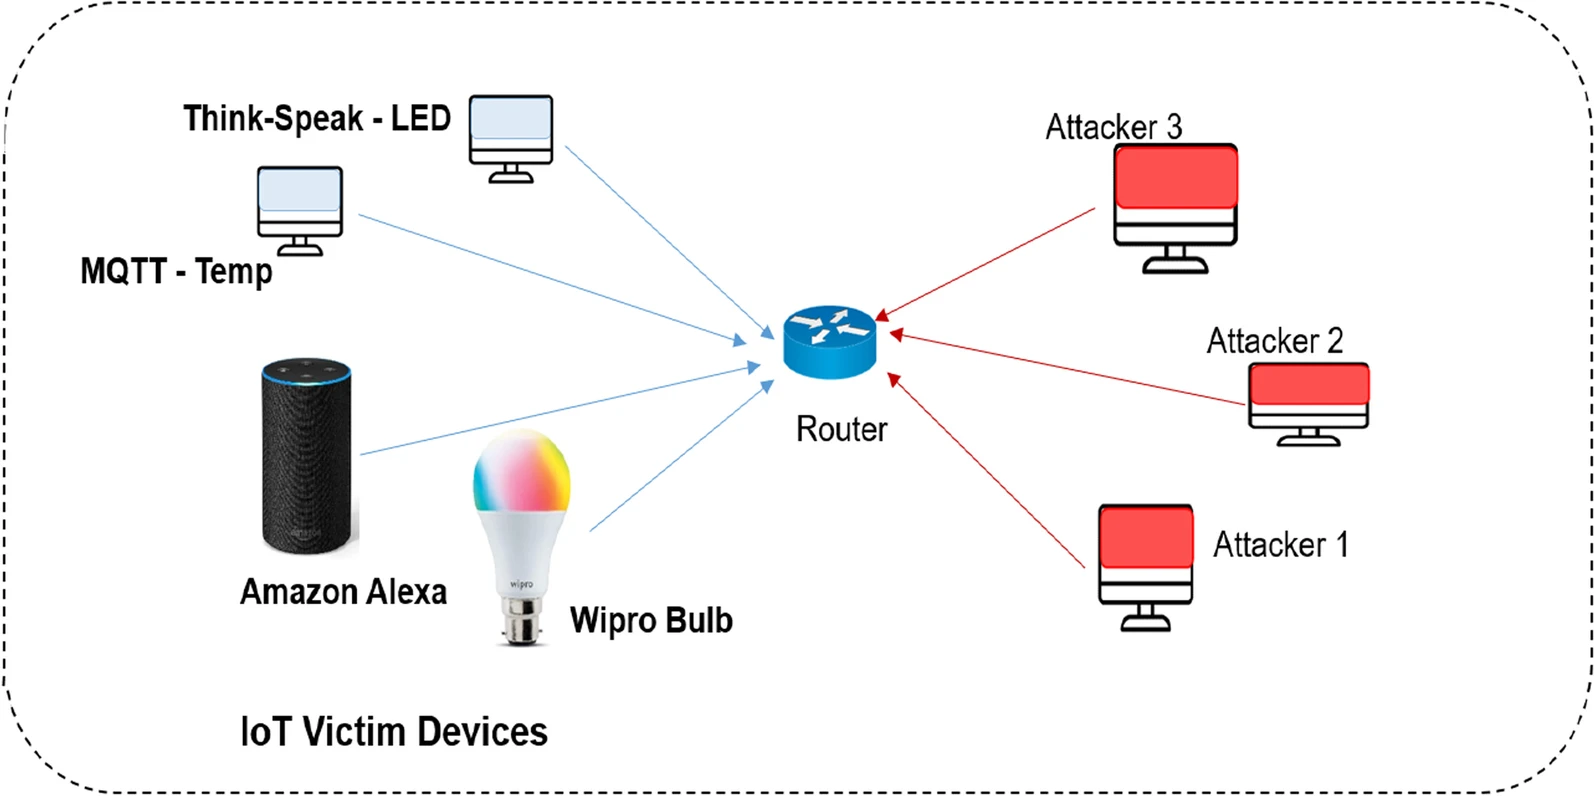

##**VARIABLES Y EJECUCIÓN**

---



In [ ]:
#al inicio poner todas True
installs_flag=True #normal True
imports_flag=True #normal True
installs_imports_flag=True #normal True
fetchdataset=False #normal False
analisis_eda=True #normal True
limpieza=False #True por 1ª vez,luego Falso de normal
clustering=True #normal True
data_prof=False #normal False,si quieres profiling html true
siluette_innertia=False #normal False (1h aprox alld2)
siluette_innertia2=False #normal False (1:30 aprox)
graficos_pca_clusters=False #normal False (30 min aprox alld2)
graficos_xscaled_clusters=False #normal False (30 min aprox alld2)
clasificacion_accdf_res=False #normal Falseç
alld2_et=True #True si extra trees es el modelo a usar por dataset alld2
best_params_xgb_et=False #normal False
shap_save=False #normal False
exportar_html_lime_caso=False #normal False
csv_eli5_weights=False #normal False

In [ ]:
random_state = 42
n_estimators=100

In [ ]:
from pathlib import Path

path = "./generated"
path = Path(path).expanduser().resolve().as_posix().rstrip("/") + "/"


##**INSTALS E IMPORTS**

---



###**INSTALLS**

---



In [ ]:
if path.startswith("/content/drive/"):
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError("El montaje de Drive requiere Google Colab. Fuera de Colab, elige una carpeta local o sincronizada en path.") from error
    drive.mount('/content/drive')

Path(path).mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


In [ ]:
if installs_imports_flag and installs_flag:
  !pip install scikit-fuzzy
  !pip install ucimlrepo
  !pip install ydata_profiling
  !pip install plotly
  !pip install seaborn
  !pip install ipywidgets
  !pip install openpyxl
  !pip install ipython-autotime
  !pip install xgboost
  !pip install shap
  !pip install lime
  !pip install imbalanced-learn
  !pip install gradio
  !pip install eli5

  #!pip install pycaret
  %load_ext autotime

  #si deja de haceme falta time:
  #%unload_ext autotime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.4/400.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=1ca65ed55373ceed2108d50c4e339f4e2538b43f0c2d428b9949606dfbba3459
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe8

###**IMPORTS**

---



In [ ]:
if installs_imports_flag and imports_flag:

  #general
  import csv
  import math
  import re
  import sys
  import time
  import warnings
  import os
  import json
  import html

  #datos
  import numpy as np
  import pandas as pd

  #graficos
  import matplotlib.pyplot as plt
  import seaborn as sns
  import plotly.express as px
  import plotly.graph_objects as go

  #notebook
  import ipywidgets as widgets
  from IPython.display import display,HTML,IFrame

  #eda
  from ydata_profiling import ProfileReport

  #preprocesado
  from sklearn import preprocessing
  from sklearn.preprocessing import (
      LabelEncoder,
      OneHotEncoder,
      StandardScaler,
      MinMaxScaler,
      RobustScaler,
      label_binarize
  )

  #tiempo
  import autotime
  def solo_segundos(timespan): #en segs
      return f"{timespan:.4f} s"
  if "inicio_ipynb" not in globals():
    inicio_ipynb = time.time()

  autotime.format_timespan = solo_segundos
  #si deja de haceme falta time:
  #%unload_ext autotime

  #imputacion
  from sklearn.impute import SimpleImputer

  #seleccion de variables
  from sklearn.feature_selection import SelectKBest, f_classif, f_regression

  #reduccion dimensionalidad
  from sklearn.decomposition import PCA

  #clustering
  from sklearn.cluster import KMeans
  from sklearn.cluster import AgglomerativeClustering
  from sklearn.cluster import DBSCAN
  import skfuzzy as fuzz

  #distancias y mediciones
  from scipy.spatial.distance import cdist

  #scipy stats
  from scipy.stats import chi2_contingency

  #modelos regresion
  from sklearn.linear_model import (
      LinearRegression,
      LogisticRegression,
      Ridge,
      Lasso,
      ElasticNet
  )
  from sklearn.tree import DecisionTreeRegressor
  from sklearn.ensemble import (
      ExtraTreesRegressor,
      RandomForestRegressor,
      GradientBoostingRegressor,
      AdaBoostRegressor
  )
  from sklearn.neighbors import KNeighborsRegressor
  from sklearn.svm import SVR
  from xgboost import XGBRegressor, plot_importance

  #modelos clasificacion
  from sklearn.tree import DecisionTreeClassifier
  from sklearn.ensemble import (
      RandomForestClassifier,
      ExtraTreesClassifier,
      GradientBoostingClassifier,
      AdaBoostClassifier
  )
  from sklearn.neighbors import KNeighborsClassifier
  from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
  from sklearn.naive_bayes import GaussianNB
  from sklearn.svm import SVC
  from xgboost import XGBClassifier
  from sklearn import model_selection

  #particion y validacion
  from sklearn.model_selection import (
      train_test_split,
      cross_val_score,
      GridSearchCV,
      RandomizedSearchCV,
      KFold,
      StratifiedKFold,
      RepeatedStratifiedKFold
  )

  #metricas
  import sklearn.metrics as sk_metrics
  from sklearn.metrics import (
      silhouette_score,
      davies_bouldin_score,
      calinski_harabasz_score,
      mean_squared_error,
      mean_absolute_error,
      r2_score,
      accuracy_score,
      precision_score,
      recall_score,
      f1_score,
      classification_report,
      confusion_matrix,
      roc_auc_score,
      roc_curve,
      adjusted_rand_score,
      normalized_mutual_info_score,
      homogeneity_score,
      completeness_score,
      v_measure_score,
      auc
  )

  #interpretabilidad xai
  import shap
  import lime
  from lime.lime_tabular import LimeTabularExplainer
  import pickle
  from imblearn.over_sampling import SMOTE
  import gradio as gr
  import eli5
  from eli5.sklearn import PermutationImportance

  #from pycaret.classification import *

  #datasets externos
  from ucimlrepo import fetch_ucirepo

  warnings.filterwarnings("ignore")

time: 56.2 s (started: 2026-03-22 13:02:47 +00:00)


###**IMPORTAMOS UN DATASET DE TRÁFICO NORMAL Y ATAQUES SIMULADOS EN UN LABORATORIO DE 2024**

In [ ]:
if fetchdataset:
  # fetch dataset
  rt_iot2022 = fetch_ucirepo(id=942)

  # data (as pandas dataframes)
  X = rt_iot2022.data.features
  y = rt_iot2022.data.targets

  # metadata
  print(rt_iot2022.metadata)

  # variable information
  print(rt_iot2022.variables)
  X.to_csv(path+'Xorg.csv')
  y.to_csv(path+'yorg.csv')
else:
  X=pd.read_csv(path+'Xorg.csv')
  y=pd.read_csv(path+'yorg.csv')

time: 3.48 s (started: 2026-03-22 13:03:44 +00:00)


In [ ]:
y

,Unnamed: 0,Attack_type
0,0,MQTT_Publish
1,1,MQTT_Publish
2,2,MQTT_Publish
3,3,MQTT_Publish
4,4,MQTT_Publish
...,...,...
123112,123112,NMAP_XMAS_TREE_SCAN
123113,123113,NMAP_XMAS_TREE_SCAN
123114,123114,NMAP_XMAS_TREE_SCAN
123115,123115,NMAP_XMAS_TREE_SCAN


time: 38.6 ms (started: 2026-03-22 13:03:47 +00:00)


In [ ]:
X.describe()

,Unnamed: 0,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,61558.000000,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,35540.960883,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,30779.000000,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,61558.000000,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,92337.000000,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,123116.000000,65535.000000,65389.000000,21728.335580,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


time: 403 ms (started: 2026-03-22 13:03:47 +00:00)


##**DEFINICIÓN  Y EXPLICACIÓN DE VARIABLES**

---



Es tráfico de red IoT bidireccional normal o ataques simulados.

**fwd** - Dirección forward: origen→destino (cliente→servidor normalmente)

**bwd** - Dirección backward: destino→origen (servidor→cliente normalmente)

**flow** - Métricas globales del flujo (fwd+bwd)

**pkts** - Paquetes (conteos / ritmo)

**data_pkts** - Paquetes con payload (datos útiles), no solo control TCP

**payload** - Bytes de datos útiles (sin cabeceras) y su resumen (total/media/etc.)

**header_size** - Bytes de cabecera (IP/TCP/UDP) observados/sumados en fwd/bwd

**iat** - Inter-Arrival Time: tiempo entre paquetes (ritmo temporal)

**active** - Periodos activos del flujo (ráfagas)

**inactive** - Periodos inactivos del flujo (pausas) (idle renombrado)

**subflow** - Flujo segmentado en bloques internos; se miden paquetes/bytes por segmento

**bulk** - Transferencias en bloque (ráfagas grandes continuas) y su tasa

**window**- Ventana TCP (control de flujo): “cuántos bytes más puedo recibir”

**SYN** - Inicio de conexión (handshake)

**ACK** - Confirmación de recepción (acknowledgement)

**FIN** - Cierre limpio de conexión

**RST** - Reset/abort (puerto cerrado o cierre brusco)

**PSH** - Entrega inmediata a la aplicación (push)

**URG** - Datos urgentes (raro)

**ECE/CWR** - Flags TCP de congestión (ECN): ECE avisa congestión, CWR confirma reducción de envío

**id_src_port** - Puerto de origen (0–65535)

**id_dst_port**- Puerto de destino (0–65535)

**proto** - Protocolo (tcp, udp, icmp)

**service** - Servicio detectado (dns, mqtt, http, ssl, “-” desconocido)

**down_up_ratio** - Ratio entre tráfico de vuelta y de ida (según convención del extractor)

**flow_duration** - Duración del flujo (tiempo total)

**Attack_type** - Etiqueta: tipo de ataque o patrón normal (clase)

**IMAGEN GENERADA EXPLICANDO LOS CONCEPTOS**

---



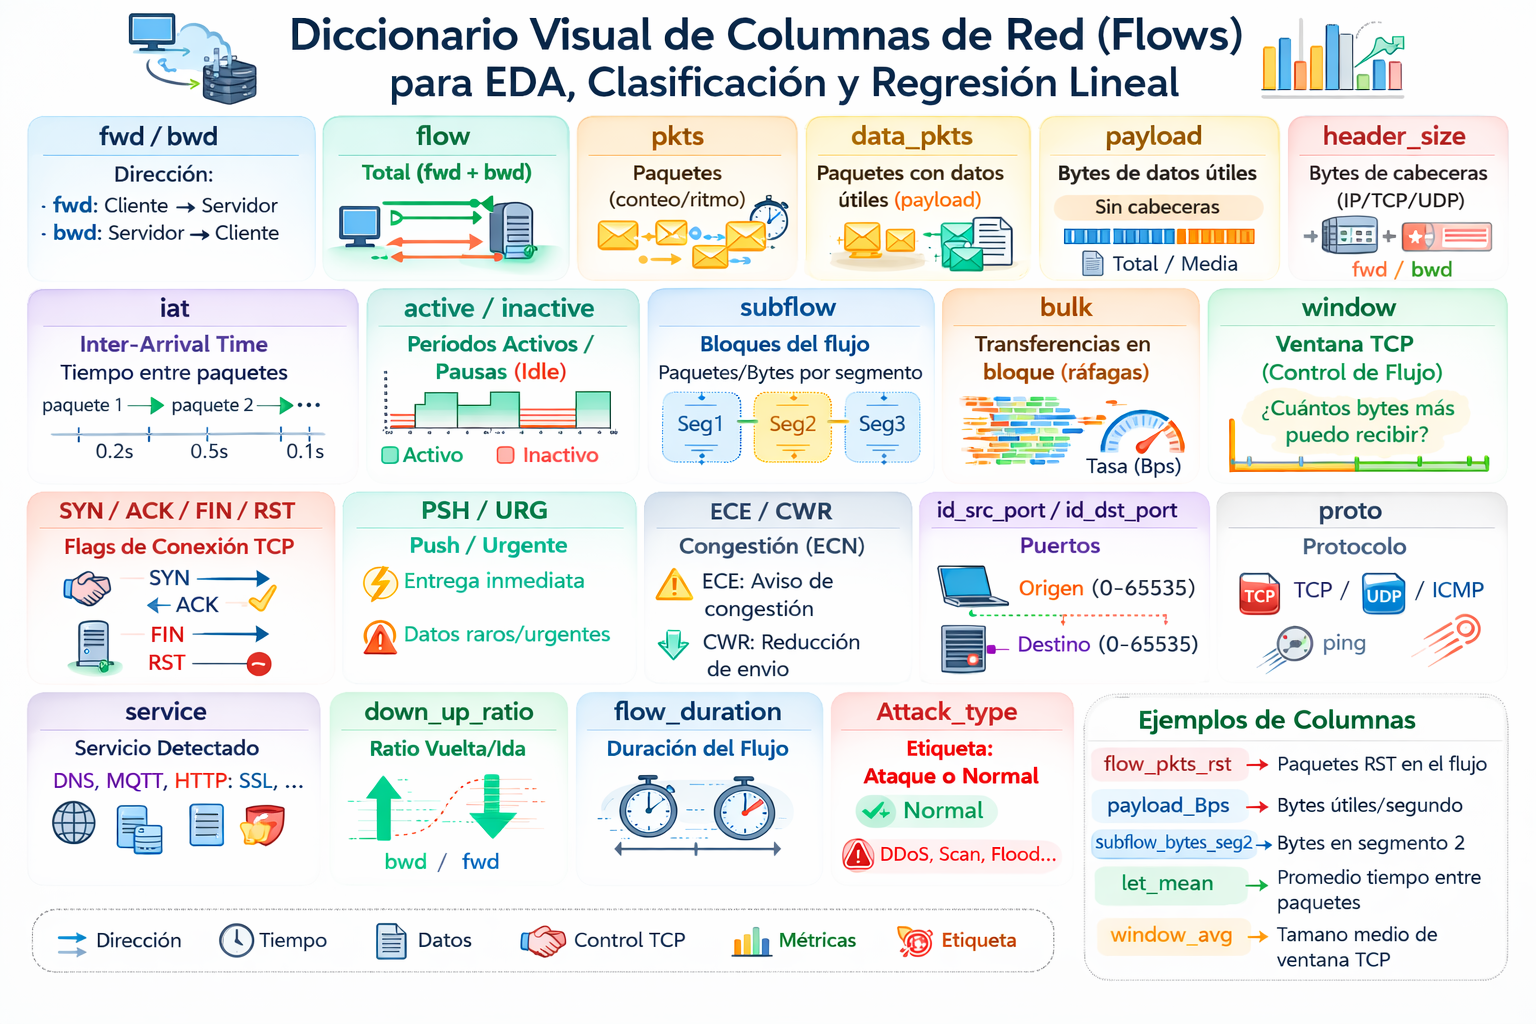

##**LIMPIEZA, SELECCIÓN DE TARGETS Y PREPARACIÓN DEL DATASET**

---



In [ ]:
print(f"Carpeta de datos y resultados: {path}")


time: 480 µs (started: 2026-03-22 13:03:47 +00:00)


###**JUNTAMOS TODO Y RENOMBRAMOS PARA INTERPRETABILIDAD**

In [ ]:
df= pd.concat([X, y], axis=1)
df2=dfd=df.copy()
df.head()

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Unnamed: 0,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,0,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,1,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,2,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,3,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,4,MQTT_Publish


time: 121 ms (started: 2026-03-22 13:03:48 +00:00)


In [ ]:
rename_map = {
  "id.orig_p": "id_src_port",
  "id.resp_p": "id_dst_port",
  "proto": "protocol",
  "service": "service",
  "flow_duration": "flow_duration",

  "fwd_pkts_tot": "fwd_pkts_tot",
  "bwd_pkts_tot": "bwd_pkts_tot",
  "fwd_data_pkts_tot": "fwd_data_pkts_tot",
  "bwd_data_pkts_tot": "bwd_data_pkts_tot",

  "fwd_pkts_per_sec": "fwd_pkts_per_sec",
  "bwd_pkts_per_sec": "bwd_pkts_per_sec",
  "flow_pkts_per_sec": "flow_pkts_per_sec",

  "down_up_ratio": "down_up_ratio",

  "fwd_header_size_tot": "fwd_header_size_tot",
  "fwd_header_size_min": "fwd_header_size_min",
  "fwd_header_size_max": "fwd_header_size_max",
  "bwd_header_size_tot": "bwd_header_size_tot",
  "bwd_header_size_min": "bwd_header_size_min",
  "bwd_header_size_max": "bwd_header_size_max",

  "flow_FIN_flag_count": "flow_FIN_flag_count",
  "flow_SYN_flag_count": "flow_SYN_flag_count",
  "flow_RST_flag_count": "flow_RST_flag_count",
  "fwd_PSH_flag_count": "fwd_PSH_flag_count",
  "bwd_PSH_flag_count": "bwd_PSH_flag_count",
  "flow_ACK_flag_count": "flow_ACK_flag_count",
  "fwd_URG_flag_count": "fwd_URG_flag_count",
  "bwd_URG_flag_count": "bwd_URG_flag_count",
  "flow_CWR_flag_count": "flow_CWR_flag_count",
  "flow_ECE_flag_count": "flow_ECE_flag_count",

  "fwd_pkts_payload.min": "fwd_pkts_payload_min",
  "fwd_pkts_payload.max": "fwd_pkts_payload_max",
  "fwd_pkts_payload.tot": "fwd_pkts_payload_tot",
  "fwd_pkts_payload.avg": "fwd_pkts_payload_avg",
  "fwd_pkts_payload.std": "fwd_pkts_payload_std",

  "bwd_pkts_payload.min": "bwd_pkts_payload_min",
  "bwd_pkts_payload.max": "bwd_pkts_payload_max",
  "bwd_pkts_payload.tot": "bwd_pkts_payload_tot",
  "bwd_pkts_payload.avg": "bwd_pkts_payload_avg",
  "bwd_pkts_payload.std": "bwd_pkts_payload_std",

  "flow_pkts_payload.min": "flow_pkts_payload_min",
  "flow_pkts_payload.max": "flow_pkts_payload_max",
  "flow_pkts_payload.tot": "flow_pkts_payload_tot",
  "flow_pkts_payload.avg": "flow_pkts_payload_avg",
  "flow_pkts_payload.std": "flow_pkts_payload_std",

  "fwd_iat.min": "fwd_iat_min",
  "fwd_iat.max": "fwd_iat_max",
  "fwd_iat.tot": "fwd_iat_tot",
  "fwd_iat.avg": "fwd_iat_avg",
  "fwd_iat.std": "fwd_iat_std",

  "bwd_iat.min": "bwd_iat_min",
  "bwd_iat.max": "bwd_iat_max",
  "bwd_iat.tot": "bwd_iat_tot",
  "bwd_iat.avg": "bwd_iat_avg",
  "bwd_iat.std": "bwd_iat_std",

  "flow_iat.min": "flow_iat_min",
  "flow_iat.max": "flow_iat_max",
  "flow_iat.tot": "flow_iat_tot",
  "flow_iat.avg": "flow_iat_avg",
  "flow_iat.std": "flow_iat_std",

  "payload_bytes_per_second": "payload_BPS",

  "fwd_subflow_pkts": "fwd_subflow_pkts",
  "bwd_subflow_pkts": "bwd_subflow_pkts",
  "fwd_subflow_bytes": "fwd_subflow_bytes",
  "bwd_subflow_bytes": "bwd_subflow_bytes",

  "fwd_bulk_bytes": "fwd_bulk_bytes",
  "bwd_bulk_bytes": "bwd_bulk_bytes",
  "fwd_bulk_packets": "fwd_bulk_packets",
  "bwd_bulk_packets": "bwd_bulk_packets",
  "fwd_bulk_rate": "fwd_bulk_rate",
  "bwd_bulk_rate": "bwd_bulk_rate",

  "active.min": "active_min",
  "active.max": "active_max",
  "active.tot": "active_tot",
  "active.avg": "active_avg",
  "active.std": "active_std",

  "idle.min": "inactive_min",
  "idle.max": "inactive_max",
  "idle.tot": "inactive_tot",
  "idle.avg": "inactive_avg",
  "idle.std": "inactive_std",

  "fwd_init_window_size": "fwd_init_window_size",
  "bwd_init_window_size": "bwd_init_window_size",
  "fwd_last_window_size": "fwd_last_window_size",

  "Attack_type": "attack_type"
}

df = df.rename(columns=rename_map)

time: 97.5 ms (started: 2026-03-22 13:03:48 +00:00)


###**INFORMACIÓN Y ELIMINACIÓN DE DUPLICADOS Y NULOS**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 86 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             123117 non-null  int64  
 1   id_src_port            123117 non-null  int64  
 2   id_dst_port            123117 non-null  int64  
 3   protocol               123117 non-null  object 
 4   service                123117 non-null  object 
 5   flow_duration          123117 non-null  float64
 6   fwd_pkts_tot           123117 non-null  int64  
 7   bwd_pkts_tot           123117 non-null  int64  
 8   fwd_data_pkts_tot      123117 non-null  int64  
 9   bwd_data_pkts_tot      123117 non-null  int64  
 10  fwd_pkts_per_sec       123117 non-null  float64
 11  bwd_pkts_per_sec       123117 non-null  float64
 12  flow_pkts_per_sec      123117 non-null  float64
 13  down_up_ratio          123117 non-null  float64
 14  fwd_header_size_tot    123117 non-nu

In [ ]:
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df.isnull().sum())

0
0
Unnamed: 0              0
id_src_port             0
id_dst_port             0
protocol                0
service                 0
                       ..
fwd_init_window_size    0
bwd_init_window_size    0
fwd_last_window_size    0
Unnamed: 0              0
attack_type             0
Length: 86, dtype: int64
time: 645 ms (started: 2026-03-22 13:03:48 +00:00)


In [ ]:
df=df.drop_duplicates()
print(df.duplicated().sum())

0
time: 1.99 s (started: 2026-03-22 13:03:49 +00:00)


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,61558.000000,3.554096e+04,0.0,30779.000000,61558.000000,92337.000000,1.231160e+05
id_src_port,123117.0,34639.258738,1.907062e+04,0.0,17702.000000,37221.000000,50971.000000,6.553500e+04
id_dst_port,123117.0,1014.305092,5.256372e+03,0.0,21.000000,21.000000,21.000000,6.538900e+04
flow_duration,123117.0,3.809566,1.300054e+02,0.0,0.000001,0.000004,0.000005,2.172834e+04
fwd_pkts_tot,123117.0,2.268826,2.233656e+01,0.0,1.000000,1.000000,1.000000,4.345000e+03
...,...,...,...,...,...,...,...,...
inactive_std,123117.0,45501.831691,1.091361e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,123117.0,6118.905123,1.871631e+04,0.0,64.000000,64.000000,64.000000,6.553500e+04
bwd_init_window_size,123117.0,2739.776018,1.001885e+04,0.0,0.000000,0.000000,0.000000,6.553500e+04
fwd_last_window_size,123117.0,751.647514,6.310184e+03,0.0,64.000000,64.000000,64.000000,6.553500e+04


time: 1.89 s (started: 2026-03-22 13:03:51 +00:00)


In [ ]:
df.columns

Index(['Unnamed: 0', 'id_src_port', 'id_dst_port', 'protocol', 'service',
       'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot',
       'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec',
       'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot',
       'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot',
       'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count',
       'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count',
       'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count',
       'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count',
       'fwd_pkts_payload_min', 'fwd_pkts_payload_max', 'fwd_pkts_payload_tot',
       'fwd_pkts_payload_avg', 'fwd_pkts_payload_std', 'bwd_pkts_payload_min',
       'bwd_pkts_payload_max', 'bwd_pkts_payload_tot', 'bwd_pkts_payload_avg',
       'bwd_pkts_payload_std', 'flow_pkts_payload_min',
       'flow_pkts_payload_max', 'flow_pkts_p

time: 18.6 ms (started: 2026-03-22 13:03:52 +00:00)


In [ ]:
df['pkts_tot'] = df['fwd_pkts_tot'] + df['bwd_pkts_tot']

time: 13.2 ms (started: 2026-03-22 13:03:52 +00:00)


###**PREPARACIÓN DEL ANÁLISIS**

**Las únicas columnas que cambiamos para analizar con getdummies son protocol, service y atack_type que será nuestro target.**

**Y pondremos como binario las columnas de dos valores como genero, hackaton participation y placement status xa evitar colinealidad con dummies y para hacerlo mucho más sencillo, ya que 0 o 1 no afecta. Sería lo mismo que poner dos columnas, ya que el 0 dejaría solo en regresión logística/lineal la el coeficiente normal, y el 1 simplemente añadiría un desplazamiento, así que sería completamente igual que si hacemos dos desplazamientos distintos.**

####**GET DUMMIES**

In [ ]:
df["protocol"].copy().unique()


array(['tcp', 'udp', 'icmp'], dtype=object)

time: 59.6 ms (started: 2026-03-22 13:03:52 +00:00)


In [ ]:
if analisis_eda or limpieza:
  df['protocolstr']=df['protocol']
  df = pd.get_dummies(df, columns=['protocol'], dtype=int)

time: 291 ms (started: 2026-03-22 13:03:53 +00:00)


In [ ]:
if analisis_eda or limpieza:
  df["service"] = df["service"].replace("-", "nsq")
  #map!=replace
df["service"].copy().unique()

array(['mqtt', 'nsq', 'http', 'dns', 'ntp', 'ssl', 'dhcp', 'irc', 'ssh',
       'radius'], dtype=object)

time: 116 ms (started: 2026-03-22 13:03:53 +00:00)


In [ ]:
if analisis_eda or limpieza:
  df["service_str"]=df["service"]
  df = pd.get_dummies(df, columns=['service'], dtype=int)

time: 461 ms (started: 2026-03-22 13:03:53 +00:00)


In [ ]:
df['attack_type'].copy().unique()


array(['MQTT_Publish', 'Thing_Speak', 'Wipro_bulb', 'ARP_poisioning',
       'DDOS_Slowloris', 'DOS_SYN_Hping', 'Metasploit_Brute_Force_SSH',
       'NMAP_FIN_SCAN', 'NMAP_OS_DETECTION', 'NMAP_TCP_scan',
       'NMAP_UDP_SCAN', 'NMAP_XMAS_TREE_SCAN'], dtype=object)

time: 51.9 ms (started: 2026-03-22 13:03:54 +00:00)


In [ ]:
if analisis_eda or limpieza:
  scan = {"NMAP_FIN_SCAN", "NMAP_OS_DETECTION", "NMAP_TCP_scan","NMAP_UDP_SCAN", "NMAP_XMAS_TREE_SCAN"}
  dos_ddos = {"DOS_SYN_Hping", "DDOS_Slowloris"}
  arp = {"ARP_poisioning"}
  normal = {"MQTT_Publish", "Thing_Speak", "Wipro_bulb"}
  bruteforce = {"Metasploit_Brute_Force_SSH"}

  def atk(x):
      if x in normal:     return 0  # normal
      if x in scan:       return 1  # escaneo
      if x in dos_ddos:   return 2  # DoS/DDoS
      if x in arp:        return 3  # ARP/MITM
      if x in bruteforce: return 4  # fuerza bruta
      return 5            # ??
  def atk2(x):
      if x==0:  return 'normal'
      if x==1:  return 'scan'
      if x==2:  return 'dos_ddos'
      if x==3:  return 'arp'
      if x==4: return 'bruteforce'
      if x==5: return 'nsq'
  df["attack_group"] = df["attack_type"].apply(atk)
  df["attack_groupstr"]=df['attack_group'].apply(atk2)
  df["attack_flag"]  = (~df["attack_type"].isin(normal)).astype(int)
  df["attack_type_src"] = df["attack_type"]

  #dummies
  df = pd.get_dummies(df, columns=["attack_type"], dtype=int)
  df.rename(columns={"attack_type_src": "attack_type"}, inplace=True)#y vuelvo

time: 577 ms (started: 2026-03-22 13:03:54 +00:00)


In [ ]:
df['attack_type']

,attack_type
0,MQTT_Publish
1,MQTT_Publish
2,MQTT_Publish
3,MQTT_Publish
4,MQTT_Publish
...,...
123112,NMAP_XMAS_TREE_SCAN
123113,NMAP_XMAS_TREE_SCAN
123114,NMAP_XMAS_TREE_SCAN
123115,NMAP_XMAS_TREE_SCAN


time: 20.6 ms (started: 2026-03-22 13:03:54 +00:00)


####**CAMBIAR TIEMPO DE LAS COLUMNAS A SEGUNDOS**

Cambiar todo tiempo de microsegundos a segundos menos la unica que esta en segundos (flow_duration)

In [ ]:
if analisis_eda or limpieza:
  time_cols_pico= [
      "fwd_iat_min", "fwd_iat_max", "fwd_iat_tot", "fwd_iat_avg", "fwd_iat_std", "bwd_iat_min",
      "bwd_iat_max", "bwd_iat_tot", "bwd_iat_avg", "bwd_iat_std", "flow_iat_std", "active_std",
      "inactive_min", "inactive_max", "inactive_tot", "inactive_avg", "inactive_std",]
  df[time_cols_pico] = df[time_cols_pico] / 1_000_000
  cols_s = [
      "flow_iat_min", "flow_iat_max", "flow_iat_tot", "flow_iat_avg",
      "active_min", "active_max", "active_tot", "active_avg","flow_duration",]

  df[time_cols_pico + cols_s].describe().T

time: 316 ms (started: 2026-03-22 13:03:54 +00:00)


** *texto en cursiva*Podemos observar que hay muchos ceros, normalmente puede ser porque hay muy pocos paquetes, en este caso, o se redondea directamente a cero porque el tiempo es casi nulo. Por ejemplo, un escaneo a puerto cerrado.**


###**EXPORTAR DATASET ORIGINAL LIMPIO Y ORDENADO**

In [ ]:
if limpieza:
  df.to_csv(os.path.join(path, "df_org_limpio.csv"), index=False)
else:
  df=pd.read_csv(os.path.join(path, "df_org_limpio.csv"))

time: 4.29 s (started: 2026-03-22 13:03:55 +00:00)


##**ANÁLISIS EDA DEL DATASET**

---



####**DATA PROFILING A HTML**

In [ ]:
ruta_profile = os.path.join(path, "profiling_report.html")
if data_prof:
    profile = ProfileReport(df, title="Pandas Profiling Report")
    profile.to_file(ruta_profile)
    display(HTML(filename=ruta_profile))
else:
    try:
        if os.path.exists(ruta_profile):
            display(HTML(filename=ruta_profile))
        else:
            print("El archivo profiling_report.html no existe todavía en:")
            print(ruta_profile)
    except Exception as e:
        print(f"No se pudo cargar el HTML del profiling: {e}")

Output hidden; open in https://colab.research.google.com to view.

####**DIFERENTES COLUMNAS ANÁLISIS DESORDENADO**

---



In [ ]:
if analisis_eda:
  cols=[]
  for col in df.columns:
      cols.append(col)
  cols

time: 10.1 ms (started: 2026-03-22 13:04:00 +00:00)


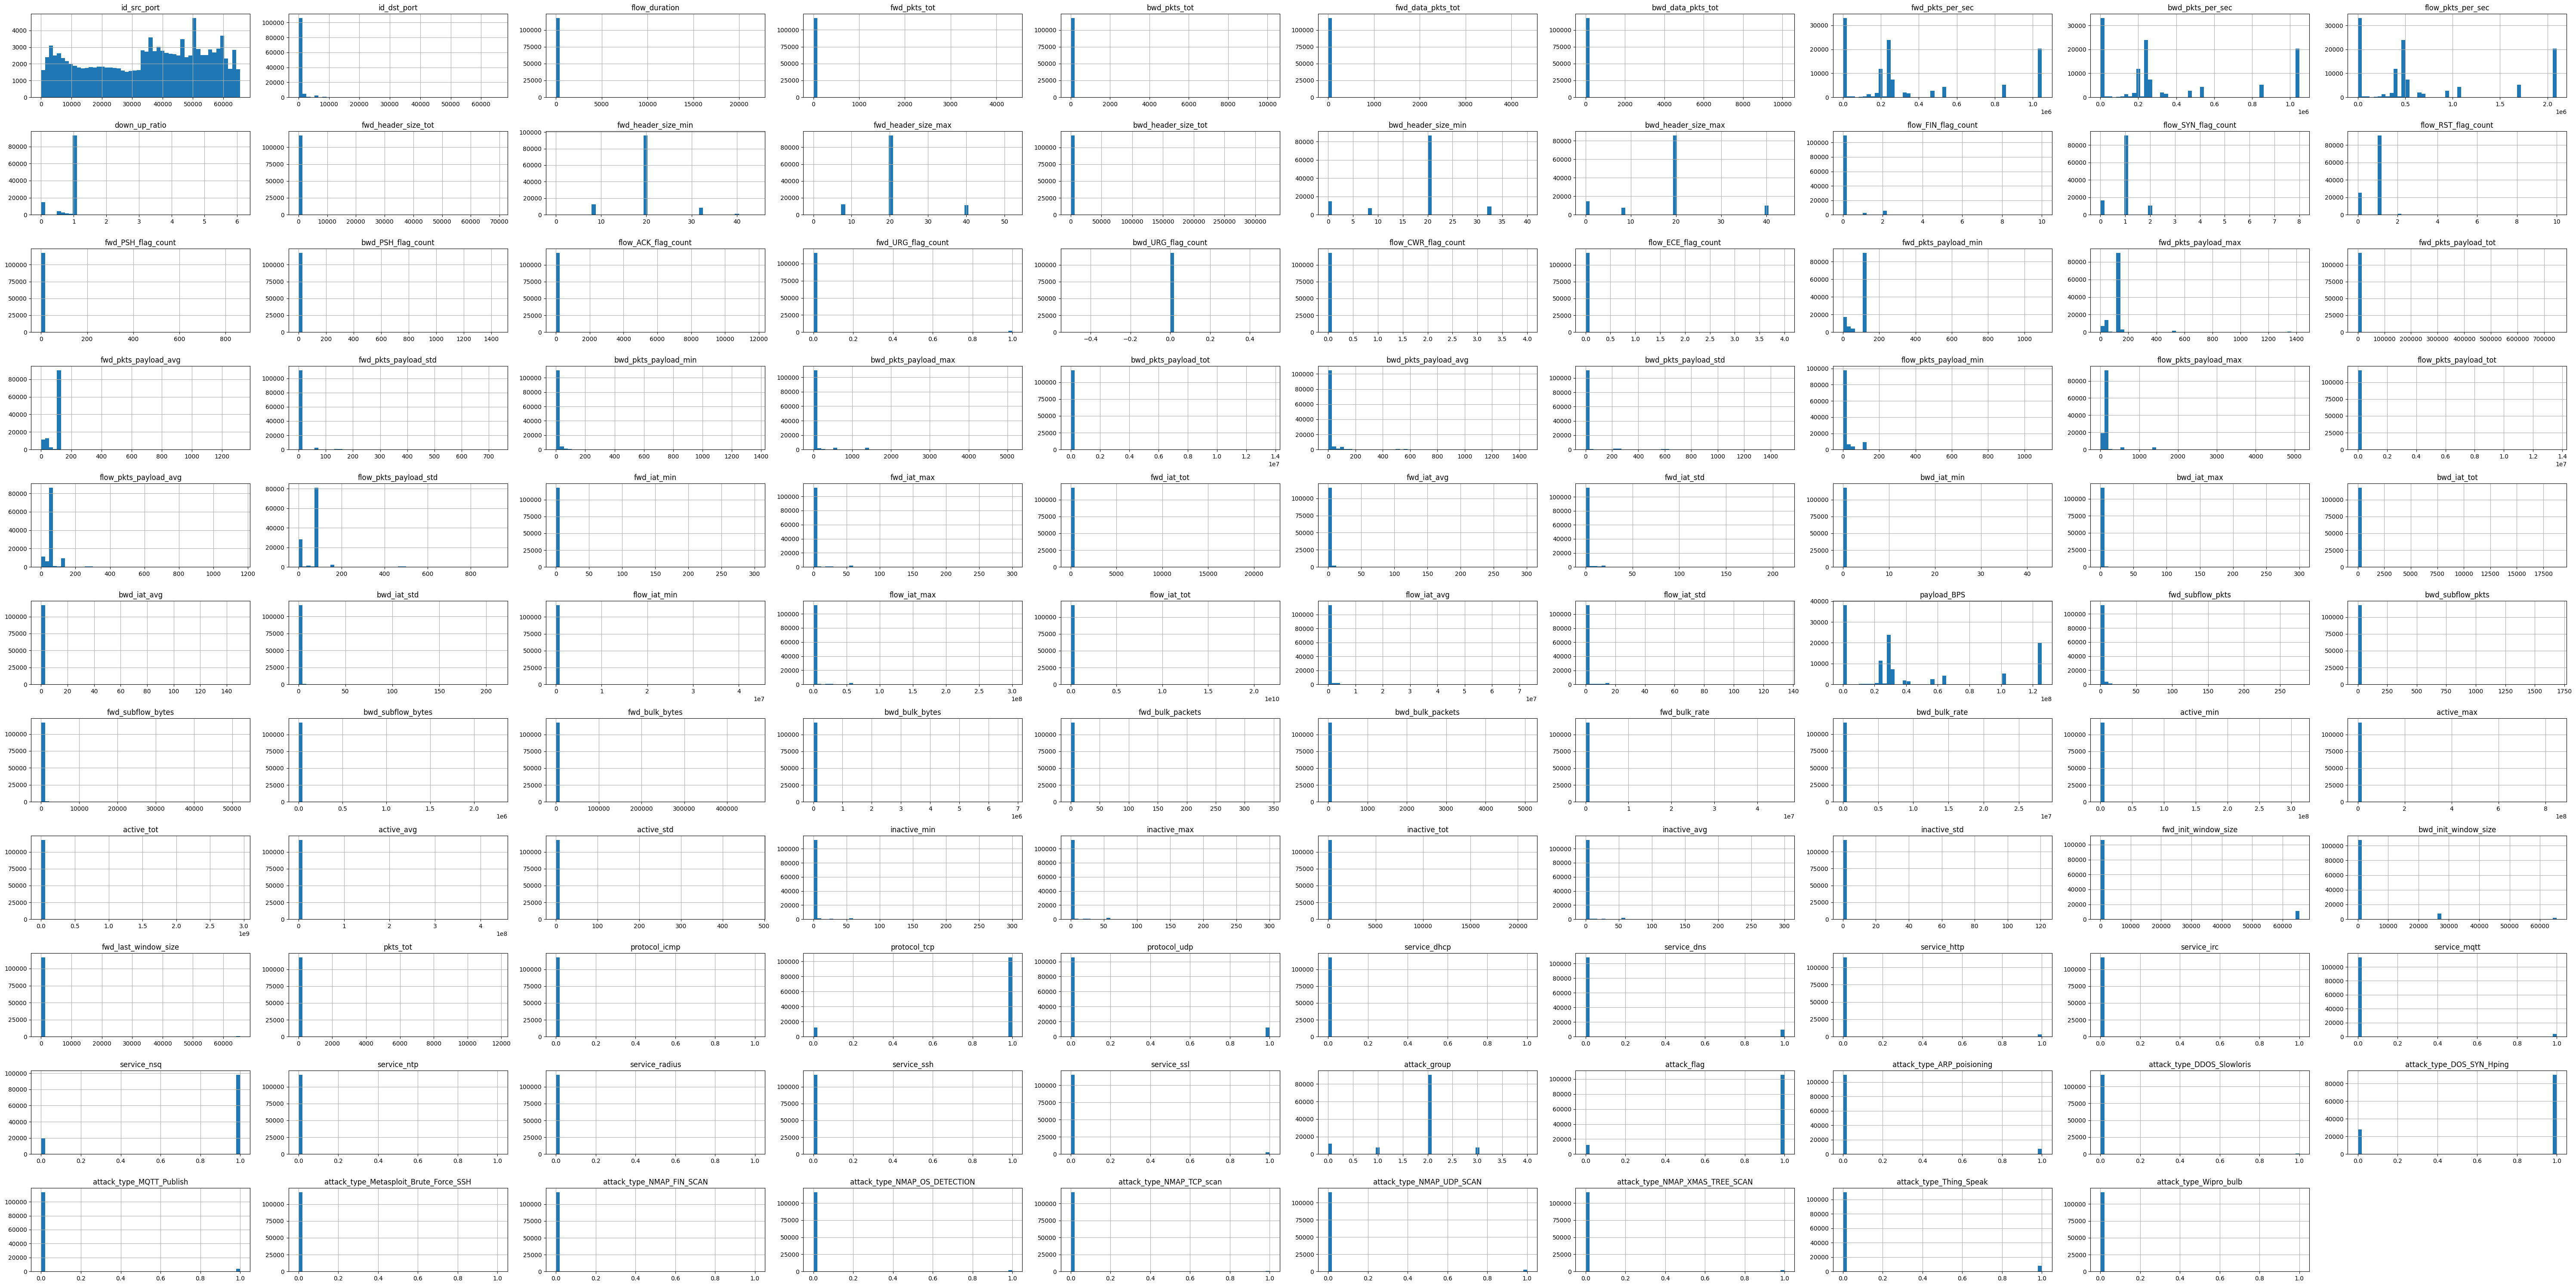

time: 45.9 s (started: 2026-03-22 13:04:00 +00:00)


In [ ]:
if analisis_eda:
  df[cols].hist(figsize=(60,30), bins=50)
  plt.tight_layout()
  plt.show()

**Parece haber la mayoria de ataques (2) y 5/& paquetes eran ataques simulados, los cuales se hacian sobre todo en los bien conocidos (0-1024) y privados (49129-65535), ahora separaré por cuartiles ciertos flows para crear una especie de bidireccoionalidad entre paquetes y determinar el flujo con estos.**

###**PORPORCIÓN DE ATAQUES Y CONCLUSIONES A FUTURO**

---




**Se observa cierta dominancia de los ataques DDoS, consistiendo el 77% del tráfico del dataset. Se concluye que la mejor acción a tomar será igualar con una semilla y filas las otras opciones de ataque solo después del análisis completo del dataset, para que los ataques DDoS no sean más que los demás, ni monopolizando ni sesgando el clustering y aprendizaje supervisado.**

                 count  percent
attack_groupstr                
dos_ddos         90622   76.849
normal           12015   10.189
arp               7625    6.466
scan              7624    6.465
bruteforce          36    0.031


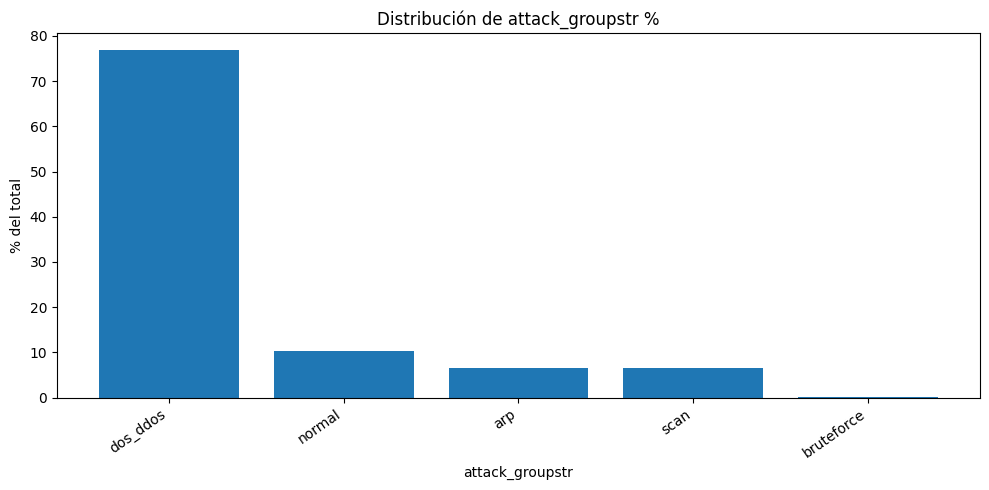

time: 214 ms (started: 2026-03-22 13:04:46 +00:00)


In [ ]:
if analisis_eda:
  def proptrafico(df, col="attack_groupstr", top_n=None, dropna=False):
      s = df[col]
      if dropna:
          s = s.dropna()

      counts = s.value_counts(dropna=not dropna)
      perc = (counts / counts.sum() * 100).round(3)

      dist = pd.DataFrame({
          "count": counts,
          "percent": perc
      })

      if top_n is not None and len(dist) > top_n: #al final no hay otros
          top = dist.head(top_n).copy()
          rest = dist.iloc[top_n:]
          otros = pd.DataFrame(
              {"count": [rest["count"].sum()], "percent": [rest["percent"].sum()]},
              index=["OTROS"]
          )
          dist_plot = pd.concat([top, otros], axis=0)
      else:
          dist_plot = dist

      print(dist)
      plt.figure(figsize=(10, 5))
      plt.bar(dist_plot.index.astype(str), dist_plot["percent"].values)
      plt.ylabel("% del total")
      plt.xlabel(col)
      plt.title(f"Distribución de {col} %")
      plt.xticks(rotation=35, ha="right")
      plt.tight_layout()
      plt.show()

      return dist

  dist_attack = proptrafico(df, col="attack_groupstr", top_n=None)

###**CREACIÓN DE BIDIRECCIONALIDAD PARA LOS PAQUETES CON CUARTILES PARA EL ANÁLISIS**

---



**Tenemos el flujo de los diferentes paquetes en varios intervalos de tiempo, pero no sabemos cuánto se ha mandado unidireccionalmente, bidireccionalmente o no se ha mandado. Para ello, crearemos con los cuartiles de los paquetes totales, bidireccionalidad, cogiendo hasta el 75% para unidireccionalidad y todo lo que se sobreponga a eso será bidireccional. Para las cuales haya columnas que especifiquen realmente el flujo de un lado a otro unidireccionalmente, simplemente se interpolarán a una nueva columna llamada flujo, que será la suma de las direcciones unidireccionales de cliente a servidor y servidor a cliente.**

In [ ]:
if analisis_eda:
  def direccion_q012(
      df,
      base_flow_cols=None,
      q=0.75,
      suffix="_q012",
      add_flow_psh_urg=True
  ):
      """
        0: count == 0
        1: 0 < count <= quantile(q) calculado sobre valores > 0
        2: count  > quantile(q) calculado sobre valores > 0
        crea flow_PSH_flag_count = fwd_PSH + bwd_PSH if true
        crea flow_URG_flag_count = fwd_URG + bwd_URG if true
      """

      #suma fwd y bwd de urg y psh xa flow
      if add_flow_psh_urg:
          if "flow_PSH_flag_count" not in df.columns:
              df["flow_PSH_flag_count"] = df["fwd_PSH_flag_count"].fillna(0) + df["bwd_PSH_flag_count"].fillna(0)
          if "flow_URG_flag_count" not in df.columns:
              df["flow_URG_flag_count"] = df["fwd_URG_flag_count"].fillna(0) + df["bwd_URG_flag_count"].fillna(0)

      #todos los flows
      if base_flow_cols is None:
          base_flow_cols = [
              "flow_FIN_flag_count",
              "flow_SYN_flag_count",
              "flow_RST_flag_count",
              "flow_PSH_flag_count",
              "flow_URG_flag_count",
              "flow_ACK_flag_count",
              "flow_CWR_flag_count",
              "flow_ECE_flag_count",
          ]

      new_cols = []

      #cols a 012
      for col in base_flow_cols:
          s = df[col].fillna(0)

          pos = s[s > 0]
          if len(pos) == 0:
              out = pd.Series(0, index=df.index)
          else:
              thr = pos.quantile(q)
              out = np.select(
                  [s.eq(0), s.le(thr)],
                  [0, 1],
                  default=2
              ).astype(int)

          new_name = col + suffix
          df[new_name] = out
          new_cols.append(new_name)

      return new_cols
  pkts_types_q012 = direccion_q012(df, q=0.75, suffix="_q012", add_flow_psh_urg=True)

time: 45.7 ms (started: 2026-03-22 13:04:46 +00:00)


In [ ]:
pkts_types = ['flow_FIN_flag_count',
 'flow_SYN_flag_count',
 'flow_RST_flag_count',
  'flow_PSH_flag_count',
 'flow_URG_flag_count',
 'flow_ACK_flag_count',
 'flow_CWR_flag_count',
 'flow_ECE_flag_count']

#SI SON 2 O 1 COMRPOBAREMOS CUAL  SON LOS TIPOS DE ATAQUES DE CADA UNO Y EN CASO DE QUE SEAN ATAQUES(attack_flag=1)

time: 936 µs (started: 2026-03-22 13:04:46 +00:00)


In [ ]:
if analisis_eda:
  df[pkts_types_q012].agg(['min','max','nunique']).T.sort_values('max', ascending=False).head(15)

time: 28.4 ms (started: 2026-03-22 13:04:46 +00:00)


In [ ]:
if analisis_eda:
  df[pkts_types].agg(['min','max','nunique']).T.sort_values('max', ascending=False).head(15)

time: 19.6 ms (started: 2026-03-22 13:04:46 +00:00)


###**ANÁLISIS POR ATAQUE Y DIRECCIÓN DEL TIPO DE PAQUETE**

---



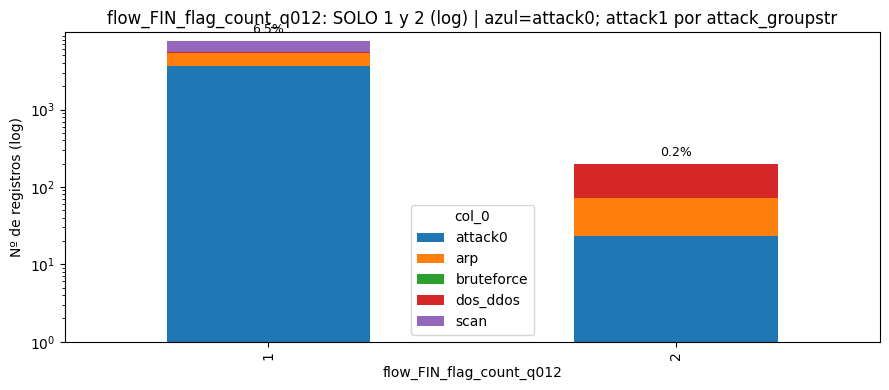

flow_FIN_flag_count_q012: % total df -> 1: 6.50% | 2: 0.17%



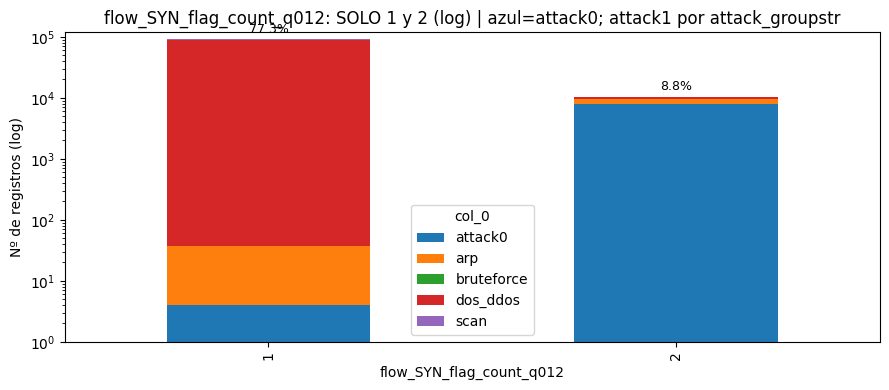

flow_SYN_flag_count_q012: % total df -> 1: 77.27% | 2: 8.80%



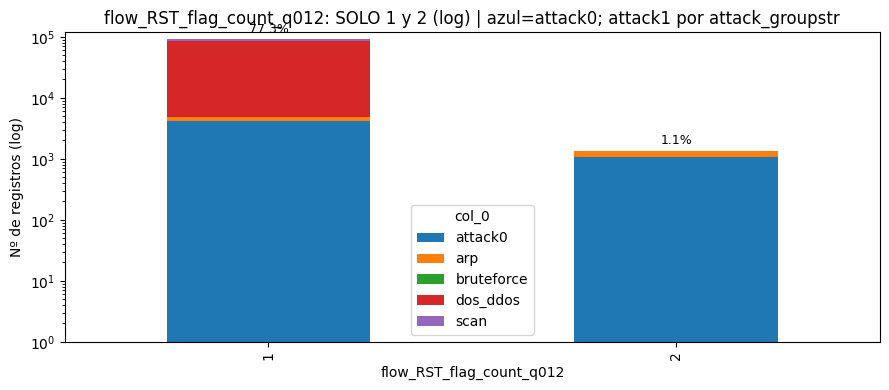

flow_RST_flag_count_q012: % total df -> 1: 77.32% | 2: 1.13%



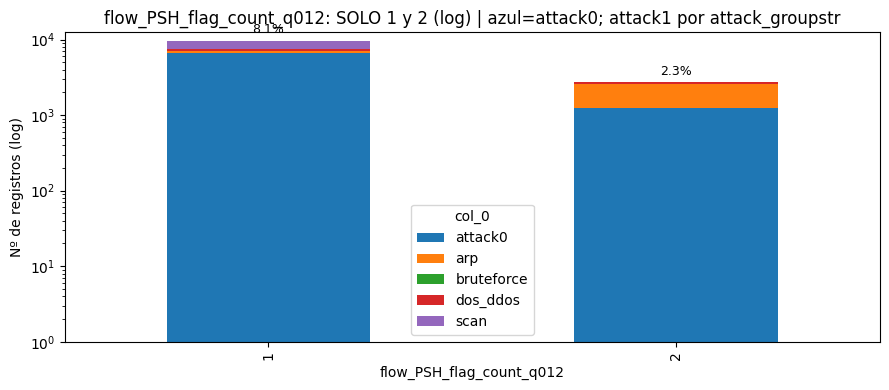

flow_PSH_flag_count_q012: % total df -> 1: 8.14% | 2: 2.30%



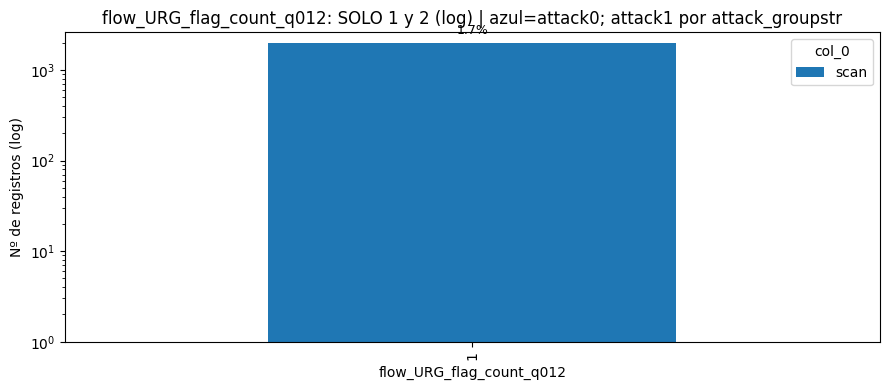

flow_URG_flag_count_q012: % total df -> 1: 1.70% | 2: 0.00%



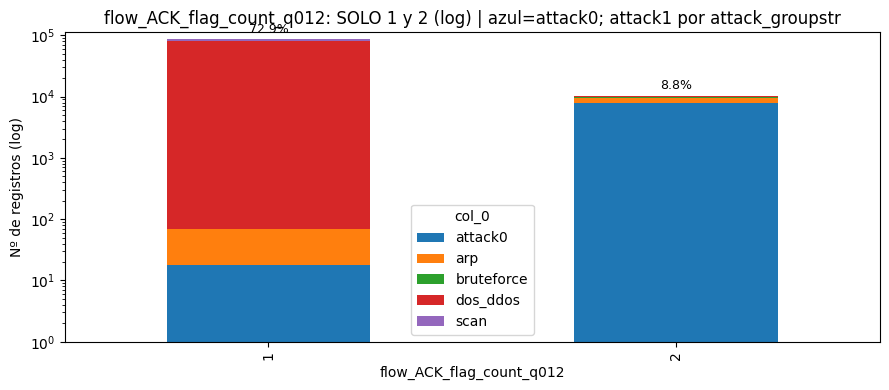

flow_ACK_flag_count_q012: % total df -> 1: 72.92% | 2: 8.77%



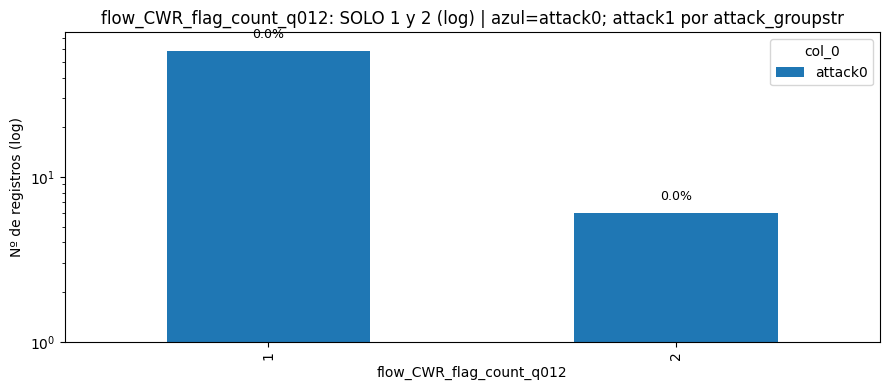

flow_CWR_flag_count_q012: % total df -> 1: 0.05% | 2: 0.01%



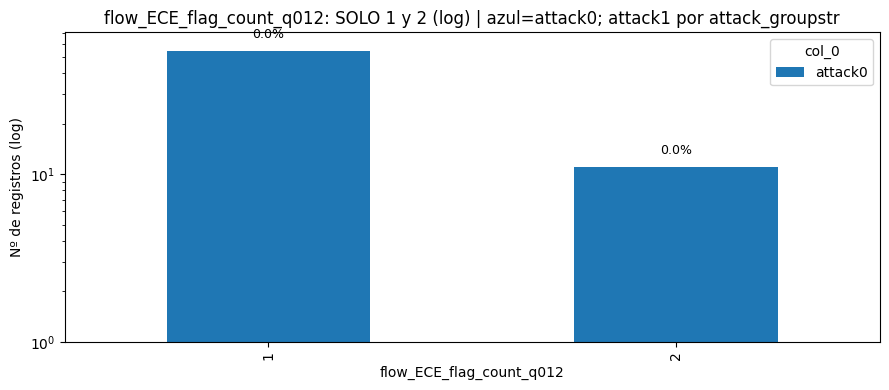

flow_ECE_flag_count_q012: % total df -> 1: 0.05% | 2: 0.01%

time: 3.17 s (started: 2026-03-22 13:04:46 +00:00)


In [ ]:
if analisis_eda:
  def direccion_xpkts(cols, df, Ccol="attack_groupstr", flag="attack_flag"):
      segment = np.where(df[flag].eq(0), "attack0", df[Ccol].astype(str))
      n = len(df)

      for var in cols:
          m = df[var].isin([1, 2])
          x = pd.Categorical(df.loc[m, var], categories=[1, 2], ordered=True)

          tab = pd.crosstab(x, segment[m])  # conteos

          #ataque normal (attack0)
          cols_order = (["attack0"] if "attack0" in tab.columns else []) + \
                      [c for c in tab.columns if c != "attack0"]
          tab = tab[cols_order]

          totals = tab.sum(axis=1)
          perc_total = (totals / n * 100).fillna(0)  # % respecto al df completo

          ax = tab.plot(kind="bar", stacked=True, figsize=(9, 4))

          #pasar a escala log xa ver mejor
          ax.set_yscale("log")

          ymax = int(totals.max()) if len(totals) else 1
          ax.set_ylim(1, ymax * 1.3)   #mínimo 1 para log

          ax.set_xlabel(var)
          ax.set_ylabel("Nº de registros (log)")
          ax.set_title(f"{var}: SOLO 1 y 2 (log) | azul=attack0; attack1 por {Ccol}")

          #Etiquetas % altura> tot
          for i, (cnt, p) in enumerate(zip(totals.values, perc_total.values)):
              # en log, multiplicar es mejor que sumar
              y_text = max(cnt, 1) * 1.15
              ax.text(i, y_text, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)

          plt.tight_layout()
          plt.show()

          print(f"{var}: % total df -> 1: {perc_total.get(1, 0):.2f}% | 2: {perc_total.get(2, 0):.2f}%\n")

  direccion_xpkts(pkts_types_q012, df, Ccol="attack_groupstr", flag="attack_flag")

**Solamente estos no son suficientes para decidir ataques, por tanto tendremos que verlo en conjunto y además por separado bruteforce ya que constituye un 0.03% del total de tráfico.**

###**ANÁLISIS CONCRETO DE ATAQUE BRUTEFORCE**

---



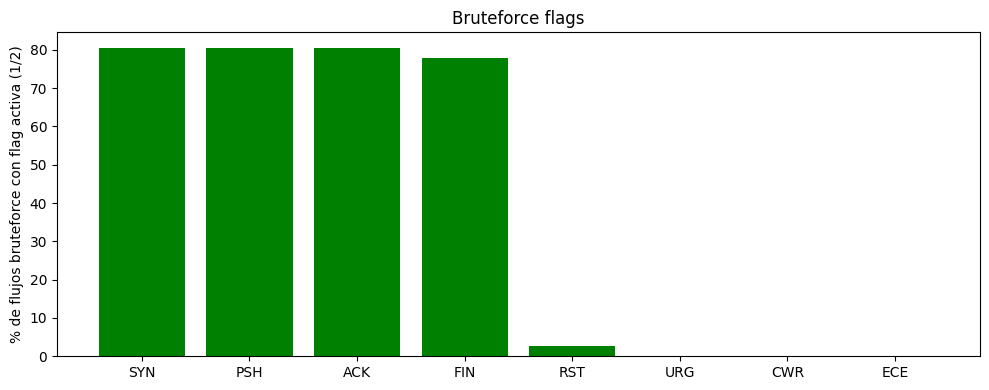

time: 187 ms (started: 2026-03-22 13:04:49 +00:00)


In [ ]:
if analisis_eda:
  def short_flag3(name: str) -> str:
      m = re.search(r'_(SYN|ACK|FIN|RST|PSH|URG|CWR|ECE)_', str(name))
      return m.group(1) if m else str(name)

  def bruteforce_flags_bar(df, cols, Ccol="attack_groupstr", brute_label="bruteforce"):
      sub = df[df[Ccol].astype(str) == brute_label]
      if len(sub) == 0:
          print("No hay filas de bruteforce")
          return

      active = sub[cols].gt(0).mean().sort_values(ascending=False) * 100
      active.index = [short_flag3(c) for c in active.index]

      plt.figure(figsize=(10,4))
      plt.bar(active.index, active.values, color='green')
      plt.ylabel("% de flujos bruteforce con flag activa (1/2)")
      plt.title("Bruteforce flags")
      plt.xticks(rotation=0)
      plt.tight_layout()
      plt.show()

  bruteforce_flags_bar(df, pkts_types, Ccol="attack_groupstr", brute_label="bruteforce")

###**ANÁLISIS POR ATAQUE Y DIRECCIÓN DEL TIPO DE PAQUETE EN CONJUNTO**

---



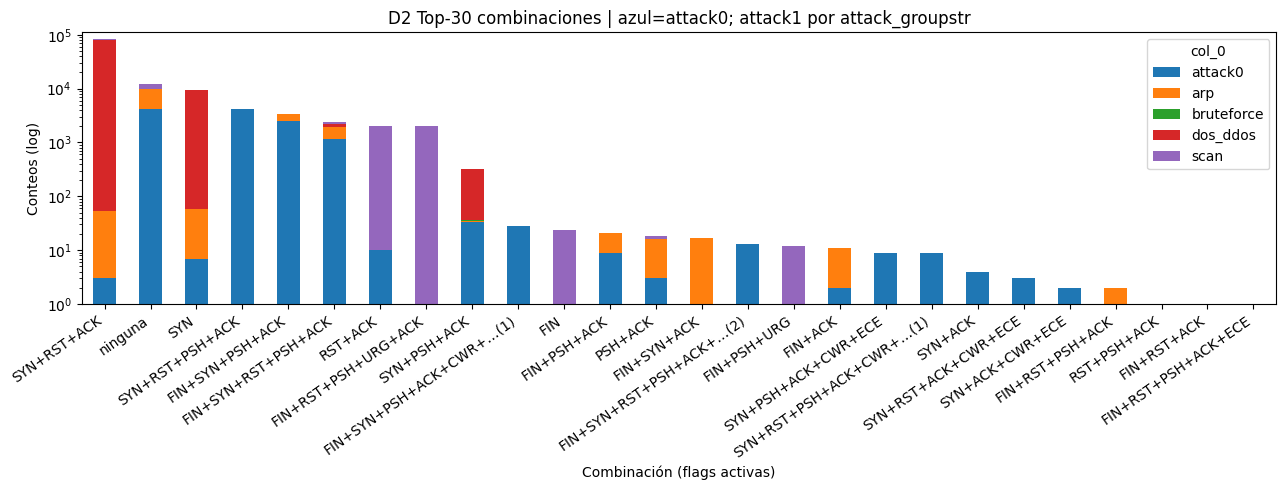

time: 1.66 s (started: 2026-03-22 13:04:49 +00:00)


In [ ]:
if analisis_eda:
  def short_flag2(name: str) -> str:
      m = re.search(r'_(SYN|ACK|FIN|RST|PSH|URG|CWR|ECE)_', str(name))
      if m:
          return m.group(1)
      s = str(name)
      s = re.sub(r'^flow_', '', s)
      s = re.sub(r'_flag_count$', '', s)
      return s

  def d2_top_combos_pretty_short(cols, df, Ccol="attack_groupstr", flag="attack_flag",
                                top_n=30, max_names=5, use_log=True):
      active = df[cols].isin([1, 2])  # activa = 1/2
      sig = active.astype(int).astype(str).agg("".join, axis=1)
      segment = np.where(df[flag].eq(0), "attack0", df[Ccol].astype(str))

      tab = pd.crosstab(sig, segment)

      top_idx = tab.sum(axis=1).sort_values(ascending=False).head(top_n).index
      tab = tab.loc[top_idx].copy()

      cols_order = (["attack0"] if "attack0" in tab.columns else []) + [c for c in tab.columns if c != "attack0"]
      tab = tab[cols_order]

      cols_list = list(cols)
      cols_short = [short_flag2(c) for c in cols_list]

      def sig_to_names(s):
          ones = [cols_short[i] for i, ch in enumerate(s) if ch == "1"]
          if len(ones) == 0:
              return "ninguna"
          # quitar duplicados si te sale repetido (por si hubiera columnas raras)
          # manteniendo orden:
          seen, uniq = set(), []
          for t in ones:
              if t not in seen:
                  uniq.append(t); seen.add(t)

          if len(uniq) <= max_names:
              return "+".join(uniq)
          return "+".join(uniq[:max_names]) + f"+…({len(uniq)-max_names})"

      tab.index = [sig_to_names(s) for s in tab.index]

      ax = tab.plot(kind="bar", stacked=True, figsize=(13, 5))

      if use_log:
          ax.set_yscale("log")
          ax.set_ylabel("Conteos (log)")
          ymax = int(tab.sum(axis=1).max()) if len(tab) else 1
          ax.set_ylim(1, ymax * 1.35)
      else:
          ax.set_ylabel("Conteos")

      ax.set_xlabel("Combinación (flags activas)")
      ax.set_title(f"D2 Top-{top_n} combinaciones | azul=attack0; attack1 por {Ccol}")
      plt.xticks(rotation=35, ha="right")
      plt.tight_layout()
      plt.show()

  # uso
  d2_top_combos_pretty_short(pkts_types_q012, df, Ccol="attack_groupstr", flag="attack_flag",
                            top_n=30, max_names=5, use_log=True)

Se observó que las combinaciones dominadas por **escaneo** aparecen recurrentemente asociadas a flags de cierre (FIN) y, en algunos casos, URG, las combinaciones que incluyen **ECE/CWR** están mayoritariamente dominadas por tráfico benigno (attack0), consistente con señales de congestión/ECN más que con comportamiento malicioso, **los ataques dos/ddos** se concentran en combinaciones donde aparecen SYN/ACK y RST, lo que encaja con flujos muy cortos o reinicios frecuentes. **Los ataques dns-arp** sobre todo con PSH y, en menor medida, con RST/FIN/SYN, aunque estos ultimos son tcp y por ello debe interpretarse como una simple aparición sin relación (ARP no es TCP, usa DNS que es UDP), x último **bruteforce** aparece de forma repentina y en muy pocas combinaciones, pero las que aparece depende de los paquetes SYN, PSH, ACK, y FIN, además de una baja concentración de RST, lo que puede significar que estos ataques no se cortan repentinamente, osea que se sabe prefectamente el objetivo y puerto abierto desprotegido, y continúan incluso logrando entrar al target.

###**ANÁLISIS POR ATAQUE DE LA DURACIÓN, SERVICIO, PESO Y TOTAL DE PAQUETES**

---



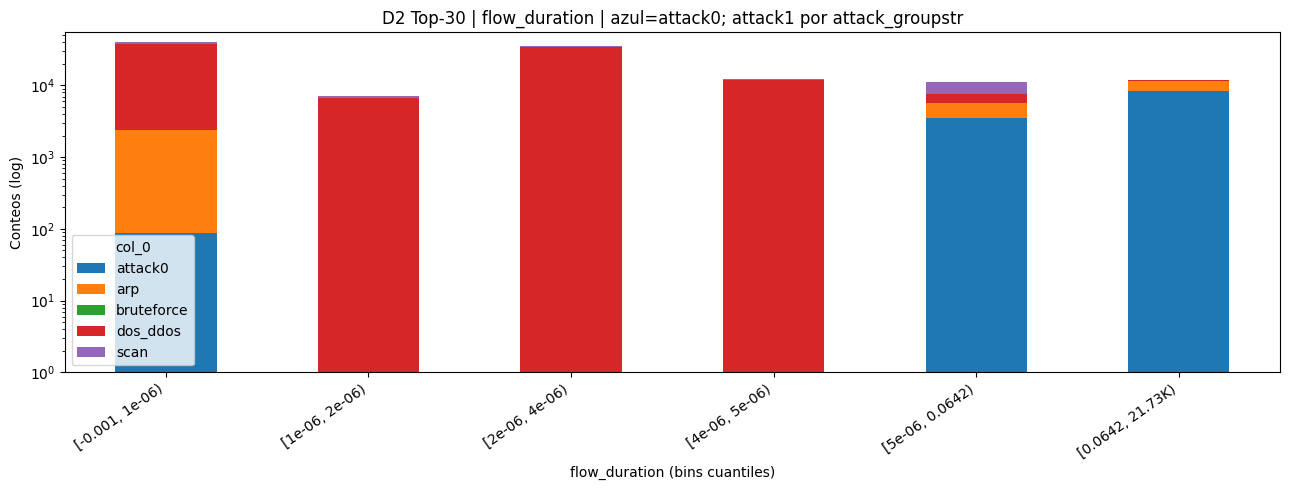

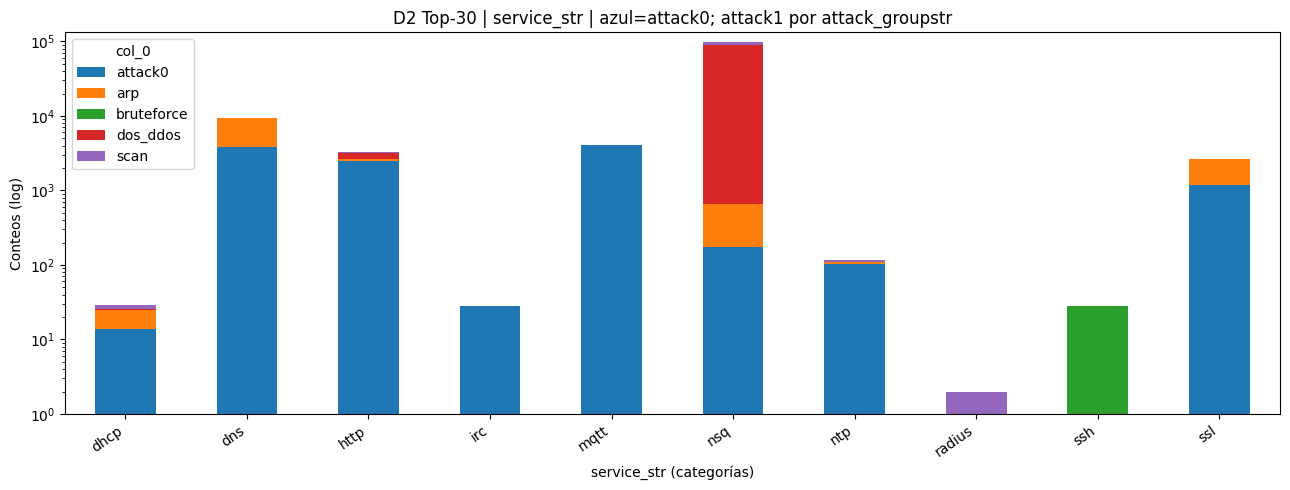

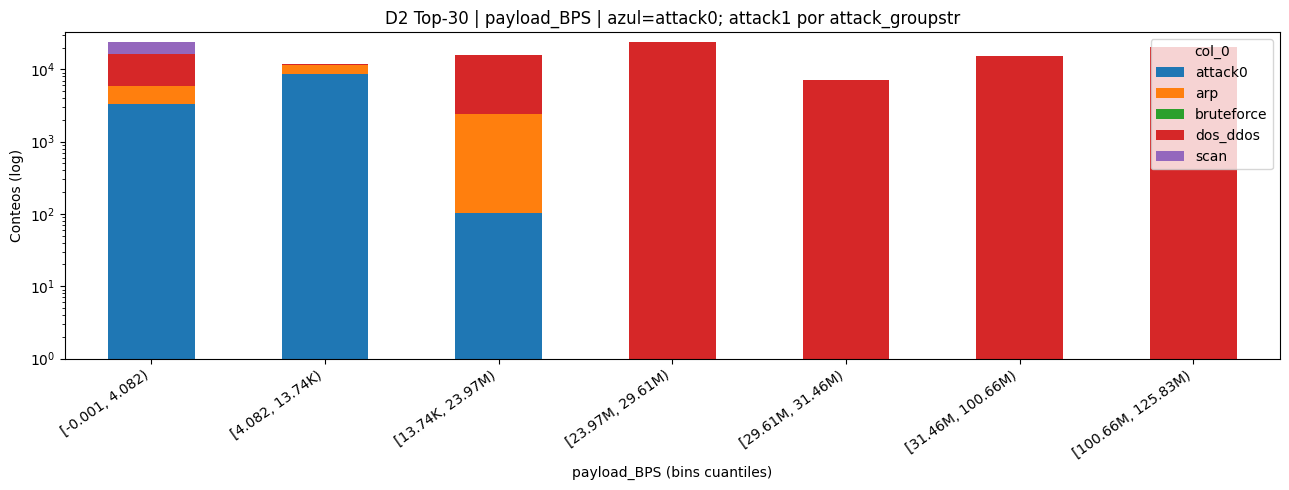

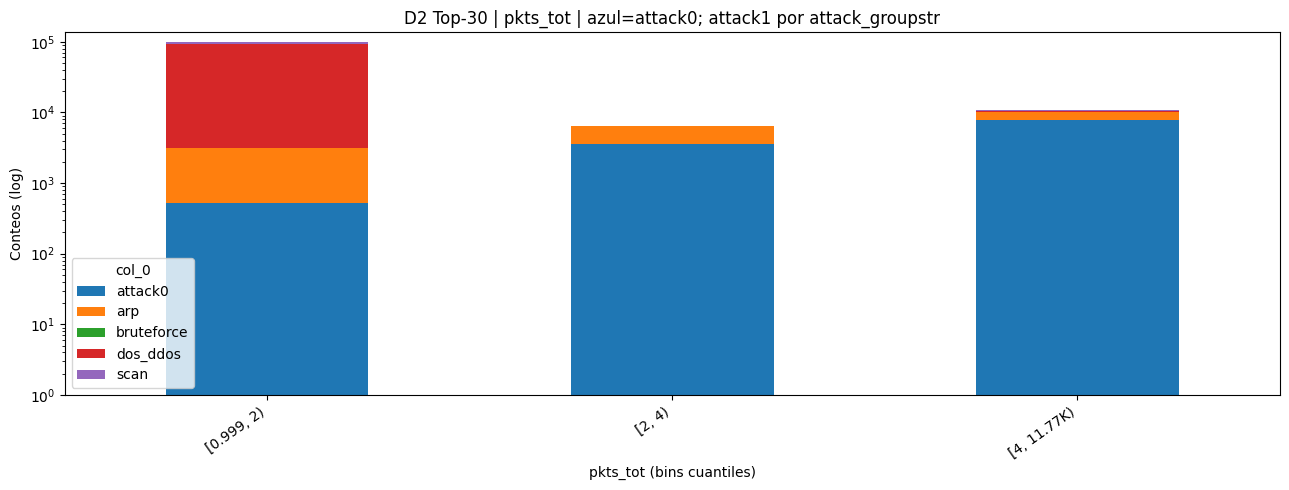

time: 5.48 s (started: 2026-03-22 13:04:51 +00:00)


In [ ]:
if analisis_eda:

  def  fmt_num(v):
      """Formato compacto para límites de bins: 1.2K, 3.4M, 5.6B, etc."""
      if v is None or (isinstance(v, float) and np.isnan(v)):
          return "NaN"
      v = float(v)
      av = abs(v)
      if av >= 1e9:  return f"{v/1e9:.2f}B"
      if av >= 1e6:  return f"{v/1e6:.2f}M"
      if av >= 1e3:  return f"{v/1e3:.2f}K"
      if av >= 1:    return f"{v:.3f}".rstrip("0").rstrip(".")
      if av < 1e-9:  return "0"
      return f"{v:.3g}"

  def  fmt_interval(iv):
      if isinstance(iv, pd.Interval):
          a, b = iv.left, iv.right
          return f"[{ fmt_num(a)}, { fmt_num(b)})"
      return str(iv)

  def juntarto(col, df, Ccol="attack_groupstr", flag="attack_flag",
                              top_n=30, bins=10, use_log=True, dropna=True):
      s = df[col]
      seg = np.where(df[flag].eq(0), "attack0", df[Ccol].astype(str))

      #xcat
      if pd.api.types.is_numeric_dtype(s):
          x = s
          if dropna:
              m = x.notna()
              x, seg2 = x[m], pd.Series(seg, index=df.index)[m]
          else:
              seg2 = pd.Series(seg, index=df.index)

          try:
              xcat = pd.qcut(x, q=bins, duplicates="drop")
          except ValueError:
              #poca variación -> tratar como "categoría" directa
              xcat = x.astype(str)

          tab = pd.crosstab(xcat, seg2)

          #top_n por frecuencia, luego orden natural por bin
          if top_n is not None:
              top_idx = tab.sum(1).sort_values(ascending=False).head(top_n).index
              tab = tab.loc[top_idx]
          tab = tab.sort_index()

          #etiquetas limpias
          tab.index = [ fmt_interval(iv) for iv in tab.index]
          xlab = f"{col} (bins cuantiles)"

      else:
          xcat = s.astype("string")
          if dropna:
              m = xcat.notna()
              xcat, seg2 = xcat[m], pd.Series(seg, index=df.index)[m]
          else:
              seg2 = pd.Series(seg, index=df.index)

          tab = pd.crosstab(xcat, seg2)

          if top_n is not None:
              top_idx = tab.sum(1).sort_values(ascending=False).head(top_n).index
              tab = tab.loc[top_idx]

          tab = tab.sort_index()
          xlab = f"{col} (categorías)"

      #attack0 primero
      order = (["attack0"] if "attack0" in tab.columns else []) + [c for c in tab.columns if c != "attack0"]
      tab = tab[order]

      ax = tab.plot(kind="bar", stacked=True, figsize=(13, 5))

      if use_log:
          ax.set_yscale("log")
          ax.set_ylabel("Conteos (log)")
          ymax = int(tab.sum(1).max()) if len(tab) else 1
          ax.set_ylim(1, ymax * 1.35)
      else:
          ax.set_ylabel("Conteos")

      ax.set_xlabel(xlab)
      ax.set_title(f"D2 Top-{top_n} | {col} | azul=attack0; attack1 por {Ccol}")
      plt.xticks(rotation=35, ha="right")
      plt.tight_layout()
      plt.show()
  cols_4 = ['flow_duration', 'service_str', 'payload_BPS', 'pkts_tot']

  for c in cols_4:
      juntarto(c, df, Ccol="attack_groupstr", flag="attack_flag",
                              top_n=30, bins=10, use_log=True)

**Podemos concluir que los ataques de bruteforce se hacen todos con protocolo ssh, por lo tanto habría que poner especial atencion a estos, los escaneos sobretodo con radious (que sirve xa escaneos de puertos UDP 1812 y 1813 para identificar servidores vulnerables), para hacer un ataque normalmente bastan 2 paquetes, un ataque Ddos puede durar hasta 5 veces más que el flujo de tráfico corriente y estos estan dominados por una grandísima cantidad de datos más.**

###**ANÁLISIS DE CORRELACIÓN SIN MATRIZ Y SELECCIÓN DE IMPORTANCIA (NO SUMA VALOR, NO APORTA NADA ÚTIL)**

In [ ]:
if analisis_eda:

  def importantes_corr(
      df=None,
      excel_out_path="correlaciones_completas.xlsx",
      excel_in_path=None,   #excel en vez de calcular
      abs_thr=0.40,
      abs_max=0.995, #no 1
      max_pairs=20,
      max_per_col=2, #cols mismo nombre monopolio
      max_name_sim=0.35, #longitud
      seed=7):
      def re_flag(s):
          s = str(s).lower()
          s = re.sub(r'^(flow|fwd|bwd)[_]+', '', s)
          s = re.sub(r'(_q\d+)+$', '', s)
          s = re.sub(r'(_flag_count)$', '', s)
          s = re.sub(r'(_count)$', '', s)
          s = re.sub(r'[^a-z0-9]+', ' ', s).strip()
          return s

      def name_sim(a, b):
          na, nb = re_flag(a), re_flag(b)
          if not na or not nb:
              return 0.0
          if na == nb or na in nb or nb in na:
              return 1.0
          A, B = set(na.split()), set(nb.split())
          return len(A & B) / len(A | B) if (A and B) else 0.0

      def excluded(col):
          c = str(col).lower()
          if re.search(r'_q\d+', c): return True
          if "attack_type" in c: return True
          if c.startswith("attack_"): return True
          if "service" in c: return True
          if "dst_port" in c or "id_dst_port" in c: return True
          if c.startswith("protocol_") or c in {"protocol","proto"}: return True
          return False

      def group(col):
          c = re_flag(col)
          toks = set(c.split())
          time_kw = {"iat","duration","active","inactive","idle","time"}
          size_kw = {"bytes","byte","payload","len","length","pkts","pkt","packets","bps","pps","rate","throughput"}
          ecn_kw  = {"ece","cwr"}
          tcpflag_kw = {"syn","ack","fin","rst","psh","urg"}
          window_kw = {"window"}  # init/last window size
          header_kw = {"header"}  # header_size_*
          ratio_kw  = {"ratio"}   # down_up_ratio etc.
          bulk_kw   = {"bulk","subflow"}

          if toks & window_kw: return "window"
          if toks & header_kw: return "header"
          if toks & ratio_kw:  return "ratio"
          if toks & ecn_kw:    return "ecn"
          if toks & tcpflag_kw:return "tcpflag"
          if toks & bulk_kw:   return "bulk"
          if toks & time_kw:   return "time"
          if toks & size_kw:   return "size"
          return "other"

      def flags_quedarme(x, y):
          s = (str(x).lower() + " " + str(y).lower())
          terms = ["window", "header", "down_up_ratio", "ratio", "mss", "ttl"]
          return sum(1 for t in terms if t in s)

      def bulk_ver(x, y):
          s = (str(x).lower() + " " + str(y).lower())
          return 1 if ("subflow" in s or "bulk" in s) else 0

      def reason(row):
          gx, gy = row["grp_x"], row["grp_y"]
          bx = flags_quedarme(row["col_x"], row["col_y"])
          if ("window" in {gx,gy}) and ("tcpflag" in {gx,gy}):
              return "Ventana TCP asociada a patrón de flags (posible efecto de sesiones/handshake o artefacto de captura)"
          if ("header" in {gx,gy}) and ("tcpflag" in {gx,gy}):
              return "Cabeceras vs flags: relación con número/ritmo de ACK/SYN (comportamiento de control del flujo)"
          if ("ratio" in {gx,gy}) and ("header" in {gx,gy}):
              return "Asimetría subida/bajada ligada a cabeceras: puede reflejar flujos muy 'control' vs 'datos'"
          if ("time" in {gx,gy}) and ("window" in {gx,gy}):
              return "Temporalidad del flujo ligada al window size (posible dinámica TCP o discretización del extractor)"
          if ("time" in {gx,gy}) and ("tcpflag" in {gx,gy}):
              return "Flags vs tiempos: sugiere flujos cortos/reintentos/terminación (útil para explicar ataques de alta rotación)"
          if bx > 0:
              return "Relación cruzada con variables de control (window/header/ratio) útil para interpretabilidad"
          return "Relación cruzada no trivial (útil para discusión EDA/interpretabilidad)"

      #excel generar
      if excel_in_path is None:
          if df is None:
              raise ValueError("Pasa df o excel_in_path. Si excel_in_path es None, df es obligatorio.")

          corr_cols = df.select_dtypes(include=["number","bool"]).columns
          corr_pear  = df[corr_cols].corr(method="pearson")
          corr_spear = df[corr_cols].corr(method="spearman")

          mask = np.triu(np.ones(corr_pear.shape, dtype=bool), k=1)
          pear_vals  = corr_pear.where(mask).stack().rename("pearson")
          spear_vals = corr_spear.where(mask).stack().rename("spearman")

          corr_long = pd.concat([pear_vals, spear_vals], axis=1).reset_index()
          corr_long = corr_long.rename(columns={"level_0":"col_x","level_1":"col_y"})

          corr_long["abs_pearson"]  = corr_long["pearson"].abs()
          corr_long["abs_spearman"] = corr_long["spearman"].abs()
          corr_long["best_method"]  = np.where(
              corr_long["abs_pearson"] >= corr_long["abs_spearman"], "pearson", "spearman"
          )
          corr_long["best_corr"] = np.where(
              corr_long["best_method"].eq("pearson"), corr_long["pearson"], corr_long["spearman"]
          )
          corr_long["abs_best_corr"] = corr_long["best_corr"].abs()

          corr_long = corr_long.sort_values("abs_best_corr", ascending=False).reset_index(drop=True)
          corr_long.to_excel(excel_out_path, index=False)
          excel_path_used = excel_out_path
      else:
          excel_path_used = excel_in_path

      #excel leer
      corr = pd.read_excel(excel_path_used)

      need_cols = {"col_x","col_y","best_corr","abs_best_corr","best_method"}
      if not need_cols.issubset(set(corr.columns)):
          raise ValueError(f"El Excel no tiene las columnas esperadas. Necesito al menos: {sorted(list(need_cols))}")

      corr = corr.copy()
      corr["name_sim"] = corr.apply(lambda r: name_sim(r["col_x"], r["col_y"]), axis=1)
      corr["grp_x"] = corr["col_x"].apply(group)
      corr["grp_y"] = corr["col_y"].apply(group)
      corr["flags_quedarme"] = corr.apply(lambda r: flags_quedarme(r["col_x"], r["col_y"]), axis=1)
      corr["bulk_pen"] = corr.apply(lambda r: bulk_ver(r["col_x"], r["col_y"]), axis=1)

      #filtro colinealidad, similitud, correlaciones, familias, flags
      corr = corr[(corr["abs_best_corr"] >= abs_thr) & (corr["abs_best_corr"] < abs_max)]
      corr = corr[~corr["col_x"].apply(excluded) & ~corr["col_y"].apply(excluded)]
      corr = corr[corr["name_sim"] < max_name_sim]
      corr = corr[~((corr["grp_x"] == corr["grp_y"]) & corr["grp_x"].isin(["time","size","tcpflag","ecn"]))]

      #ambas duraciones/iat del
      mask_already = (
          (corr["col_x"].str.contains("duration", case=False, na=False) & corr["col_y"].str.contains("iat", case=False, na=False)) |
          (corr["col_y"].str.contains("duration", case=False, na=False) & corr["col_x"].str.contains("iat", case=False, na=False))
      )
      corr = corr[~mask_already]

      #scoring xa corr
      corr["cross"] = (corr["grp_x"] != corr["grp_y"]).astype(int)
      corr["score"] = (
          corr["abs_best_corr"]
          + 0.15 * corr["flags_quedarme"]
          + 0.05 * corr["cross"]
          - 0.20 * corr["name_sim"]
          - 0.10 * corr["bulk_pen"]
      )

      corr = corr.sort_values("score", ascending=False)

      #seleccion limitada
      selected = []
      counts = {}
      for _, r in corr.iterrows():
          x, y = r["col_x"], r["col_y"]
          if counts.get(x, 0) >= max_per_col or counts.get(y, 0) >= max_per_col:
              continue
          selected.append(r)
          counts[x] = counts.get(x, 0) + 1
          counts[y] = counts.get(y, 0) + 1
          if len(selected) >= max_pairs:
              break

      df_importantes = pd.DataFrame(selected)
      if df_importantes.empty:
          df_importantes = df_importantes.assign(motivo=pd.Series(dtype=str))
      else:
          df_importantes["motivo"] = df_importantes.apply(reason, axis=1)

      #importantes
      keep = ["col_x","col_y","best_corr","best_method","abs_best_corr","grp_x","grp_y","motivo"]
      df_importantes = df_importantes[keep].reset_index(drop=True)

      return df_importantes, excel_path_used
  df_importantes, excel_path = importantes_corr(
      df=df,
      excel_out_path=path + 'correlaciones_completas.xlsx',
      excel_in_path=(path + 'correlaciones_completas.xlsx') if os.path.exists(path + 'correlaciones_completas.xlsx') else None,
      abs_thr=0.40,
      max_pairs=20
  )
  df_importantes

time: 2 s (started: 2026-03-22 13:04:57 +00:00)


In [ ]:
if analisis_eda:
  print(path)
  df_full=df

/content/drive/MyDrive/open data/CYBER_TRABAJO/
time: 550 µs (started: 2026-03-22 13:04:59 +00:00)


##**SELECCIÓN DE VARIABLES SIN ATAJOS o CORR CON EL TARGET PARA CLUSTERING Y APRENDIZAJE SUPERVISADO Y RECORTE DE D2**

---



In [ ]:
if analisis_eda:

  def preparar_df_v2(df_full, seed=42, d2_frac_of_total=0.06, target_corr_thr=0.95,
                    label_group="attack_groupstr", label_bin="attack_flag"):

      df_full = df_full.copy()
      df_full = df_full.loc[:, ~df_full.columns.duplicated()].copy()

      if label_group not in df_full.columns:
          raise ValueError(f"Falta {label_group}")
      if label_bin not in df_full.columns:
          raise ValueError(f"Falta {label_bin}")

      #d2 7.8%recorte
      mask_d2 = df_full[label_group].astype(str).eq("dos_ddos")
      df_d2 = df_full[mask_d2]
      df_rest = df_full[~mask_d2]

      n_target = int(round(len(df_full) * float(d2_frac_of_total)))
      n_keep = min(len(df_d2), max(1, n_target))

      df_d2_keep = df_d2.sample(n=n_keep, random_state=seed) if len(df_d2) else df_d2
      dfVal = pd.concat([df_rest, df_d2_keep], ignore_index=True)
      dfVal = dfVal.sample(frac=1, random_state=seed).reset_index(drop=True)

      #del atajos
      drop_shortcuts = {
          "id_src_port", "id_dst_port",
          "protocolstr", "service_str","attack_group"
      }#'attack_groupstr', "attack_type"
      drop_prefixes = ("protocol_", "service_", "attack_type_")
      drop_q012 = [c for c in dfVal.columns if str(c).endswith("_q012")]

      #features quedarme importantes no colineales etc
      keep_core = [
          "flow_duration", "pkts_tot", "flow_pkts_per_sec", "down_up_ratio", "payload_BPS",
          "fwd_pkts_tot", "bwd_pkts_tot", "fwd_data_pkts_tot", "bwd_data_pkts_tot",
          "fwd_pkts_per_sec", "bwd_pkts_per_sec",
          "fwd_header_size_tot", "bwd_header_size_tot", "fwd_header_size_max", "bwd_header_size_max",
          "flow_FIN_flag_count", "flow_SYN_flag_count", "flow_RST_flag_count", "flow_ACK_flag_count",
          "flow_PSH_flag_count", "flow_URG_flag_count", "flow_CWR_flag_count", "flow_ECE_flag_count",
          "fwd_PSH_flag_count", "bwd_PSH_flag_count", "fwd_URG_flag_count", "bwd_URG_flag_count",
          "flow_pkts_payload_min", "flow_pkts_payload_max", "flow_pkts_payload_avg",
          "flow_pkts_payload_std", "flow_pkts_payload_tot",
          "flow_iat_min", "flow_iat_max", "flow_iat_avg", "flow_iat_std", "flow_iat_tot",
          "active_avg", "active_std", "active_tot",
          "inactive_avg", "inactive_std", "inactive_tot",
          "fwd_init_window_size", "fwd_last_window_size", "bwd_init_window_size",
          "fwd_subflow_bytes", "bwd_subflow_bytes", "fwd_bulk_rate", "bwd_bulk_rate",'attack_type'
      ]
      keep_core = [c for c in keep_core if c in dfVal.columns]

      #drop demas
      drop_cols = set(drop_q012) | set([c for c in drop_shortcuts if c in dfVal.columns])
      for c in list(dfVal.columns):
          if str(c).startswith(drop_prefixes):
              drop_cols.add(c)

      #df+target attack_flag + mantener attack_groupstr
      features = [c for c in keep_core if c not in drop_cols and c != label_bin]
      df = dfVal[features + [label_group, label_bin]].copy() #quitar label group xa quitar el attack_groupstr

      #drop corr>=95% solo sobre variables numericas/bool, nunca sobre label_group
      X = df[features].select_dtypes(include=["number", "bool"])
      y = pd.to_numeric(df[label_bin], errors="coerce")

      corr_to_target = X.corrwith(y, method="pearson").dropna()
      drop_by_target_corr = corr_to_target[
          corr_to_target.abs() >= target_corr_thr
      ].sort_values(key=np.abs, ascending=False)

      df = df.drop(columns=list(drop_by_target_corr.index), errors="ignore")
      features_final = [c for c in df.columns if c not in [label_group, label_bin]]

      report = {
          "seed": seed,
          "d2_frac_of_total": d2_frac_of_total,
          "df_full_shape": tuple(df_full.shape),
          "dfVal_shape": tuple(dfVal.shape),
          "df_shape": tuple(df.shape),
          "dfVal_attack_groupstr_dist": dfVal[label_group].value_counts(dropna=False).to_dict(),
          "df_attack_groupstr_dist": df[label_group].value_counts(dropna=False).to_dict(),
          "n_d2_original": int(mask_d2.sum()),
          "n_d2_kept": int(n_keep),
          "target_corr_thr": target_corr_thr,
          "drop_by_target_corr": drop_by_target_corr.to_dict(),
          "features_used": features_final,
          "label_group": label_group,
          "target": label_bin
      }

      return dfVal, df, report

    #report como dict
  dfVal, dfc, report = preparar_df_v2(df_full=df_full, seed=42, d2_frac_of_total=0.06, target_corr_thr=0.95)
  print(report["dfVal_shape"], report["df_shape"])
  print(pd.Series(report["dfVal_attack_groupstr_dist"]))
  print("D2 original:", report["n_d2_original"], " | D2 kept:", report["n_d2_kept"])
  print("Dropped por |corr con target|>=0.95:", report["drop_by_target_corr"])
  dfc.to_csv(path+"dfanálisis.csv", index=False)

(34375, 123) (34375, 53)
normal        12015
arp            7625
scan           7624
dos_ddos       7075
bruteforce       36
dtype: int64
D2 original: 90622  | D2 kept: 7075
Dropped por |corr con target|>=0.95: {}
time: 1.95 s (started: 2026-03-22 13:04:59 +00:00)


In [ ]:
if analisis_eda:

  def preparar_df_v2(df_full, seed=42, target_corr_thr=0.95,
                    label_group="attack_groupstr", label_bin="attack_flag"):

      df_full = df_full.copy()
      df_full = df_full.loc[:, ~df_full.columns.duplicated()].copy()

      if label_group not in df_full.columns:
          raise ValueError(f"Falta {label_group}")
      if label_bin not in df_full.columns:
          raise ValueError(f"Falta {label_bin}")

      dfVal=df_full.copy()

      #del atajos
      drop_shortcuts = {
          "id_src_port", "id_dst_port",
          "protocolstr", "service_str","attack_group"
      }#'attack_groupstr', "attack_type"
      drop_prefixes = ("protocol_", "service_", "attack_type_")
      drop_q012 = [c for c in dfVal.columns if str(c).endswith("_q012")]

      #features quedarme importantes no colineales etc
      keep_core = [
          "flow_duration", "pkts_tot", "flow_pkts_per_sec", "down_up_ratio", "payload_BPS",
          "fwd_pkts_tot", "bwd_pkts_tot", "fwd_data_pkts_tot", "bwd_data_pkts_tot",
          "fwd_pkts_per_sec", "bwd_pkts_per_sec",
          "fwd_header_size_tot", "bwd_header_size_tot", "fwd_header_size_max", "bwd_header_size_max",
          "flow_FIN_flag_count", "flow_SYN_flag_count", "flow_RST_flag_count", "flow_ACK_flag_count",
          "flow_PSH_flag_count", "flow_URG_flag_count", "flow_CWR_flag_count", "flow_ECE_flag_count",
          "fwd_PSH_flag_count", "bwd_PSH_flag_count", "fwd_URG_flag_count", "bwd_URG_flag_count",
          "flow_pkts_payload_min", "flow_pkts_payload_max", "flow_pkts_payload_avg",
          "flow_pkts_payload_std", "flow_pkts_payload_tot",
          "flow_iat_min", "flow_iat_max", "flow_iat_avg", "flow_iat_std", "flow_iat_tot",
          "active_avg", "active_std", "active_tot",
          "inactive_avg", "inactive_std", "inactive_tot",
          "fwd_init_window_size", "fwd_last_window_size", "bwd_init_window_size",
          "fwd_subflow_bytes", "bwd_subflow_bytes", "fwd_bulk_rate", "bwd_bulk_rate",'attack_type'
      ]
      keep_core = [c for c in keep_core if c in dfVal.columns]

      #drop demas
      drop_cols = set(drop_q012) | set([c for c in drop_shortcuts if c in dfVal.columns])
      for c in list(dfVal.columns):
          if str(c).startswith(drop_prefixes):
              drop_cols.add(c)

      #df+target attack_flag + mantener attack_groupstr
      features = [c for c in keep_core if c not in drop_cols and c != label_bin]
      df = dfVal[features + [label_group, label_bin]].copy() #quitar label group xa quitar el attack_groupstr

      #drop corr>=95% solo sobre variables numericas/bool, nunca sobre label_group
      X = df[features].select_dtypes(include=["number", "bool"])
      y = pd.to_numeric(df[label_bin], errors="coerce")

      corr_to_target = X.corrwith(y, method="pearson").dropna()
      drop_by_target_corr = corr_to_target[
          corr_to_target.abs() >= target_corr_thr
      ].sort_values(key=np.abs, ascending=False)

      df = df.drop(columns=list(drop_by_target_corr.index), errors="ignore")
      features_final = [c for c in df.columns if c not in [label_group, label_bin]]

      report = {
          "seed": seed,
          "df_full_shape": tuple(df_full.shape),
          "dfVal_shape": tuple(dfVal.shape),
          "df_shape": tuple(df.shape),
          "dfVal_attack_groupstr_dist": dfVal[label_group].value_counts(dropna=False).to_dict(),
          "df_attack_groupstr_dist": df[label_group].value_counts(dropna=False).to_dict(),
          "target_corr_thr": target_corr_thr,
          "drop_by_target_corr": drop_by_target_corr.to_dict(),
          "features_used": features_final,
          "label_group": label_group,
          "target": label_bin
      }

      return dfVal, df, report

    #report como dict
  dfVal, dfc_d2, report = preparar_df_v2(df_full=df_full, seed=42, target_corr_thr=0.95)
  print(report["dfVal_shape"], report["df_shape"])
  print(pd.Series(report["dfVal_attack_groupstr_dist"]))
  print("Dropped por |corr con target|>=0.95:", report["drop_by_target_corr"])
  dfc_d2.to_csv(path+"dfanálisis_alld2.csv", index=False)

(117922, 123) (117922, 53)
dos_ddos      90622
normal        12015
arp            7625
scan           7624
bruteforce       36
dtype: int64
Dropped por |corr con target|>=0.95: {}
time: 5.13 s (started: 2026-03-22 13:05:01 +00:00)


In [ ]:
if not analisis_eda:
  try:
      dfc_d2= pd.read_csv(path + "dfanálisis_alld2.csv")
  except Exception as e:
      raise RuntimeError(f"Error al leer el CSV: {e}")

time: 648 µs (started: 2026-03-22 13:05:06 +00:00)


###**CONCLUSIÓN PARA FUTURO CLUSTERING Y ML**

---

**Se preparo para el futuro dos dataset de análisis, uno con una proporción de d2 ajustada y proporcional, no considerada sesgo al provenir de una mustra total ya sesgada por un entorno controlado, y además un dataset como inicialmente estaba medido, sin ningún ajuste innecesario, de momento de trabajará con el completo y se dejará el otro apartado pero analizado también y se presentarán conclusiones mixtas**

**Se eliminaron variables de contexto que podían actuar como atajos (puertos origen/destino, protocolo y servicio), tranformaciones por cuartiles, duplicados y dummies indirectos, todas los targets o sus derivadas (attack_type y sus one-hot), ya que estas variables son conlineares y directamente dependientes del resultado, todas las coorelaciones mayores al 95% en valor absoluto y viendo que las restantes no tengan nada que ver con lo eliminado anteriormente y sean aptas para análisis y ml posterior (duración, tasas, volumen, asimetría, flags, payload, IAT, active/inactive y window). Al final nos quedamos con 51/123 columnas 41% del dataset original**

**Se priorizó la predicción binaria (attack_flag) para evitar que la tipificación multiclase quedara dominada por una clase mayoritaria (ddos), y clases extremadamente raras (bruteforce) o sea fácil de reproducir. Aunque más tarde puede formarse otra idea de target según clustering y clasificación ml**

**Se fijó random_state=42 para garantizar reproducibilidad, y usado para quedarnos solo con una proporción adecuada de los ataques ddos para parecerse a otros cuya proporción es 6% del dataset original y sera aproximadamente 24.5% del nuevo quedandonos con una mustra de 7.82% de los ataques ddos. Desde ahi constrimos el nuevo dataset y exportamos a excel para no hacer la limpieza y selección una y otra vez**

**Por último, aunque se exploró la correlación entre variables, no se identificaron relaciones especialmente útiles o interpretables para el problema planteado que no sean resolubles o interpretables de la misma manera y/o que se hayan hecho/identificado con la misma precisión en otros apartados, por lo que no se incluyó como tal en el EDA.**

## **CLUSTERING**

---



**El objetivo del clustering es detectar agrupaciones internas de flujos de red con características similares, independientemente de la etiqueta supervisada, para comprobar si la estructura natural de los datos coincide o no con los tipos de tráfico observados**

###**INFO**

In [ ]:
dfc=dfc_d2.copy()

time: 23.8 ms (started: 2026-03-22 13:05:06 +00:00)


In [ ]:
dfc.shape

(117922, 53)

time: 4.03 ms (started: 2026-03-22 13:05:06 +00:00)


In [ ]:
y=dfc['attack_flag']
ystr=dfc['attack_groupstr']
cols_no_numericas = dfc.select_dtypes(exclude=['number']).columns.tolist()
y_12type=dfc["attack_type"]
X = dfc.drop(columns=["attack_type", "attack_groupstr", "attack_flag"])

time: 21.1 ms (started: 2026-03-22 13:05:06 +00:00)


In [ ]:
display(X.head())
display(y.head())
display(y_12type)
display(ystr.head())

,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,inactive_avg,inactive_std,inactive_tot,fwd_init_window_size,fwd_last_window_size,bwd_init_window_size,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate
0,32.011598,14,0.437341,0.555556,3.373777,9,5,3,3,0.281148,...,29.729183,0.0,29.729183,64240,502,26847,25.333333,10.666667,0.0,0.0
1,31.883584,14,0.439097,0.555556,3.387323,9,5,3,3,0.282277,...,29.855277,0.0,29.855277,64240,502,26847,25.333333,10.666667,0.0,0.0
2,32.124053,14,0.435811,0.555556,3.237450,9,5,3,3,0.280164,...,29.842149,0.0,29.842149,64240,502,26847,24.666667,10.000000,0.0,0.0
3,31.961063,14,0.438033,0.555556,3.253959,9,5,3,3,0.281593,...,29.913775,0.0,29.913775,64240,502,26847,24.666667,10.000000,0.0,0.0
4,31.902362,14,0.438839,0.555556,3.385329,9,5,3,3,0.282111,...,29.814705,0.0,29.814705,64240,502,26847,25.333333,10.666667,0.0,0.0


,attack_flag
0,0
1,0
2,0
3,0
4,0


,attack_type
0,MQTT_Publish
1,MQTT_Publish
2,MQTT_Publish
3,MQTT_Publish
4,MQTT_Publish
...,...
117917,NMAP_XMAS_TREE_SCAN
117918,NMAP_XMAS_TREE_SCAN
117919,NMAP_XMAS_TREE_SCAN
117920,NMAP_XMAS_TREE_SCAN


,attack_groupstr
0,normal
1,normal
2,normal
3,normal
4,normal


time: 33.9 ms (started: 2026-03-22 13:05:06 +00:00)


In [ ]:
dfc.head()

,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,fwd_init_window_size,fwd_last_window_size,bwd_init_window_size,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate,attack_type,attack_groupstr,attack_flag
0,32.011598,14,0.437341,0.555556,3.373777,9,5,3,3,0.281148,...,64240,502,26847,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0
1,31.883584,14,0.439097,0.555556,3.387323,9,5,3,3,0.282277,...,64240,502,26847,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0
2,32.124053,14,0.435811,0.555556,3.237450,9,5,3,3,0.280164,...,64240,502,26847,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0
3,31.961063,14,0.438033,0.555556,3.253959,9,5,3,3,0.281593,...,64240,502,26847,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0
4,31.902362,14,0.438839,0.555556,3.385329,9,5,3,3,0.282111,...,64240,502,26847,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0


time: 18.4 ms (started: 2026-03-22 13:05:06 +00:00)


###**ESCALA Y PCA (0-1)**

---



In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

time: 132 ms (started: 2026-03-22 13:05:06 +00:00)


Componentes: 2
Varianza individual: [0.2024 0.1272]
Varianza acumulada: 0.3296
--------------------------------------------------
Componentes: 5
Varianza individual: [0.2024 0.1272 0.1065 0.0929 0.0703]
Varianza acumulada: 0.5992
--------------------------------------------------
Componentes: 8
Varianza individual: [0.2024 0.1272 0.1065 0.0929 0.0703 0.0485 0.0415 0.0381]
Varianza acumulada: 0.7273
--------------------------------------------------
Componentes: 11
Varianza individual: [0.2024 0.1272 0.1065 0.0929 0.0703 0.0485 0.0415 0.0381 0.0348 0.0341
 0.0289]
Varianza acumulada: 0.825
--------------------------------------------------
Componentes: 14
Varianza individual: [0.2024 0.1272 0.1065 0.0929 0.0703 0.0485 0.0415 0.0381 0.0348 0.0341
 0.0289 0.0216 0.0209 0.0199]
Varianza acumulada: 0.8875
--------------------------------------------------
Componentes: 17
Varianza individual: [0.2024 0.1272 0.1065 0.0929 0.0703 0.0485 0.0415 0.0381 0.0348 0.0341
 0.0289 0.0216 0.0209 0.0199 

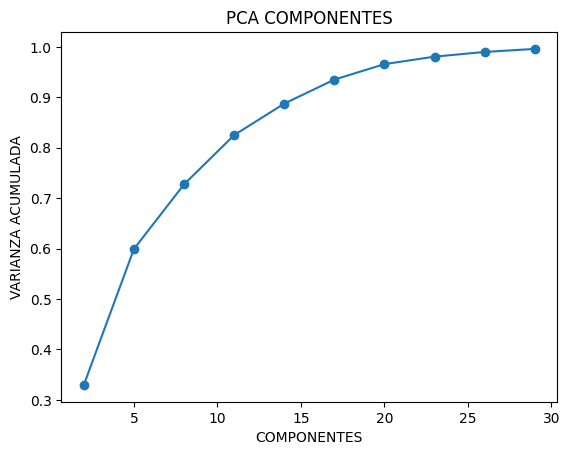

time: 3.05 s (started: 2026-03-22 13:05:06 +00:00)


In [ ]:
res_pca = []

for n_comp in range(2,30,3):
    pca = PCA(n_components=n_comp, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    res_pca.append({
        "n_components": n_comp,
        "var_ratio_individual": pca.explained_variance_ratio_,
        "var_ratio_sum": pca.explained_variance_ratio_.sum()
    })

for r in res_pca:
    print("Componentes:", r["n_components"])
    print("Varianza individual:", np.round(r["var_ratio_individual"], 4))
    print("Varianza acumulada:", round(r["var_ratio_sum"], 4))
    print("-" * 50)

df_pca = pd.DataFrame(res_pca)

fig, ax = plt.subplots()
ax.plot(df_pca["n_components"], df_pca["var_ratio_sum"], marker="o")
ax.set_xlabel("COMPONENTES")
ax.set_ylabel("VARIANZA ACUMULADA")
ax.set_title("PCA COMPONENTES")
plt.show()

**10 componentes son 80% de la información sin perder
15 son 90% y 20 son 96%, 25, 98% y 30 componentes, 99.7%, vamos a aplicar un pca equilibrado consistiendo del 50% de dimensiones, 98%, pca de 25 componentes**

In [ ]:
pca = PCA(n_components=25, random_state=42)
X_pca = dfc_pca = pd.DataFrame(pca.fit_transform(X_scaled))
dfx_scaled= pd.DataFrame(X_scaled)
dfc_pca.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,4.129250,6.124254,-0.356221,0.120343,-4.091409,-0.167307,0.662244,-0.206946,0.004929,-1.061927,...,0.607569,0.369986,0.403221,0.586569,0.054203,0.049597,0.204968,0.724177,0.178639,-0.045084
1,4.119678,6.121440,-0.352600,0.107253,-4.102926,-0.169818,0.590718,-0.219827,-0.067916,-1.052084,...,0.617444,0.386165,0.397715,0.574115,0.045205,0.068784,0.194588,0.650592,0.256682,-0.067130
2,4.134077,6.134750,-0.358375,0.123986,-4.109030,-0.170010,0.661363,-0.205641,0.004185,-1.056225,...,0.608038,0.369094,0.399652,0.583949,0.053724,0.049213,0.203116,0.720335,0.177489,-0.044256
3,4.122805,6.127758,-0.354630,0.110977,-4.114323,-0.170677,0.595723,-0.217923,-0.062830,-1.050271,...,0.616484,0.385149,0.395596,0.574397,0.045614,0.067041,0.194180,0.653713,0.250043,-0.064718
4,4.121358,6.121115,-0.353343,0.110078,-4.099037,-0.168844,0.607501,-0.216911,-0.050826,-1.055150,...,0.614989,0.382629,0.399215,0.577409,0.047358,0.064329,0.197147,0.668034,0.238532,-0.061969


time: 357 ms (started: 2026-03-22 13:05:09 +00:00)


In [ ]:
dfc_pca.shape
dfc_pca.to_csv(path + "dfc_pca_25d_comp.csv", index=False)

time: 7.28 s (started: 2026-03-22 13:05:09 +00:00)


### **TESTS PARA SABER GRUPOS ÓPTIMOS: INERCIA(CODO), SILHOUETTE (COMPACTACIÓN), DAVIES_BOULDIN (DISTANCIA RESPECTO CENTROIDE MÍO VS DEMÁS) Y CALINSKY-HARABASZ (COMPACTACIÓN + DEFINICIÓN)**

---



####**DEFINICIONES**

**dimensiones** = número de columnas/variables. PCA las reduce para simplificar los datos, perdiendo la menor información posible, comparar viendo mayor/mejor varianza.

**grupos** = número de agrupaciones o clases. Clustering intenta ver cuántos grupos naturales hay en los datos, no cuántos targets reales estan definidos ya, son targets calculados matemáticamente.

**Inercia (compactación):** cuanto menor, mejor compactación, (proporcional inversa a k), (distancia respecto a centroide)

**Silhouette (separación y comparación):** cuanto mayor, mejor agrupamiento ([-1,1] < 0 mal asignado, bajo incertidumbre y alto bien colocao) (cercanía/agrupamiento respecto de su grupo y vecinos)

**davies_bouldin (similitud entre clusters según su dispersión):** más bajo es mejor [0,1 o +], mezcla/media de dif(dist centroide mio-distcentroide no mio + cercano) entre más compactación de cada grupo y más separación respecto otros centroides,  0 buenisimo, [0.2,0.6] bueno en muschos problemas, [0.6,1] medio medio, >1 normalmente pésimo.

**Calinski-Harabasz (rel/variabilidad de dispersión entre clusters y en el cluster):** más alto, mejor, clusters muy separados entre sí + los puntos dentro de cada cluster están muy juntos, si ambas condiciones se cumplen mejor, (compactación/agrupamiento y definición entre clusters) [no hay rango] comparar y elegir el mayor (mejor).

####**TESTS, SELECCIÓN DE K Y CONCLUSIÓN**

In [ ]:
print(path)

/content/drive/MyDrive/open data/CYBER_TRABAJO/
time: 2.14 ms (started: 2026-03-22 13:05:17 +00:00)


#####**TESTS PCA**

---



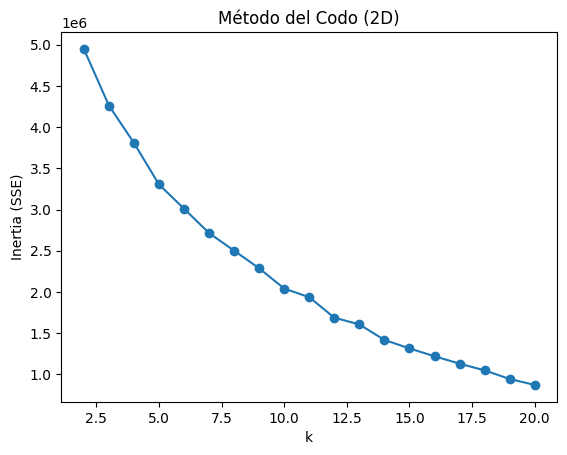

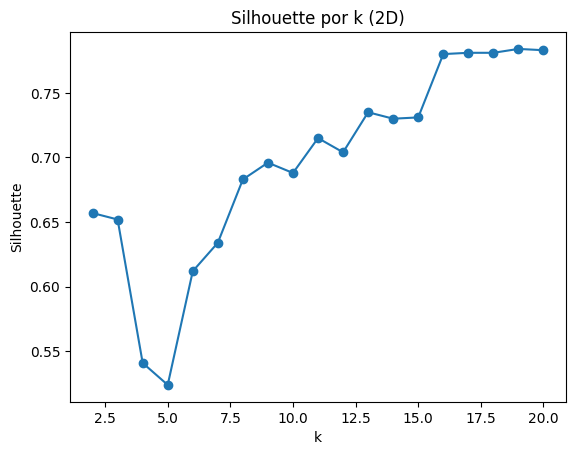

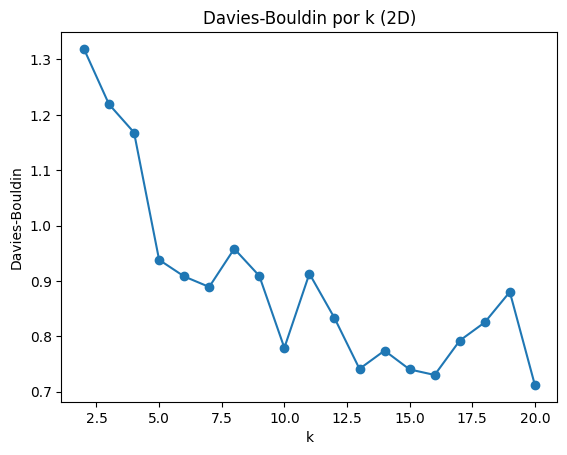

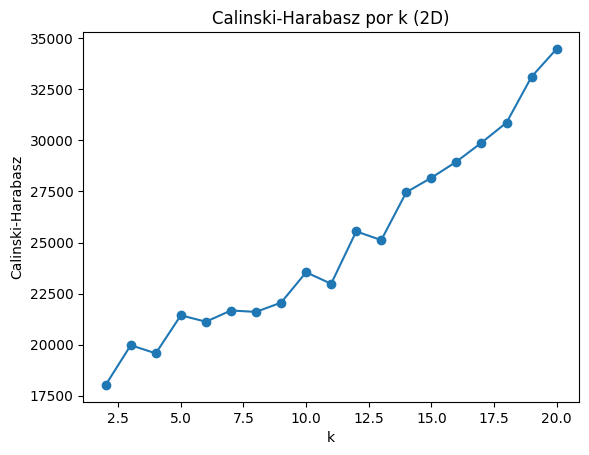

     k      inertia  silhouette  davies_bouldin  calinski_harabasz
0    2  4949756.165       0.657           1.319          18026.135
1    3  4262590.063       0.652           1.219          19970.740
2    4  3809485.766       0.541           1.168          19572.361
3    5  3304010.575       0.524           0.938          21434.868
4    6  3010347.654       0.612           0.908          21121.128
5    7  2713877.383       0.634           0.889          21670.399
6    8  2500110.752       0.683           0.958          21602.924
7    9  2285913.611       0.696           0.909          22054.713
8   10  2040248.094       0.688           0.779          23542.063
9   11  1935135.111       0.715           0.913          22979.023
10  12  1686756.960       0.704           0.833          25544.319
11  13  1604587.498       0.735           0.741          25117.678
12  14  1416745.312       0.730           0.774          27461.976
13  15  1313371.996       0.731           0.740          28170

In [ ]:
inertias, sils, dbs, chs = [], [], [], []
K_range = range(2, 21)#cuantos hacer
random_state = 42

if siluette_innertia:
    for k in K_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        km.fit(dfc_pca)

        inertias.append(km.inertia_)
        labels = km.labels_
        sils.append(silhouette_score(dfc_pca, labels))
        dbs.append(davies_bouldin_score(dfc_pca, labels))
        chs.append(calinski_harabasz_score(dfc_pca, labels))

    dfgrupos_clusters = pd.DataFrame({
        "k": list(K_range),
        "inertia": inertias,
        "silhouette": sils,
        "davies_bouldin": dbs,
        "calinski_harabasz": chs
    }).round(3)

    dfgrupos_clusters.to_csv(path + "dftests_clusters_gruposk.csv", index=False)

else:
    dfgrupos_clusters = pd.read_csv(path + "dftests_clusters_gruposk.csv")

    K_range = dfgrupos_clusters["k"].tolist()
    inertias = dfgrupos_clusters["inertia"].tolist()
    sils = dfgrupos_clusters["silhouette"].tolist()
    dbs = dfgrupos_clusters["davies_bouldin"].tolist()
    chs = dfgrupos_clusters["calinski_harabasz"].tolist()

fig, ax = plt.subplots()
ax.plot(list(K_range), inertias, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Inertia (SSE)")
ax.set_title("Método del Codo (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), sils, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette")
ax.set_title("Silhouette por k (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), dbs, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Davies-Bouldin")
ax.set_title("Davies-Bouldin por k (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), chs, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Calinski-Harabasz")
ax.set_title("Calinski-Harabasz por k (2D)")
plt.show()

print(dfgrupos_clusters)
print("posibles opciones 8,10,12,14,17")

#####**CONCLUSIONES TESTS PCA**

---



######**CONCLUSIONES DF ENTERO**
---

**Se observó que la inercia no aportó una decisión clara más allá de indicar que no existía un codo evidente. Silhouette y Davies-Bouldin señalaron que elegir un k= 14-17,20 era una opción sólida. Y Calinski-Harabasz, se apreciaron dos posibles agrupaciones: una con k >= 14, con buenos resultados, y otra con k >= 19, esta última la quitaremos ya que no queremos sobrefragmentar y acotamos por debajo de 16 al no coincidir en todas las métricas. Por tanto, se decidió mantener k = 17, ya que encaja dentro del rango actual y resultó ser una alternativa consistente al comparar las métricas de la otra selección ajustando d2 más proporcionalmente**


######**CONCLUSIONES D2 AJUSTADO**
---

**Es posible que, los valores de k como K=8 se asemejan a los tipos de paquetes, K=12 a los 12 subtipos originales del tráfico, consistentes en uno de ARP, dos de denegación de servicio, cinco de escaneo, tres de tráfico normal y uno de brute force SSH.**

**Los valores K=10 y K=14 también aparecen como agrupamientos adicionales, lo que sugiere símil entre subgrupos y, por tanto, más fáciles de generalizar y reducir, mientras que otros presentan mayor complejidad interna y pueden subdividirse en más subgrupos.**

**Finalmente, aunque se favorecen valores más altos de como 17 y 20, se produce un desacuerdo entre las medidas de davies y silouette ya que el primero define dispersión (fragmentación) y el segundo define que a mayor mejor agrupamiento, a partir de 18 estan mejor colocados respecto a vecinos, más cercanía pero hay menos equilibrio entre clusters y mayor fragmentación.**

**Por ello, k=17 se considera el mejor a nivel métrico, mientras que valores como k=12 o k=14 siguen siendo interpretables por su coorelación a los grupos iniciales, (aunque estos rean más relacionados con una cualidad del dataset, no los elegiremos por matematica y en su lugar los compararemos más tarde con su concentración con herramientas como el crosstab). Otros valores quedan descartados ya sea por sobrefragmentación, o mejores resultados**

#####**TESTS XSCALED**

---



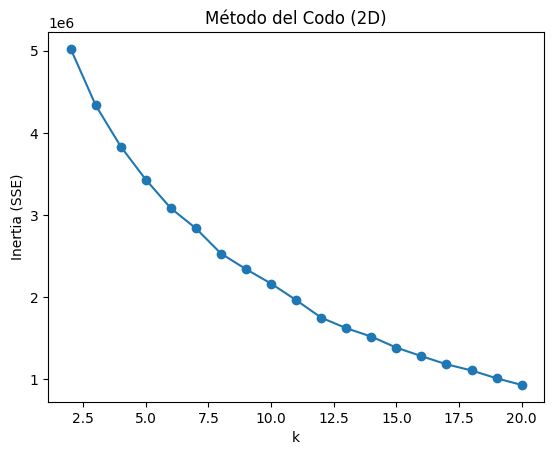

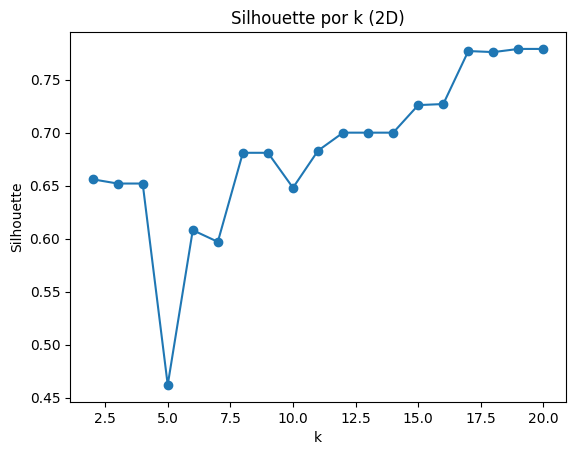

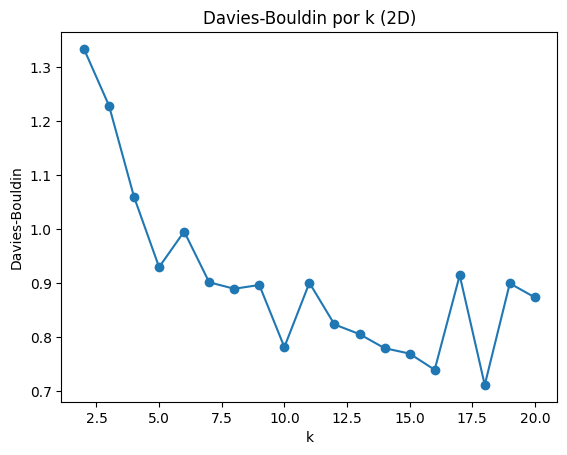

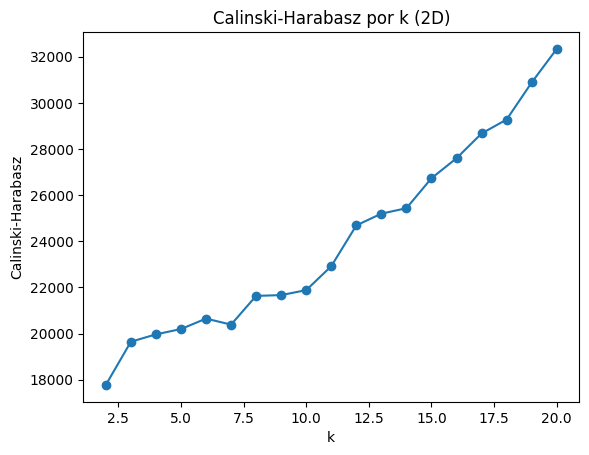

     k      inertia  silhouette  davies_bouldin  calinski_harabasz
0    2  5021344.764       0.656           1.334          17773.282
1    3  4334087.233       0.652           1.229          19644.937
2    4  3831836.344       0.652           1.060          19965.076
3    5  3429019.590       0.462           0.930          20195.693
4    6  3080798.967       0.608           0.996          20648.169
5    7  2836063.301       0.597           0.902          20387.383
6    8  2529590.384       0.681           0.890          21632.749
7    9  2339347.396       0.681           0.897          21666.450
8   10  2163917.657       0.648           0.782          21882.362
9   11  1962823.653       0.683           0.901          22919.647
10  12  1749245.335       0.700           0.824          24688.644
11  13  1621061.353       0.700           0.806          25197.559
12  14  1518911.752       0.700           0.780          25433.268
13  15  1384253.032       0.726           0.770          26733

In [ ]:
inertias, sils, dbs, chs = [], [], [], []
K_range = range(2, 21)#cuantos hacer
random_state = 42

if siluette_innertia2:
    for k in K_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        km.fit(dfx_scaled)

        inertias.append(km.inertia_)
        labels = km.labels_
        sils.append(silhouette_score(dfx_scaled, labels))
        dbs.append(davies_bouldin_score(dfx_scaled, labels))
        chs.append(calinski_harabasz_score(dfx_scaled, labels))

    dfgrupos_clusters_xscaled = pd.DataFrame({
        "k": list(K_range),
        "inertia": inertias,
        "silhouette": sils,
        "davies_bouldin": dbs,
        "calinski_harabasz": chs
    }).round(3)

    dfgrupos_clusters_xscaled.to_csv(path + "dftests_clusters_gruposk_xscaled.csv", index=False)

else:
    dfgrupos_clusters_xscaled = pd.read_csv(path + "dftests_clusters_gruposk_xscaled.csv")

    K_range = dfgrupos_clusters_xscaled["k"].tolist()
    inertias = dfgrupos_clusters_xscaled["inertia"].tolist()
    sils = dfgrupos_clusters_xscaled["silhouette"].tolist()
    dbs = dfgrupos_clusters_xscaled["davies_bouldin"].tolist()
    chs = dfgrupos_clusters_xscaled["calinski_harabasz"].tolist()

fig, ax = plt.subplots()
ax.plot(list(K_range), inertias, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Inertia (SSE)")
ax.set_title("Método del Codo (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), sils, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette")
ax.set_title("Silhouette por k (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), dbs, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Davies-Bouldin")
ax.set_title("Davies-Bouldin por k (2D)")
plt.show()

fig, ax = plt.subplots()
ax.plot(list(K_range), chs, marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Calinski-Harabasz")
ax.set_title("Calinski-Harabasz por k (2D)")
plt.show()

print(dfgrupos_clusters_xscaled)
print("posibles opciones 8,10,12,14,17")

#####**CONCLUSIONES TESTS ESCALADO (SIN PCA)**

---



######**CONCLUSIONES DF ENTERO**
---
**La inercia no mostró un codo claro. Silhouette y Calinski-Harabasz señalaron que los mejores resultados eran valores altos de k, especialmente a partir de 16–17. Pero Davies-Bouldin introdujo algo de duda, favoreciendo más bien de 13-16 o 18 frente a 17 con un pico que lo bajaba de posición a los 10. Aun así, como 17 seguía estando en una zona muy buena según el resto de métricas y además coincidía con los análisis previos, y por tanto, se mantuvo como una agrupación coherente.**
######**CONCLUSIONES D2 AJUSTADO**
---
**Clara intención de k=19 matemáticamente, pero otros candidatos incluyen k=3,7,10 o 15**

###**ENTRENO KMEANS CON K SELECCIONADO Y GRÁFICOS SEGÚN KS**

---



#####**PCA K=17**

In [ ]:
X_pca = dfc_pca.values

k_opt = 17
kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_pca)

inn = kmeans.inertia_
sil = silhouette_score(X_pca, labels)
db = davies_bouldin_score(X_pca, labels)
ch = calinski_harabasz_score(X_pca, labels)

print(f"k={k_opt} | inertia={inn:.3f} | silhouette={sil:.3f} | Davies-Bouldin={db:.3f} | Calinski-Harabasz={ch:.3f}")

#CLUSTERS EN DFC
dfc["cluster_pca_25d"] = labels

#centros en espacio PCA
centers_pca = kmeans.cluster_centers_

#INVERSE
centers_scaled_aprox = pca.inverse_transform(centers_pca)
centers_orig_aprox = scaler.inverse_transform(centers_scaled_aprox)

#CENTROS_DF K=17
centros_df = pd.DataFrame(centers_orig_aprox, columns=X.columns)
display(centros_df.round(2))

centros_df.to_csv(path + "centroskm_k17_25dpca.csv", index=False)

k=17 | inertia=1128659.150 | silhouette=0.781 | Davies-Bouldin=0.792 | Calinski-Harabasz=29888.345


,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,inactive_avg,inactive_std,inactive_tot,fwd_init_window_size,fwd_last_window_size,bwd_init_window_size,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate
0,-0.06,1.99,2014051.54,1.00,1.198603e+08,1.01,0.98,1.03,-0.06,1007014.33,...,-0.01,-0.00,-0.06,-424.42,116.85,125.59,119.54,-1.55,-80.69,607.84
1,0.12,2.03,525476.34,1.00,3.125662e+07,0.98,1.05,0.93,0.12,262761.48,...,0.01,0.00,0.11,958.34,22.05,-174.25,116.20,-24.26,120.42,-923.63
2,-5.39,11850.73,-573.01,5.68,-2.162410e+06,1677.48,10173.26,3.06,10171.59,1854.10,...,5.15,9.34,-38.66,57226.40,22789.48,61357.66,-160.81,2340152.64,63212.18,580355.92
3,57.60,16.79,-1733.52,0.60,-1.952365e+05,10.49,6.30,3.56,3.71,-823.53,...,47.22,0.62,55.41,61767.26,662.40,28694.35,39.22,-16.90,-73.33,8181.80
4,8.98,13.70,-139.51,0.71,1.626487e+05,8.01,5.69,2.42,1.76,123.88,...,4.18,0.23,7.52,61245.97,771.26,33219.09,202.33,136.28,2097.40,2815.70
5,7029.39,1093.80,-21073.98,0.50,9.352842e+05,750.62,343.18,558.54,244.33,-10634.96,...,28.56,8.19,6529.95,19628.02,2692.89,24638.70,454.44,17798.69,20496.52,334210.04
6,-0.04,1.00,-4434.42,-0.00,8.957375e+05,1.13,-0.13,1.12,-0.09,-2106.39,...,-0.08,0.01,-0.09,1335.30,42.05,-102.75,121.89,123.72,218.93,-1517.16
7,24.34,2.13,-76883.97,-0.19,8.932393e+06,6.29,-4.16,6.38,-6.50,-38616.20,...,20.57,1.75,24.94,1030.13,625.92,5965.51,57.04,2363.70,560.55,28560.73
8,0.11,1.89,351987.82,0.99,-3.000764e+05,0.99,0.90,-0.00,-0.05,175999.26,...,0.14,0.00,0.11,1302.80,967.82,-199.33,-0.05,181.17,153.47,-1034.86
9,1183.03,4638.92,52714.07,1.78,-1.637676e+06,1857.87,2781.04,588.99,2276.15,26664.05,...,51.87,11.87,1006.75,63798.87,-1118.34,51711.36,8971.30,293088.00,638299.04,589703.32


time: 3min 24s (started: 2026-03-22 13:05:19 +00:00)


#####**GRÁFICOS DE CLUSTERS DEL PCA SEGÚN K**

In [ ]:
if graficos_pca_clusters:
  ks = [2,4, 8, 10, 12, 17, 20]

  X_pca = dfc_pca.values

  for k_opt in ks:
      kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
      labels = kmeans.fit_predict(X_pca)

      inn = kmeans.inertia_
      sil = silhouette_score(X_pca, labels)
      db = davies_bouldin_score(X_pca, labels)
      ch = calinski_harabasz_score(X_pca, labels)

      print(f"k={k_opt} | inertia={inn:.3f} | silhouette={sil:.3f} | Davies-Bouldin={db:.3f} | Calinski-Harabasz={ch:.3f}")

      #CLUSTERS EN DFC
      col_cluster = f"cluster_pca_25d_k{k_opt}"
      dfc[col_cluster] = labels

      #centros en espacio PCA
      centers_pca = kmeans.cluster_centers_

      #INVERSE
      centers_scaled_aprox = pca.inverse_transform(centers_pca)
      centers_orig_aprox = scaler.inverse_transform(centers_scaled_aprox)

      #CENTROS_DF
      centros_df = pd.DataFrame(centers_orig_aprox, columns=X.columns)
      print(f"\nCENTROS_DF k={k_opt}")
      display(centros_df.round(2))

      #TABLAS
      tabla = pd.crosstab(dfc[col_cluster], dfc["attack_flag"])
      tabla2 = pd.crosstab(dfc[col_cluster], dfc["attack_groupstr"])
      tabla3 = pd.crosstab(dfc[col_cluster], dfc["attack_type"])

      #PLOTS 3 EN 1 FILA
      fig, ax = plt.subplots(1, 3, figsize=(24, 6))

      tabla.plot(kind="bar", stacked=True, ax=ax[0])
      ax[0].set_xlabel(col_cluster)
      ax[0].set_ylabel("count")
      ax[0].set_title(f"Attack_flag por cluster k={k_opt}")
      ax[0].legend(title="attack_flag")

      tabla2.plot(kind="bar", stacked=True, ax=ax[1])
      ax[1].set_xlabel(col_cluster)
      ax[1].set_ylabel("count")
      ax[1].set_title(f"Attack_groupstr por cluster k={k_opt}")
      ax[1].legend(title="attack_groupstr")

      tabla3.plot(kind="bar", stacked=True, ax=ax[2])
      ax[2].set_xlabel(col_cluster)
      ax[2].set_ylabel("count")
      ax[2].set_title(f"Attack_type por cluster k={k_opt}")
      ax[2].legend(title="attack_type")

      plt.tight_layout()
      plt.show()

time: 2.47 ms (started: 2026-03-22 13:08:43 +00:00)


#####**GRÁFICOS DE CLUSTERS DEL ESCALADO (SIN PCA) SEGÚN K**

In [ ]:
if graficos_xscaled_clusters:
  ks = [2,4, 8, 10, 12, 17, 19, 20]

  X_scaled_data = dfx_scaled.values

  for k_opt in ks:
      kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
      labels = kmeans.fit_predict(X_scaled_data)

      inn = kmeans.inertia_
      sil = silhouette_score(X_scaled_data, labels)
      db = davies_bouldin_score(X_scaled_data, labels)
      ch = calinski_harabasz_score(X_scaled_data, labels)

      print(f"k={k_opt} | inertia={inn:.3f} | silhouette={sil:.3f} | Davies-Bouldin={db:.3f} | Calinski-Harabasz={ch:.3f}")

      #CLUSTERS EN DFC
      col_cluster = f"cluster_xscaled_k{k_opt}"
      dfc[col_cluster] = labels

      #centros en espacio escalado
      centers_scaled = kmeans.cluster_centers_

      #INVERSE
      centers_orig_aprox = scaler.inverse_transform(centers_scaled)

      #CENTROS_DF
      centros_df = pd.DataFrame(centers_orig_aprox, columns=X.columns)
      print(f"\nCENTROS_DF k={k_opt}")
      display(centros_df.round(2))

      #TABLAS
      tabla = pd.crosstab(dfc[col_cluster], dfc["attack_flag"])
      tabla2 = pd.crosstab(dfc[col_cluster], dfc["attack_groupstr"])
      tabla3 = pd.crosstab(dfc[col_cluster], dfc["attack_type"])

      #PLOTS 3 EN 1 FILA
      fig, ax = plt.subplots(1, 3, figsize=(24, 6))

      tabla.plot(kind="bar", stacked=True, ax=ax[0])
      ax[0].set_xlabel(col_cluster)
      ax[0].set_ylabel("count")
      ax[0].set_title(f"Attack_flag por cluster k={k_opt}")
      ax[0].legend(title="attack_flag")

      tabla2.plot(kind="bar", stacked=True, ax=ax[1])
      ax[1].set_xlabel(col_cluster)
      ax[1].set_ylabel("count")
      ax[1].set_title(f"Attack_groupstr por cluster k={k_opt}")
      ax[1].legend(title="attack_groupstr")

      tabla3.plot(kind="bar", stacked=True, ax=ax[2])
      ax[2].set_xlabel(col_cluster)
      ax[2].set_ylabel("count")
      ax[2].set_title(f"Attack_type por cluster k={k_opt}")
      ax[2].legend(title="attack_type")

      plt.tight_layout()
      plt.show()

time: 2.39 ms (started: 2026-03-22 13:08:43 +00:00)


#####**¿Qué k es mejor?**

---



* **PCA mejor k métrico: 17/20**
* **PCA mejor k métrico alld2: 16/17**
---
* **PCA mejor k gráfico: 12**
* **PCA mejor k gráfico alld2: 12**
---
* **Scaled mejor k métrico : 19/20**
* **Scaled mejor k métrico alld2: 16/18**
---
* **Scaled mejor k gráfico: 10**
* **Scaled mejor k gráfico alld2: 12**
---
**GANADOR MÉTRICO 17, GANADOR GRÁFICO K=12**

**MEJOR DE TODOS, 17 O 12-> 17 (YA COMPROBADO)**

###**FUZZY C-MEANS**

---



####**COMPROBACIÓN FPC (NÍTIDEZ)**

---



In [ ]:
k_opt = 17
random_state = 42

time: 747 µs (started: 2026-03-22 13:08:43 +00:00)


**El indicador fpc que indica la nítidez es de 0.74, con d2 mitigado y 0.84 con todo d2, indicando poca ambigüedad al estar cerca de 1**

In [ ]:
data = X_pca.T # Datos como matriz (features x samples) para skfuzzy

'''
cmeans devuelve:
cntr=centros difusos de los clusters
u=matriz de pertenencias difusas
   forma=(c,n_muestras)
   cada columna es una muestra
   cada fila es un cluster
   u[i,j]=grado de pertenencia de la muestra j al cluster i
u0=matriz inicial de pertenencias usada al empezar
d=matriz de distancias de cada muestra a cada centro
jm=historial de la funcion objetivo en las iteraciones
p=numero de iteraciones realizadas
fpc=Fuzzy Partition Coefficient
   mide lo "nítida" que es la partición
   cuanto mas cerca de 1, menos ambigüedad general
'''

cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data, c=k_opt, m=2.0, error=1e-5, maxiter=1000, init=None, seed=random_state)

print("FPC (Fuzzy Partition Coefficient):", round(fpc, 3))

# Afiliación dominante y grados de pertenencia
labels_fuzzy = u.argmax(axis=0)
dfc["cluster_fuzzy"] = labels_fuzzy
dfc["fuzzy_max_membership"] = u.max(axis=0)

display(dfc.head())

FPC (Fuzzy Partition Coefficient): 0.866


,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate,attack_type,attack_groupstr,attack_flag,cluster_pca_25d,cluster_fuzzy,fuzzy_max_membership
0,32.011598,14,0.437341,0.555556,3.373777,9,5,3,3,0.281148,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.990113
1,31.883584,14,0.439097,0.555556,3.387323,9,5,3,3,0.282277,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.990425
2,32.124053,14,0.435811,0.555556,3.237450,9,5,3,3,0.280164,...,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991057
3,31.961063,14,0.438033,0.555556,3.253959,9,5,3,3,0.281593,...,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991179
4,31.902362,14,0.438839,0.555556,3.385329,9,5,3,3,0.282111,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991223


time: 1min 5s (started: 2026-03-22 13:08:43 +00:00)


####**DATAFRAME CON GRADOS DE PERTENENCIA PCAD**

---



In [ ]:
# FASE 10: CONSTRUIR DATAFRAME CON GRADOS DE PERTENENCIA POR CLÚSTER

# u tiene forma (c, n_muestras). Lo transponemos a (n_muestras, c)
memb_df = pd.DataFrame(u.T, columns=[f"memb_c{i}" for i in range(k_opt)])

memb_df.to_csv(path + "pertenencia_memb_fuzzy.csv", index=False)

# Unimos al dataframe original
df_fuzzy = pd.concat([dfc.reset_index(drop=True), memb_df], axis=1)

# Ordenamos por casos más "ambiguos" (baja pertenencia máxima)
df_fuzzy["fuzzy_max_membership"] = df_fuzzy[[f"memb_c{i}" for i in range(k_opt)]].max(axis=1)
df_fuzzy["cluster_fuzzy"] = df_fuzzy[[f"memb_c{i}" for i in range(k_opt)]].idxmax(axis=1).str.replace("memb_c","").astype(int)
df_fuzzy = df_fuzzy.sort_values("fuzzy_max_membership", ascending=True)

# Vista rápida
display(df_fuzzy.head(10))


,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,memb_c7,memb_c8,memb_c9,memb_c10,memb_c11,memb_c12,memb_c13,memb_c14,memb_c15,memb_c16
115911,905.964201,903,0.996728,0.000000,44.352746,903,0,903,0,0.996728,...,0.058760,0.058696,0.058757,0.058817,0.058973,0.058847,0.058733,0.058929,0.058955,0.058846
3565,56.047646,11773,210.053425,6.087899,242839.547426,1661,10112,1,10105,29.635500,...,0.058755,0.058737,0.058733,0.058827,0.058839,0.058983,0.058751,0.058828,0.058830,0.058974
11827,9433.886888,1887,0.200024,0.000000,34.404059,1887,0,1887,0,0.200024,...,0.058775,0.058663,0.058764,0.058797,0.058915,0.058822,0.058726,0.058952,0.058936,0.058838
12014,21728.335580,4345,0.199969,0.000000,34.394719,4345,0,4345,0,0.199969,...,0.058760,0.058695,0.058744,0.058801,0.058883,0.058864,0.058728,0.058973,0.058921,0.058868
11929,17747.121108,3549,0.199976,0.000000,34.395889,3549,0,3549,0,0.199976,...,0.058752,0.058664,0.058734,0.058796,0.058899,0.058861,0.058710,0.058996,0.058941,0.058869
11852,6828.456767,1344,0.196823,0.000000,33.853623,1344,0,1344,0,0.196823,...,0.058777,0.058562,0.058763,0.058773,0.058963,0.058758,0.058685,0.059025,0.059005,0.058800
115910,883.106953,882,0.998747,0.000000,44.487250,882,0,882,0,0.998747,...,0.058694,0.058587,0.058683,0.058832,0.059183,0.058941,0.058646,0.059083,0.059141,0.058931
12970,243.436837,5948,24.433443,1.746076,19893.028770,2166,3782,172,3709,8.897585,...,0.058590,0.058564,0.058561,0.058817,0.058927,0.059247,0.058594,0.058935,0.058915,0.059237
12013,18761.401290,1109,0.059111,0.575284,3.110802,704,405,359,371,0.037524,...,0.058596,0.058553,0.058586,0.058756,0.059011,0.058899,0.058581,0.059383,0.059170,0.058926
13987,62.352378,57,0.914159,0.727273,388.196902,33,24,15,9,0.529250,...,0.058625,0.058321,0.058568,0.059018,0.058803,0.059191,0.058669,0.058559,0.058747,0.059274


time: 6.15 s (started: 2026-03-22 13:09:49 +00:00)


In [ ]:
display(memb_df)


,memb_c0,memb_c1,memb_c2,memb_c3,memb_c4,memb_c5,memb_c6,memb_c7,memb_c8,memb_c9,memb_c10,memb_c11,memb_c12,memb_c13,memb_c14,memb_c15,memb_c16
0,0.000461,0.000336,0.000531,0.000368,0.000380,0.000496,0.000487,0.000375,0.000204,0.000353,0.000617,0.002908,0.000200,0.000392,0.001520,0.990113,0.000258
1,0.000447,0.000326,0.000516,0.000357,0.000369,0.000483,0.000473,0.000364,0.000198,0.000343,0.000598,0.002791,0.000194,0.000381,0.001484,0.990425,0.000250
2,0.000417,0.000305,0.000480,0.000333,0.000344,0.000449,0.000441,0.000339,0.000185,0.000320,0.000558,0.002610,0.000182,0.000355,0.001392,0.991057,0.000234
3,0.000412,0.000301,0.000475,0.000329,0.000340,0.000444,0.000436,0.000335,0.000183,0.000316,0.000551,0.002561,0.000179,0.000351,0.001377,0.991179,0.000231
4,0.000410,0.000299,0.000473,0.000327,0.000338,0.000442,0.000434,0.000333,0.000181,0.000314,0.000548,0.002566,0.000178,0.000349,0.001356,0.991223,0.000230
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117917,0.000016,0.000015,0.000032,0.000030,0.000026,0.000031,0.000035,0.000031,0.999623,0.000029,0.000022,0.000023,0.000012,0.000027,0.000014,0.000019,0.000014
117918,0.000013,0.000012,0.000026,0.000024,0.000021,0.000025,0.000028,0.000025,0.999697,0.000023,0.000018,0.000019,0.000010,0.000022,0.000011,0.000016,0.000011
117919,0.000016,0.000015,0.000032,0.000030,0.000026,0.000031,0.000035,0.000031,0.999623,0.000029,0.000022,0.000023,0.000012,0.000027,0.000014,0.000019,0.000014
117920,0.000016,0.000015,0.000032,0.000030,0.000026,0.000031,0.000035,0.000031,0.999623,0.000029,0.000022,0.000023,0.000012,0.000027,0.000014,0.000019,0.000014


time: 19.5 ms (started: 2026-03-22 13:09:55 +00:00)


####**CENTROIDES FUZZY PCAD**

---



In [ ]:
# Centroides fuzzy en valores reales
cntr_nopca= pca.inverse_transform(cntr)
cntr_real = scaler.inverse_transform(cntr_nopca)
centros_fuzzy_df = pd.DataFrame(cntr_real, columns=X.columns)
display(centros_fuzzy_df.round(2))

centros_fuzzy_df.to_csv(path + "centroides_fuzzy.csv", index=False)
dfc

,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,inactive_avg,inactive_std,inactive_tot,fwd_init_window_size,fwd_last_window_size,bwd_init_window_size,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate
0,41.90,33.49,46515.70,0.89,-3.605931e+05,18.15,15.34,8.22,8.38,23165.58,...,11.32,0.73,39.06,68438.93,2642.46,48339.07,817.60,4769.30,45657.26,345093.21
1,24.86,30.75,14639.95,0.85,1.409625e+06,16.90,13.84,7.10,7.57,7389.86,...,8.21,0.41,22.67,64136.92,1955.90,38446.45,951.96,5602.80,31079.64,287140.89
2,0.17,2.02,474424.01,1.00,2.842272e+07,0.98,1.04,0.94,0.11,237239.72,...,0.02,0.00,0.16,1087.27,-63.59,-305.59,120.45,6.16,190.87,-1221.87
3,-0.61,4.26,15129.70,0.97,-7.134194e+05,2.29,1.97,2.63,1.61,7237.36,...,-0.05,0.00,-0.70,-4428.02,681.19,1087.58,90.61,1452.86,1671.71,14148.78
4,-0.12,0.96,-4078.59,-0.01,9.806415e+05,1.08,-0.11,1.04,-0.09,-1919.44,...,-0.15,0.00,-0.12,1619.47,65.81,-157.97,118.70,102.71,351.42,-933.87
5,0.20,2.07,1014084.53,1.00,6.043122e+07,1.02,1.05,0.98,0.08,507056.34,...,0.03,0.00,0.18,663.23,56.26,-120.71,120.99,10.23,296.51,637.06
6,-0.59,2.60,254167.55,1.00,9.264623e+06,1.02,1.58,0.79,0.74,127032.04,...,-0.28,-0.03,-0.54,-178.81,2689.74,3268.30,3.69,-815.82,197.44,15800.83
7,-1.01,4.39,10193.69,0.96,-1.499394e+06,2.10,2.29,2.62,1.73,4819.31,...,-0.30,-0.01,-1.02,-4383.38,457.58,984.33,68.56,521.56,-208.30,4541.15
8,0.45,2.07,322072.06,1.00,-2.055266e+06,1.08,0.99,0.06,0.02,161039.74,...,0.17,0.01,0.42,1403.09,1004.48,-150.00,2.23,201.43,860.74,2178.42
9,1.33,1.16,10294.62,0.04,-1.287548e+06,1.07,0.09,0.12,0.43,5420.82,...,0.22,0.01,1.28,337.96,-199.73,-225.26,45.29,-902.14,12.67,3707.80


,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate,attack_type,attack_groupstr,attack_flag,cluster_pca_25d,cluster_fuzzy,fuzzy_max_membership
0,32.011598,14,0.437341,0.555556,3.373777,9,5,3,3,0.281148,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.990113
1,31.883584,14,0.439097,0.555556,3.387323,9,5,3,3,0.282277,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.990425
2,32.124053,14,0.435811,0.555556,3.237450,9,5,3,3,0.280164,...,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991057
3,31.961063,14,0.438033,0.555556,3.253959,9,5,3,3,0.281593,...,24.666667,10.000000,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991179
4,31.902362,14,0.438839,0.555556,3.385329,9,5,3,3,0.282111,...,25.333333,10.666667,0.0,0.0,MQTT_Publish,normal,0,3,15,0.991223
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117917,0.000006,2,335544.320000,1.000000,0.000000,1,1,0,0,167772.160000,...,0.000000,0.000000,0.0,0.0,NMAP_XMAS_TREE_SCAN,scan,1,8,8,0.999623
117918,0.000007,2,289262.344800,1.000000,0.000000,1,1,0,0,144631.172400,...,0.000000,0.000000,0.0,0.0,NMAP_XMAS_TREE_SCAN,scan,1,8,8,0.999697
117919,0.000006,2,335544.320000,1.000000,0.000000,1,1,0,0,167772.160000,...,0.000000,0.000000,0.0,0.0,NMAP_XMAS_TREE_SCAN,scan,1,8,8,0.999623
117920,0.000006,2,335544.320000,1.000000,0.000000,1,1,0,0,167772.160000,...,0.000000,0.000000,0.0,0.0,NMAP_XMAS_TREE_SCAN,scan,1,8,8,0.999623


time: 594 ms (started: 2026-03-22 13:09:55 +00:00)


###**CONCLUSIONES Y COMPARACIÓN DE CLUSTERINGS**

---



####**COMPARACIÓN DE CLUSTERS KMEANS Y DIFUSOS**

---



#####**COMPARACIÓN POR TARGETS Y GRÁFICOS DE GRUPOS**

---



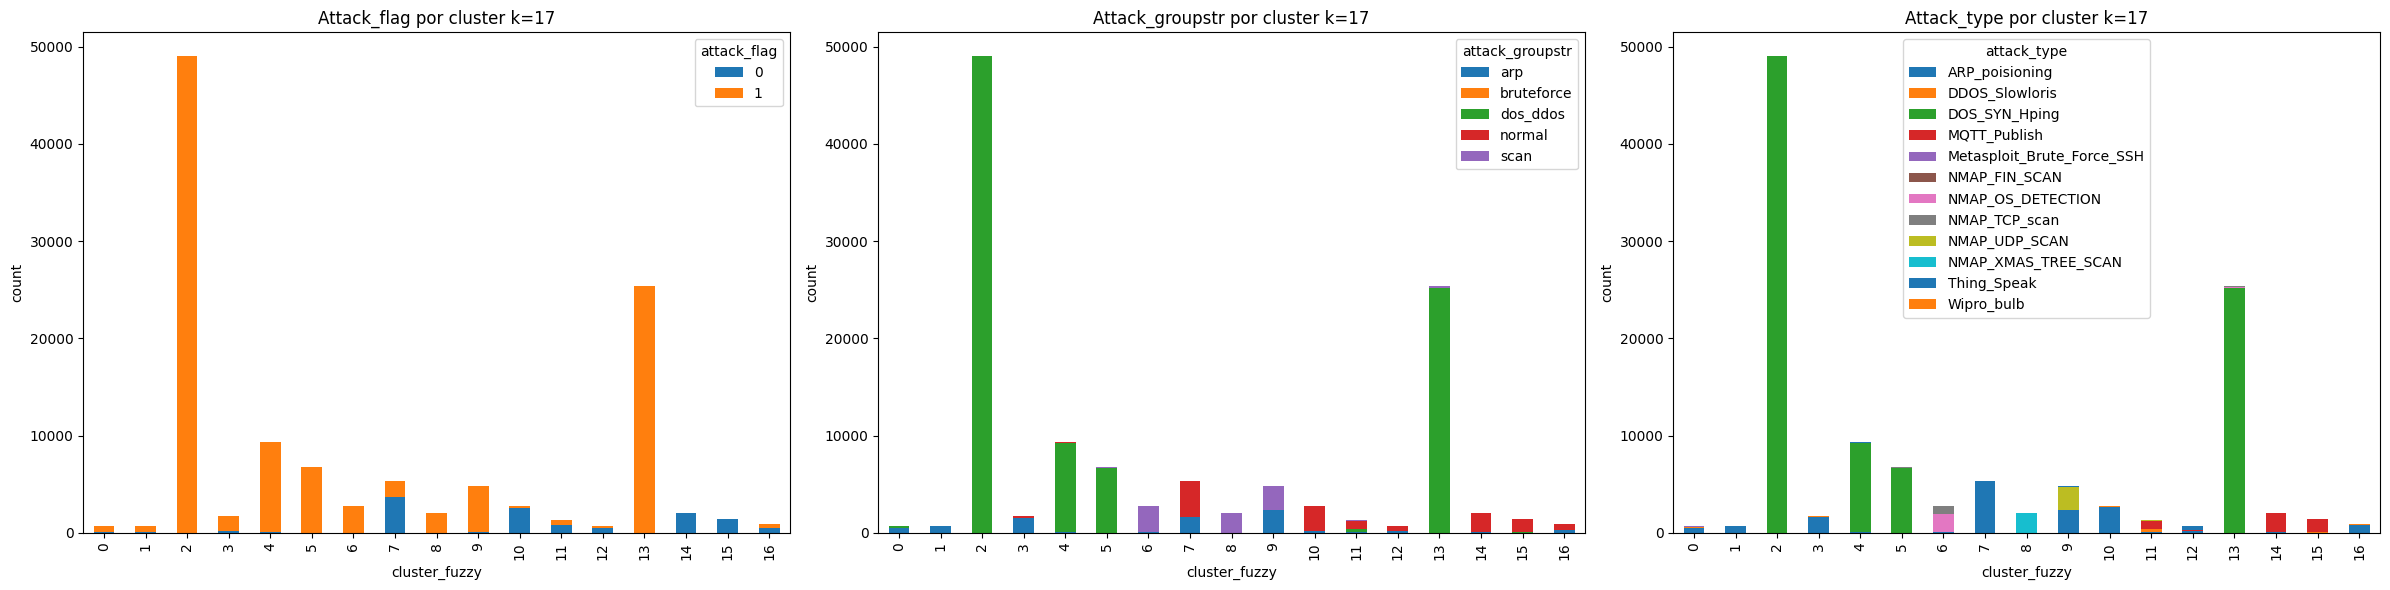

time: 1.43 s (started: 2026-03-22 13:09:56 +00:00)


In [ ]:
#tablas
tabla = pd.crosstab(dfc['cluster_fuzzy'], dfc["attack_flag"])
tabla2 = pd.crosstab(dfc['cluster_fuzzy'], dfc["attack_groupstr"])
tabla3 = pd.crosstab(dfc['cluster_fuzzy'], dfc["attack_type"])

#plots 3 en 1 fila
fig, ax = plt.subplots(1, 3, figsize=(24, 6))

tabla.plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set_xlabel('cluster_fuzzy')
ax[0].set_ylabel("count")
ax[0].set_title(f"Attack_flag por cluster k={k_opt}")
ax[0].legend(title="attack_flag")

tabla2.plot(kind="bar", stacked=True, ax=ax[1])
ax[1].set_xlabel('cluster_fuzzy')
ax[1].set_ylabel("count")
ax[1].set_title(f"Attack_groupstr por cluster k={k_opt}")
ax[1].legend(title="attack_groupstr")

tabla3.plot(kind="bar", stacked=True, ax=ax[2])
ax[2].set_xlabel('cluster_fuzzy')
ax[2].set_ylabel("count")
ax[2].set_title(f"Attack_type por cluster k={k_opt}")
ax[2].legend(title="attack_type")

plt.tight_layout()
plt.show()

k=17 | inertia=1128659.150 | silhouette=0.781 | Davies-Bouldin=0.792 | Calinski-Harabasz=29888.345

CENTROS_DF k=17


,flow_duration,pkts_tot,flow_pkts_per_sec,down_up_ratio,payload_BPS,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,inactive_avg,inactive_std,inactive_tot,fwd_init_window_size,fwd_last_window_size,bwd_init_window_size,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_rate,bwd_bulk_rate
0,-0.06,1.99,2014051.54,1.00,1.198603e+08,1.01,0.98,1.03,-0.06,1007014.33,...,-0.01,-0.00,-0.06,-424.42,116.85,125.59,119.54,-1.55,-80.69,607.84
1,0.12,2.03,525476.34,1.00,3.125662e+07,0.98,1.05,0.93,0.12,262761.48,...,0.01,0.00,0.11,958.34,22.05,-174.25,116.20,-24.26,120.42,-923.63
2,-5.39,11850.73,-573.01,5.68,-2.162410e+06,1677.48,10173.26,3.06,10171.59,1854.10,...,5.15,9.34,-38.66,57226.40,22789.48,61357.66,-160.81,2340152.64,63212.18,580355.92
3,57.60,16.79,-1733.52,0.60,-1.952365e+05,10.49,6.30,3.56,3.71,-823.53,...,47.22,0.62,55.41,61767.26,662.40,28694.35,39.22,-16.90,-73.33,8181.80
4,8.98,13.70,-139.51,0.71,1.626487e+05,8.01,5.69,2.42,1.76,123.88,...,4.18,0.23,7.52,61245.97,771.26,33219.09,202.33,136.28,2097.40,2815.70
5,7029.39,1093.80,-21073.98,0.50,9.352842e+05,750.62,343.18,558.54,244.33,-10634.96,...,28.56,8.19,6529.95,19628.02,2692.89,24638.70,454.44,17798.69,20496.52,334210.04
6,-0.04,1.00,-4434.42,-0.00,8.957375e+05,1.13,-0.13,1.12,-0.09,-2106.39,...,-0.08,0.01,-0.09,1335.30,42.05,-102.75,121.89,123.72,218.93,-1517.16
7,24.34,2.13,-76883.97,-0.19,8.932393e+06,6.29,-4.16,6.38,-6.50,-38616.20,...,20.57,1.75,24.94,1030.13,625.92,5965.51,57.04,2363.70,560.55,28560.73
8,0.11,1.89,351987.82,0.99,-3.000764e+05,0.99,0.90,-0.00,-0.05,175999.26,...,0.14,0.00,0.11,1302.80,967.82,-199.33,-0.05,181.17,153.47,-1034.86
9,1183.03,4638.92,52714.07,1.78,-1.637676e+06,1857.87,2781.04,588.99,2276.15,26664.05,...,51.87,11.87,1006.75,63798.87,-1118.34,51711.36,8971.30,293088.00,638299.04,589703.32


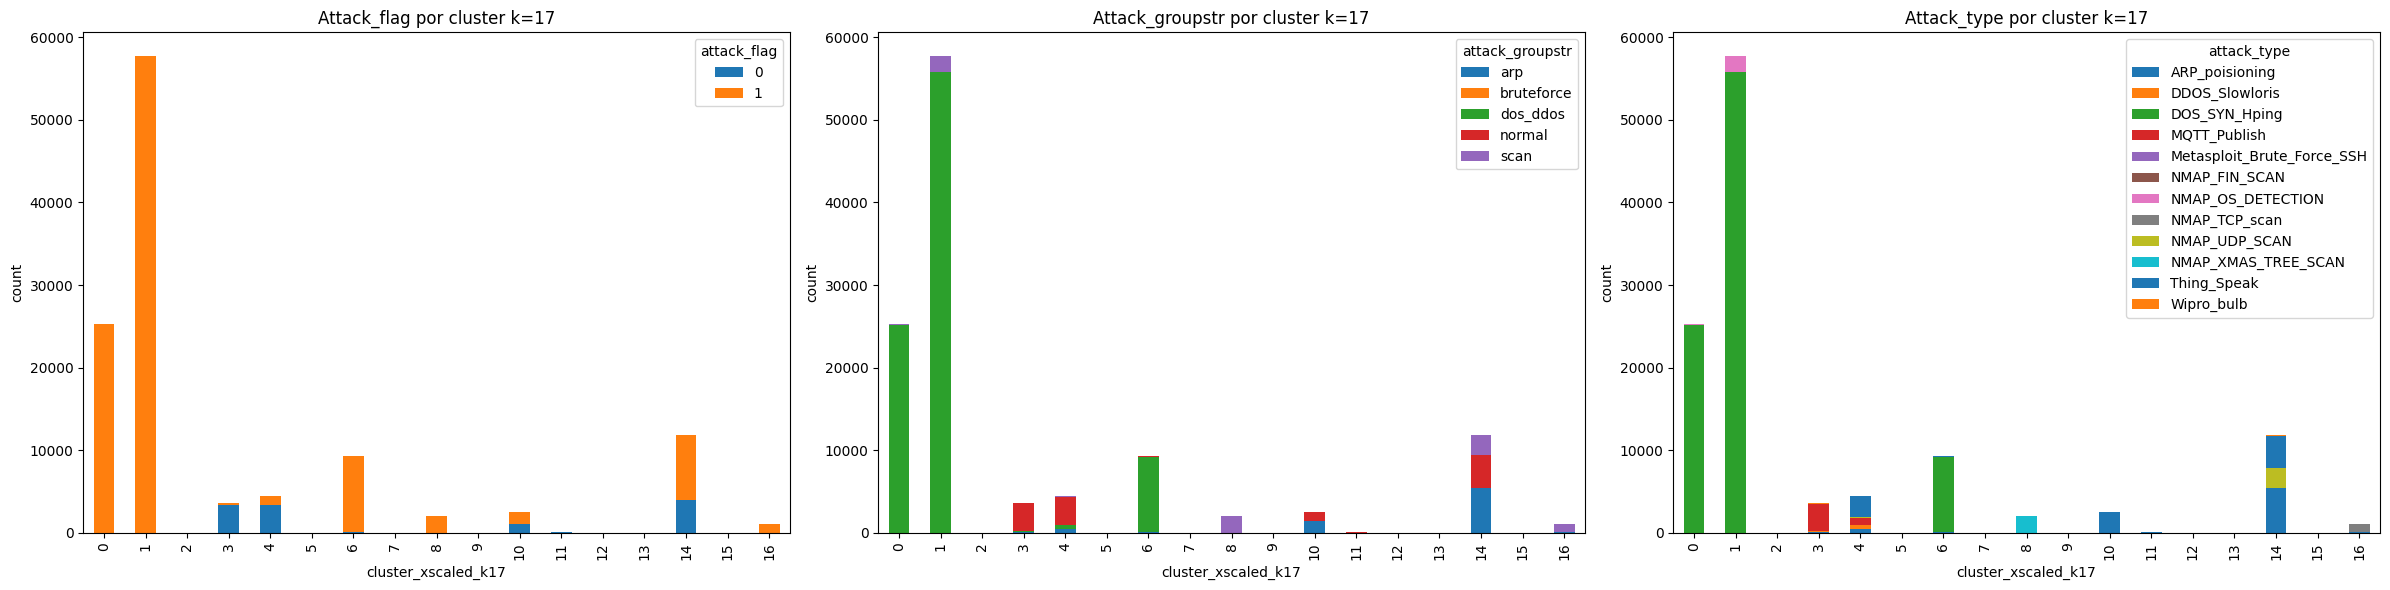

time: 3min 25s (started: 2026-03-22 13:09:57 +00:00)


In [ ]:
k_opt = 17
X_scaled_data = dfc_pca.values

kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled_data)

inn = kmeans.inertia_
sil = silhouette_score(X_scaled_data, labels)
db = davies_bouldin_score(X_scaled_data, labels)
ch = calinski_harabasz_score(X_scaled_data, labels)

print(f"k={k_opt} | inertia={inn:.3f} | silhouette={sil:.3f} | Davies-Bouldin={db:.3f} | Calinski-Harabasz={ch:.3f}")

#clusters en dfc
col_cluster = f"cluster_xscaled_k{k_opt}"
dfc[col_cluster] = labels

#centros en espacio escalado
centers_scaled = kmeans.cluster_centers_

#inverse
cntr_nopca2= pca.inverse_transform(centers_scaled)
centers_orig_aprox = scaler.inverse_transform(cntr_nopca2)

#centros_df
centros_df = pd.DataFrame(centers_orig_aprox, columns=X.columns)
print(f"\nCENTROS_DF k={k_opt}")
display(centros_df.round(2))

#tablas
tabla = pd.crosstab(dfc[col_cluster], dfc["attack_flag"])
tabla2 = pd.crosstab(dfc[col_cluster], dfc["attack_groupstr"])
tabla3 = pd.crosstab(dfc[col_cluster], dfc["attack_type"])

#plots 3 en 1 fila
fig, ax = plt.subplots(1, 3, figsize=(24, 6))

tabla.plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set_xlabel(col_cluster)
ax[0].set_ylabel("count")
ax[0].set_title(f"Attack_flag por cluster k={k_opt}")
ax[0].legend(title="attack_flag")

tabla2.plot(kind="bar", stacked=True, ax=ax[1])
ax[1].set_xlabel(col_cluster)
ax[1].set_ylabel("count")
ax[1].set_title(f"Attack_groupstr por cluster k={k_opt}")
ax[1].legend(title="attack_groupstr")

tabla3.plot(kind="bar", stacked=True, ax=ax[2])
ax[2].set_xlabel(col_cluster)
ax[2].set_ylabel("count")
ax[2].set_title(f"Attack_type por cluster k={k_opt}")
ax[2].legend(title="attack_type")

plt.tight_layout()
plt.show()

#####**COMPARACIÓN POR CENTROIDES DISTANCIA**

---



In [ ]:
dist_centros = cdist(kmeans.cluster_centers_, cntr, metric="euclidean")
dist_centros_df = pd.DataFrame(dist_centros)
display(dist_centros_df.round(3))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,12.119,12.659,4.136,6.669,7.889,2.687,5.319,6.700,12.398,7.556,9.635,8.701,14.974,0.134,14.397,10.561,13.192
1,11.001,11.589,0.157,4.139,5.914,1.317,2.367,4.156,11.445,5.427,8.119,6.974,14.069,4.135,13.417,9.182,12.155
2,788.412,788.473,790.041,789.985,790.125,790.042,790.080,790.031,790.152,790.182,789.545,789.468,788.501,790.059,789.539,789.525,788.560
3,11.303,12.968,11.868,13.269,13.184,12.104,12.192,13.222,16.517,13.528,11.183,7.467,16.363,13.039,1.917,3.527,14.776
4,6.054,7.473,7.531,9.216,9.238,7.899,8.409,9.346,13.519,9.916,1.738,4.476,11.518,9.264,11.675,7.036,9.038
5,139.851,140.296,142.423,142.395,142.459,142.439,142.473,142.441,142.775,142.508,141.756,141.078,141.202,142.526,140.457,140.788,141.082
6,12.511,13.029,5.916,4.625,0.093,6.386,6.275,4.894,12.834,3.953,9.639,9.044,15.704,8.008,14.603,10.829,13.976
7,160.734,160.932,160.874,160.681,160.640,160.891,160.894,160.757,161.273,160.745,161.069,160.691,161.436,160.966,159.827,160.223,161.268
8,16.097,16.729,11.486,11.831,12.848,11.647,11.062,11.667,0.091,12.121,13.803,13.460,18.579,12.449,17.682,14.731,17.221
9,394.867,395.074,398.076,398.058,398.150,398.079,398.134,398.115,398.163,398.228,397.080,396.557,395.520,398.111,396.527,396.600,395.529


time: 58.7 ms (started: 2026-03-22 13:13:23 +00:00)


#####**OTROS**

---



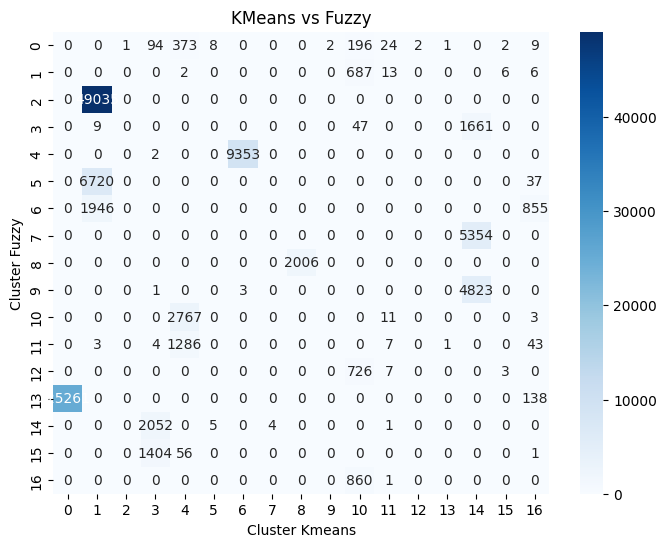

time: 643 ms (started: 2026-03-22 13:13:23 +00:00)


In [ ]:
tabla_kf = pd.crosstab(dfc['cluster_fuzzy'], dfc['cluster_pca_25d'])

plt.figure(figsize=(8, 6))
sns.heatmap(tabla_kf, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Cluster Kmeans")
plt.ylabel("Cluster Fuzzy")
plt.title("KMeans vs Fuzzy")
plt.show()

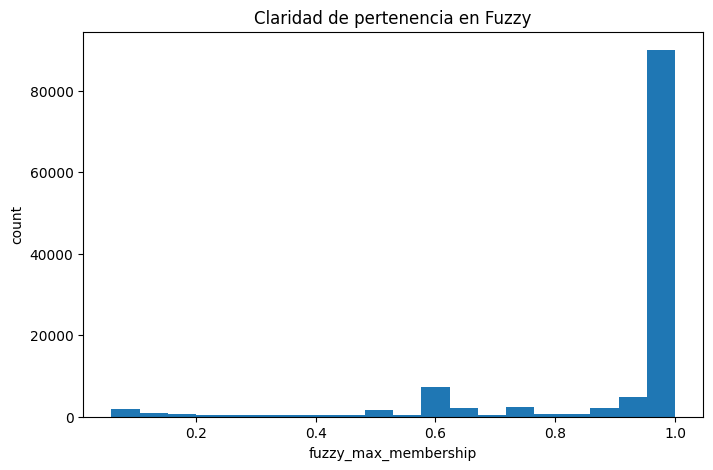

time: 146 ms (started: 2026-03-22 13:13:24 +00:00)


In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(dfc["fuzzy_max_membership"], bins=20)
plt.xlabel("fuzzy_max_membership")
plt.ylabel("count")
plt.title("Claridad de pertenencia en Fuzzy")
plt.show()

####**CONCLUSIONES Y COMPARACIONES FUZZY VS KMEANS**

---



######**CONCLUSIONES TODO EL DATASET**
---
**Se observa que d2 es un grupo muy distinguible y muy bien clasificado por ambos métodos de clustering pero las demás no sufren un destino igual, hay cierta sobrefragmentación y clusteres vacios por parte de los clusteres no difusos, pero también existe una gran pertenencia y nítidez (fpc) en los clusteres fuzzy en anmbos datasets**

######**CONCLUSIONES D2 MITIGADO**
---


**Tanto KMeans como Fuzzy C-Means captaron varias estructuras de datos con patrones evidentes, con similitudes entre ambos métodos, pero no en todo se parecen, ya que éxisten regiones que no explican bien el comportamiento del tráfico y se diferencian mucho de sí.**

**Mientras que el clustering difuso aporto una mejor estructuración y nítidez al no haber tentos overlays, grupos casi vacíos, parte también de culpa por la sobrefragmentación, y grados de pertenencia, Kmeans forzó una única asignación conmuchos interalos vacíos, poco equibrio y escasa nítidez.**

**El histograma de pertenencia máxima confirmó que coexistían dos tipos de observaciones: una gran mayoría de casos muy claros, con puntajes de afiliación ceracno a 1, y una parte menor pero relevante de casos ambiguos, más propios de fronteras entre grupos, explicando en parte la gran distancia entre clusters difusos y no difusos**

**En conjunto, el análisis mostró que no basta con maximizar silhouette, Davies-Bouldin o Calinski-Harabasz. La selección final de k debe equilibrar calidad métrica y gráfica con correspondencia con etiquetas reales, claridad de interpretación y ausencia de sobrefragmentación.**

## **REGRESIÓN/CLASIFICACIÓN ML 75% E INTERPRETABILIDAD XAI**

---



**Regresión: se usa cuando la salida es un valor numérico continuo. Por ejemplo, predecir una duración, una temperatura o un precio. El modelo aprende una cantidad. (continuo)**

**Clasificación: se usa cuando la salida es una clase conocida. Por ejemplo, attack_flag, attack_groupstr o attack_type. El modelo aprende a predecir etiquetas ya definidas. (discreto)**

**Clustering: no usa etiquetas para entrenar. Su objetivo no es acertar una verdad conocida, sino descubrir estructura interna en los datos por métrica. (no supervisado)**

**Nosotros usaremos clasificación ya que queremos predecir a que grupo pertenece el tráfico, y ya de antes hemos reducido el tamaño del datset para que sea proporcional**

**Aunque attack_groupstr y attack_type no se escogieron como variable objetivo principal para la clasificación supervisada, sí se utilizaron en la fase de clustering e interpretación de grupos. De este modo, la clasificación se centrará en el target original de 12 subcalses pero viendo también las otras (binario y multiclase (5))**

In [ ]:
dfc=pd.read_csv(path + "dfanálisis_alld2.csv")

time: 595 ms (started: 2026-03-22 13:13:24 +00:00)


In [ ]:
y=dfc['attack_flag']
ystr=dfc['attack_groupstr']
cols_no_numericas = dfc.select_dtypes(exclude=['number']).columns.tolist()
y_12type=dfc["attack_type"]
X = dfc.drop(columns=["attack_type", "attack_groupstr", "attack_flag"])

time: 14.5 ms (started: 2026-03-22 13:13:25 +00:00)


### **VARS, TEST Y TRAIN**

In [ ]:
target=y_12type.copy()
dataset_train=X.copy()
X_train, X_test, y_train, y_test = train_test_split(dataset_train,target,test_size=0.25, random_state=random_state, stratify=target)

print("Number transactions X_train dataset: ", X_train.shape)
print("Number transactions y_train dataset: ", y_train.shape)
print("Number transactions X_test dataset: ", X_test.shape)
print("Number transactions y_test dataset: ", y_test.shape)

Number transactions X_train dataset:  (88441, 50)
Number transactions y_train dataset:  (88441,)
Number transactions X_test dataset:  (29481, 50)
Number transactions y_test dataset:  (29481,)
time: 163 ms (started: 2026-03-22 13:13:25 +00:00)


#### **BOOL ES MULTICLASE?**

In [ ]:
y_train_use = y_train.iloc[:, 0] if isinstance(y_train, pd.DataFrame) else y_train
if pd.Series(y_train_use).dtype == "object" or str(pd.Series(y_train_use).dtype).startswith("string"): y_train_use = LabelEncoder().fit_transform(y_train_use)
es_multiclase = pd.Series(y_train_use).nunique() > 2

time: 20.9 ms (started: 2026-03-22 13:13:25 +00:00)


#### **LABENCODER YTRAIN STR TO NUMBER**

In [ ]:
y_train_use = y_train.iloc[:, 0] if isinstance(y_train, pd.DataFrame) else y_train
y_test_use = y_test.iloc[:, 0] if isinstance(y_test, pd.DataFrame) else y_test

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_use)
y_test_enc = le.transform(y_test_use)

time: 22.9 ms (started: 2026-03-22 13:13:25 +00:00)


### **MODELOS DE CLASIFICACIÓN**

---



#### **MODELOS A USAR**

In [ ]:
models = []
#lista donde se guardan todos los modelos a probar

models.append(('Logistic Regression', LogisticRegression(solver='liblinear', class_weight='balanced', random_state=random_state)))
#modelo lineal para clasificacion binaria, rapido y bueno como base

models.append(('Random Forest', RandomForestClassifier(n_estimators=100, random_state=random_state)))
#muchos arboles combinados, suele ir bien con relaciones no lineales

models.append(('Extra Trees', ExtraTreesClassifier(n_estimators=100, random_state=random_state)))
#parecido a random forest pero mas aleatorio, rapido y a veces generaliza mejor

models.append(('AdaBoost', AdaBoostClassifier(random_state=random_state)))
#boosting sencillo que da mas peso a errores anteriores para mejorar

models.append(('KNN', KNeighborsClassifier()))
#clasifica segun los vecinos mas cercanos, simple pero sensible a escala y ruido

models.append(('Decision Tree Classifier', DecisionTreeClassifier(random_state=random_state)))
#arbol de decision unico, facil de entender pero puede sobreajustar

models.append(('Gaussian NB', GaussianNB()))
#modelo probabilistico rapido que supone independencia entre variables

models.append(('Linear Discriminant Analysis', LinearDiscriminantAnalysis()))
#modelo lineal que busca separar clases maximizando su diferencia

models.append(('XGBoost', XGBClassifier(objective='multi:softprob', eval_metric='logloss', random_state=random_state, n_jobs=-1)))
#multi:softmax/multi:softprob/binary:logistic
#boosting avanzado muy potente, suele rendir muy bien en clasificacion tabular

#models.append(('SVM', SVC(gamma='auto', probability=True))) #MUY TEDIOSO OJO!!
#busca la mejor frontera de separacion entre clases, util en problemas complejos

models.append(('Gradient Boosting', GradientBoostingClassifier(random_state=random_state)))
#modelo boosting que corrige errores de arboles previos, potente pero mas lento

time: 5.9 ms (started: 2026-03-22 13:13:25 +00:00)


#### **QUÉ MODELO ES MEJOR DE MEDIA**

---



In [ ]:
if clasificacion_accdf_res:
    rows = []
    rows_folds = []
    acc_results = []
    auc_results = []
    names = []

    y_train_use = y_train.iloc[:, 0] if isinstance(y_train, pd.DataFrame) else y_train
    y_train_use = pd.Series(y_train_use)

    n_clases = y_train_use.nunique()
    es_multiclase = n_clases > 2

    if y_train_use.dtype == "object" or str(y_train_use.dtype).startswith("string"):
        le = LabelEncoder()
        y_train_use = le.fit_transform(y_train_use)
        print(f"Target textual detectado. Clases codificadas: {list(le.classes_)}")
    else:
        y_train_use = y_train_use.to_numpy()
        print("Target numérico detectado. No se codifica.")

    scoring_cv = {
        "accuracy": "accuracy",
        "roc_auc": "roc_auc_ovr" if es_multiclase else "roc_auc"
    }

    print(f"Tipo detectado: {'multiclase' if es_multiclase else 'binaria'} | Clases: {n_clases}")
    print(f"Scoring ROC AUC usado: {scoring_cv['roc_auc']}")

    t_total_ini = time.time()

    for i, (name, model) in enumerate(models, start=1):
        print(f"\n[{i}/{len(models)}] Entrenando {name}...")
        t_ini = time.time()

        skfold = model_selection.StratifiedKFold(n_splits=10, shuffle=True, random_state=None)

        try:
            cv_results = model_selection.cross_validate(
                model, X_train, y_train_use, cv=skfold,
                scoring=scoring_cv, n_jobs=-1,
                return_train_score=False, error_score="raise")

            acc_scores = cv_results["test_accuracy"]
            auc_scores = cv_results["test_roc_auc"]

            acc_results.append(acc_scores)
            auc_results.append(auc_scores)
            names.append(name)

            #predicciones OOF para métricas globales
            y_pred_oof = model_selection.cross_val_predict(
                model, X_train, y_train_use, cv=skfold, n_jobs=-1)

            #métricas extra
            mse_val = mean_squared_error(y_train_use, y_pred_oof)
            mae_val = mean_absolute_error(y_train_use, y_pred_oof)
            ari_val = adjusted_rand_score(y_train_use, y_pred_oof)
            nmi_val = normalized_mutual_info_score(y_train_use, y_pred_oof)
            homo_val = homogeneity_score(y_train_use, y_pred_oof)
            comp_val = completeness_score(y_train_use, y_pred_oof)
            v_val = v_measure_score(y_train_use, y_pred_oof)

            rows.append({
                "Algorithm": name, "V Measure": round(v_val, 6),
                "ROC AUC Mean": round(auc_scores.mean() * 100, 3),
                "ROC AUC STD": round(auc_scores.std() * 100, 3),
                "Accuracy Mean": round(acc_scores.mean() * 100, 3),
                "Accuracy STD": round(acc_scores.std() * 100, 3),
                "MSE": round(mse_val, 6),"MAE": round(mae_val, 6),
                "ARI": round(ari_val, 6),"NMI": round(nmi_val, 6),
                "Homogeneity": round(homo_val, 6),"Completeness": round(comp_val, 6)})

            for j in range(len(acc_scores)):
                rows_folds.append({
                    "Algorithm": name,"Fold": j + 1,
                    "Accuracy": acc_scores[j],"ROC AUC": auc_scores[j]})

            t_fin = time.time()
            print(f"OK - {name} | ACC={acc_scores.mean():.4f} | AUC={auc_scores.mean():.4f}")
            print(f"MSE={mse_val:.4f} | MAE={mae_val:.4f}")
            print(f"ARI={ari_val:.4f} | NMI={nmi_val:.4f} | V={v_val:.4f}")
            print(f"Tiempo {name}: {round(t_fin - t_ini, 2)} s")

        except Exception as e:
            t_fin = time.time()
            print(f"ERROR en {name}: {e}")
            print(f"Tiempo hasta error: {round(t_fin - t_ini, 2)} s")

    df_results = pd.DataFrame(rows)
    df_results = df_results.sort_values(by=["ROC AUC Mean"], ascending=False)
    display(df_results)

    nombre_target = y_train.columns[0] if isinstance(y_train, pd.DataFrame) else getattr(y_train, "name", "target")
    nombre_target = str(nombre_target).replace(" ", "_").replace("/", "_")

    df_results.to_csv(path + f"resultados_clasificacion_{nombre_target}.csv", index=False)
    df_folds = pd.DataFrame(rows_folds)
    df_folds.to_csv(path + f"resultados_clasificacion_folds_{nombre_target}.csv", index=False)

    t_total_fin = time.time()
    print(f"\nResultados guardados para target: {nombre_target}")
    print(f"Tiempo total: {round(t_total_fin - t_total_ini, 2)} s")

else:
    nombre_target = y_train.columns[0] if isinstance(y_train, pd.DataFrame) else getattr(y_train, "name", "target")
    nombre_target = str(nombre_target).replace(" ", "_").replace("/", "_")

    df_results = pd.read_csv(path + f"resultados_clasificacion_{nombre_target}.csv")
    df_folds = pd.read_csv(path + f"resultados_clasificacion_folds_{nombre_target}.csv")

    display(df_results)

    names = df_folds["Algorithm"].unique().tolist()
    acc_results = [df_folds[df_folds["Algorithm"] == name]["Accuracy"].values for name in names]
    auc_results = [df_folds[df_folds["Algorithm"] == name]["ROC AUC"].values for name in names]

,Algorithm,V Measure,ROC AUC Mean,ROC AUC STD,Accuracy Mean,Accuracy STD,MSE,MAE,ARI,NMI,Homogeneity,Completeness
0,Extra Trees,0.976545,98.341,1.084,99.534,0.058,0.288565,0.034882,0.998453,0.976545,0.977162,0.975928
1,Random Forest,0.975827,98.247,1.750,99.527,0.074,0.290725,0.035052,0.998391,0.975827,0.976170,0.975484
2,AdaBoost,0.849982,98.184,1.455,95.063,1.625,3.160457,0.351489,0.974329,0.849982,0.830080,0.870863
3,Gradient Boosting,0.968018,97.760,2.368,99.117,0.960,0.360670,0.045431,0.997873,0.968018,0.970789,0.965264
4,Decision Tree Classifier,0.974593,96.906,1.520,99.500,0.042,0.298843,0.036205,0.998311,0.974593,0.975534,0.973654
5,KNN,0.931943,96.443,1.759,98.397,0.186,1.138069,0.129171,0.993488,0.931943,0.927570,0.936358
6,Logistic Regression,0.562050,95.496,0.824,80.235,2.290,6.199613,0.934363,0.689211,0.562050,0.626789,0.509433
7,Linear Discriminant Analysis,0.869366,95.032,1.886,93.844,0.167,4.414333,0.497733,0.983431,0.869366,0.876780,0.862076
8,Gaussian NB,0.518141,94.557,0.605,74.774,0.330,6.064755,1.137267,0.671943,0.518141,0.571458,0.473924
9,XGBoost,0.975822,91.971,16.317,95.946,7.422,0.280413,0.034170,0.998433,0.975822,0.976462,0.975183


time: 527 ms (started: 2026-03-22 13:13:25 +00:00)


#### **GRÁFICOS ACC Y AUC**

---



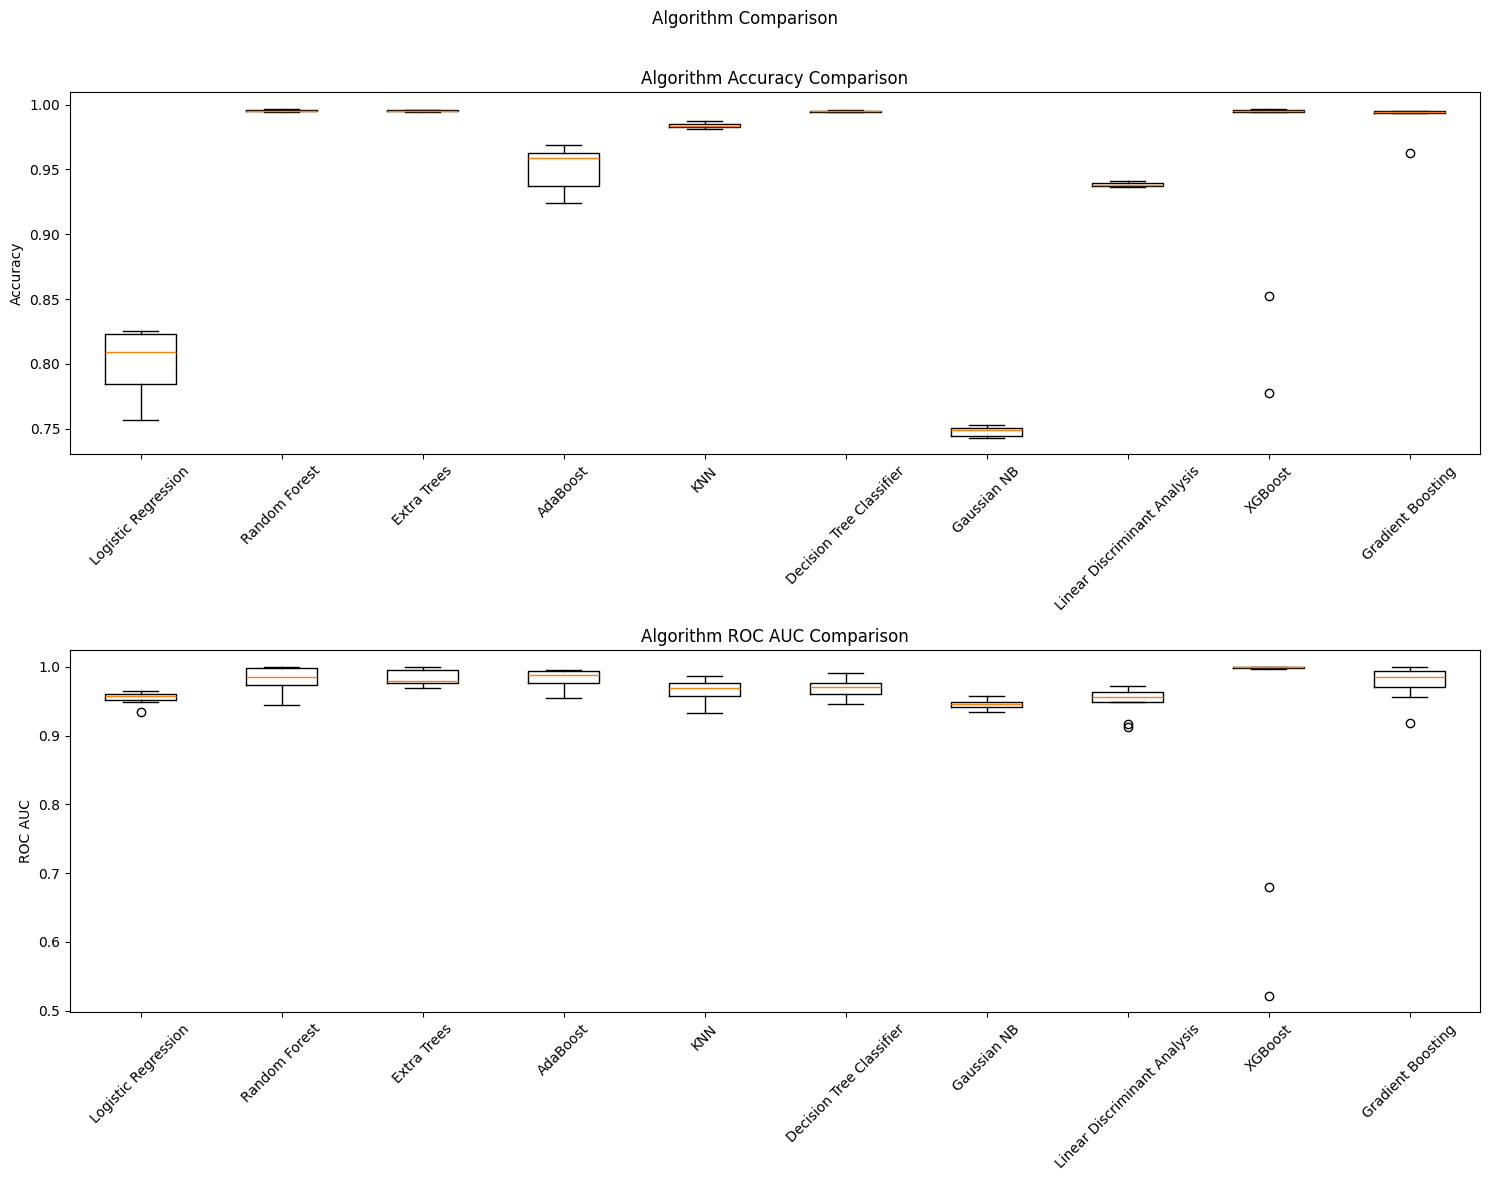

time: 533 ms (started: 2026-03-22 13:13:25 +00:00)


In [ ]:
    fig, ax = plt.subplots(2, 1, figsize=(15, 12))
    fig.suptitle("Algorithm Comparison")

    ax[0].boxplot(acc_results)
    ax[0].set_title("Algorithm Accuracy Comparison")
    ax[0].set_xticklabels(names, rotation=45)
    ax[0].set_ylabel("Accuracy")

    ax[1].boxplot(auc_results)
    ax[1].set_title("Algorithm ROC AUC Comparison")
    ax[1].set_xticklabels(names, rotation=45)
    ax[1].set_ylabel("ROC AUC")

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

#### **QUÉ USAR COMO TARGET**

---



**Para una clasificación con un dataset completo sin d2 mitigado parece que el mejor de todos es Extra Trees con 99.53 acc y 98.38 auc, xgboost parece ganar en la boxplot, pero no se clasifica por los outliers que tiene.**

---

**attack_flag [0,1] muchas al 98.8% ACC, y 99.92% AUC XGBOOST gana casi al 100% clasifica**

**attack_groupstr[normal,arp,scan,ddos,bruteforce] XGBOOST gana con 98.875%**

**attack_type[12 clases/targets originales] XGBOOST GANA CON 98.8% ACC**

**Ya que las 3 tienen el mismo acc y casi las mismas otras métricas, elegiremos el target que más nos de información, osea el attack-type**

**Esto también nos dice que la duración del tráfico, agrupación, y tipo de paquetes que lo conforman son suficientes para determinar casi por completo el tipo y por ende si es o no un ataque y cual exactamente sin ver protocolos o el contenido de estos, y que no hace falta ningún método complicado de probabilidades o árboles, boosting o neighbours, una simple asignación de coeficiente es más que suficiente.**

###**PRUEBA DE MODELOS (XGBOOST/EXTRA TREES) Y COMPARACIÓN DE STATS (BEST_PARAMS)**


In [ ]:
y_train_use = y_train.iloc[:, 0] if isinstance(y_train, pd.DataFrame) else y_train
if pd.Series(y_train_use).dtype == "object" or str(pd.Series(y_train_use).dtype).startswith("string"): y_train_use = LabelEncoder().fit_transform(y_train_use)
n_clases=pd.Series(y_train_use).nunique()
es_multiclase = n_clases > 2

time: 31.7 ms (started: 2026-03-22 13:13:26 +00:00)


In [ ]:
#SE DEFINE EN YX TARGETS!!
kfold = model_selection.StratifiedKFold(n_splits=10, shuffle=True, random_state=None)
if alld2_et:
    modelCV = ExtraTreesClassifier(n_estimators=100, random_state=random_state, n_jobs=-1)
else:
    modelCV = XGBClassifier(objective='multi:softprob' if es_multiclase else 'binary:logistic', eval_metric='mlogloss' if es_multiclase else 'logloss', random_state=random_state, n_jobs=-1)

scoring = 'roc_auc_ovr' if es_multiclase else 'roc_auc'

results = model_selection.cross_val_score(modelCV, X_train, y_train_use, cv=kfold, scoring=scoring)
print(f"Tipo: {'multiclase' if es_multiclase else 'binaria'} | clases={n_clases}")
print("AUC score (STD): %.2f (%.2f)" % (results.mean(), results.std()))

Tipo: multiclase | clases=12
AUC score (STD): 0.98 (0.02)
time: 36.7 s (started: 2026-03-22 13:13:26 +00:00)


**AUC CON TODO D2 = 94%**

In [ ]:
if best_params_xgb_et:
  param_grid = {"max_depth": [3, 5, 7], "n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}
  if alld2_et:
    xgb_et_gs = GridSearchCV(ExtraTreesClassifier(random_state=None, n_jobs=-1), param_grid={"max_depth": [None, 10, 20], "n_estimators": [100, 200], "max_features": ["sqrt", "log2"]}, scoring="roc_auc_ovr" if es_multiclase else "roc_auc", cv=10, return_train_score=True)
  else:
    xgb_et_gs = GridSearchCV(XGBClassifier(objective="multi:softprob" if es_multiclase else "binary:logistic", eval_metric="mlogloss" if es_multiclase else "logloss", random_state=None, n_jobs=-1), param_grid=param_grid, scoring="roc_auc_ovr" if es_multiclase else "roc_auc", cv=10, return_train_score=True)

  xgb_et_grid = xgb_et_gs.fit(X_train, y_train_use)
  xgb_et_opt = xgb_et_grid.best_estimator_; results = xgb_et_gs.cv_results_

  print("=" * 20); print(f"Tipo: {'multiclase' if es_multiclase else 'binaria'}")
  print("best estimator:", xgb_et_gs.best_estimator_); print("best params:", xgb_et_gs.best_params_); print("best score:", xgb_et_gs.best_score_)
  print("=" * 20)

time: 4.15 ms (started: 2026-03-22 13:14:03 +00:00)


**best estimator xgb:** XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

**best params xgb: (probados [param_grid = {"max_depth": [3, 5, 7], "n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}]** {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}, vamos que los máximos estimadores dentro de nuestro rango

**best score xgb: 0.9990644433306779**


---

**best estimator et:** ExtraTreesClassifier(max_depth=10, max_features='log2', n_jobs=-1)

**best params et: {"max_depth": [None, 10, 20], "n_estimators": [100, 200], "max_features": ["sqrt", "log2"]}** {'max_depth': 10, 'max_features': 'log2', 'n_estimators': 100}

**best score et: 0.99690243902678**

###**ENTRENAMIENTO DEL MODELO E INTERPRETABILIDAD XAI (SHAP/LIME/ELI5)**

---



In [ ]:
if es_multiclase:
    if alld2_et:
        xgb_et_opt = ExtraTreesClassifier(max_depth=10, n_estimators=100, max_features="log2", random_state=random_state, n_jobs=-1)
    else:
        xgb_et_opt = XGBClassifier(max_depth=7, n_estimators=200, learning_rate=0.1, objective="multi:softprob", eval_metric="mlogloss", random_state=random_state, n_jobs=-1)
    model=xgb_et_opt.fit(X_train, y_train_enc)
else:
    if alld2_et:
        xgb_et_opt = ExtraTreesClassifier(max_depth=10, n_estimators=100, max_features="log2", random_state=random_state, n_jobs=-1)
    else:
        xgb_et_opt = XGBClassifier(max_depth=7, n_estimators=200, learning_rate=0.1, objective="binary:logistic", eval_metric="logloss", random_state=random_state, n_jobs=-1)
    model=xgb_et_opt.fit(X_train, y_train_enc)

time: 3.36 s (started: 2026-03-22 13:14:03 +00:00)


####**SHAP (GLOBAL VALUES)**

---



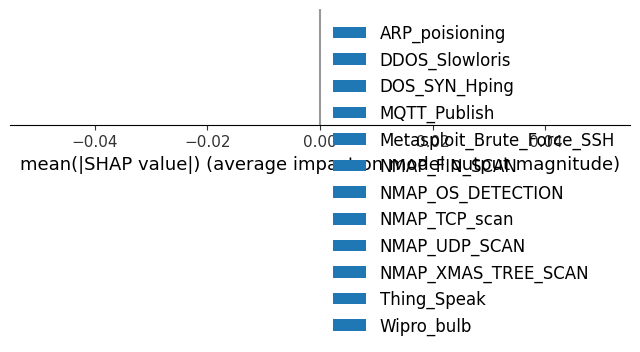

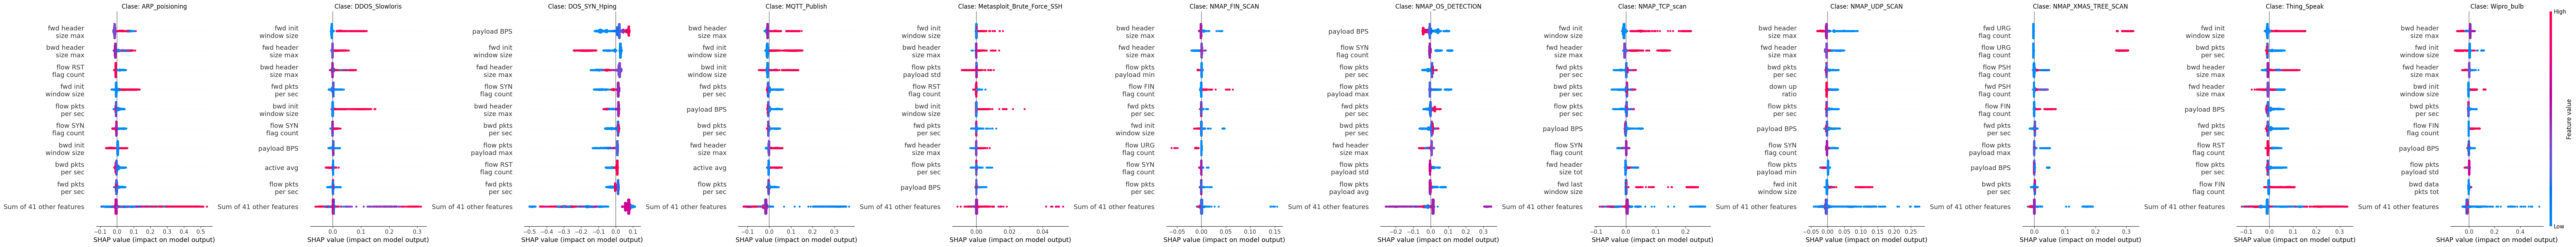

time: 16min 1s (started: 2026-03-22 13:14:06 +00:00)


In [ ]:
target_name = target.columns[0] if hasattr(target, "columns") else (target.name if target.name is not None else "target")
mode_name = "multiclase" if es_multiclase else "bin"

def partir12(nombre, n=2): #xa que se vea bien
    p = str(nombre).split("_")
    return "\n".join([" ".join(p[i:i+n]) for i in range(0, len(p), n)])

if shap_save:
    if alld2_et:
        explainer = shap.Explainer(model.predict_proba, X_train)
        shap_values = explainer(X_test)
    else:
        explainer = shap.Explainer(model, X_train)
        shap_values = explainer(X_test)

    with open(path + f"explainer_{target_name}_{mode_name}.pkl", "wb") as f:
        pickle.dump(explainer, f)

    with open(path + f"shap_values_{target_name}_{mode_name}.pkl", "wb") as f:
        pickle.dump(shap_values, f)

else:
    try:
        with open(path + f"explainer_{target_name}_{mode_name}.pkl", "rb") as f:
            explainer = pickle.load(f)
    except Exception as e:
        print(f"No se pudo cargar explainer, se reconstruye: {e}")
        if alld2_et:
            explainer = shap.Explainer(model.predict_proba, X_train)
        else:
            explainer = shap.Explainer(model, X_train)

    with open(path + f"shap_values_{target_name}_{mode_name}.pkl", "rb") as f:
        shap_values = pickle.load(f)

X_test_plot = X_test.copy()
X_test_plot.columns = [partir12(c, 2) for c in X_test_plot.columns]

if es_multiclase:
    class_names = list(le.classes_)

    #global x clases summary plot
    shap.summary_plot(
        [shap_values[:, :, i] for i in range(len(class_names))] if alld2_et else [shap_values.values[:, :, i] for i in range(len(class_names))],
        X_test_plot,
        class_names=class_names
    )
    plt.show()

    #x clase beeswarm (1 x clase)
    n = len(class_names)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 7), squeeze=False)
    axes = axes.ravel()

    for i_clase, nombre_clase in enumerate(class_names):
        exp_clase = shap.Explanation(
            values=shap_values[:, :, i_clase].values if alld2_et else shap_values.values[:, :, i_clase],
            base_values=shap_values[:, :, i_clase].base_values if alld2_et else shap_values.base_values[:, i_clase],
            data=X_test_plot.values,
            feature_names=X_test_plot.columns.tolist())

        shap.plots.beeswarm(
            exp_clase,
            max_display=10,
            show=False,
            ax=axes[i_clase],
            color_bar=(i_clase == n - 1),
            plot_size=None
        )
        axes[i_clase].set_title(f"Clase: {nombre_clase}")

    plt.tight_layout()
    plt.show()

else:
    shap.summary_plot(shap_values[:, :, 1] if alld2_et else shap_values, X_test_plot)
    plt.show()

#####**SHAP CONCLUSIÓN**

Se rompe con una muestra grande multiclase pero no el beeswarm.

Shap nos permite ver como los patrones son percibidos por el modelo, con que peso se percibe cada dimensión de forma global y con lime los casos específicos y pruebas concretas. Los más notables fueron dimensiones temporales y volumétricas sin depender de una en concreto sino del conjunto, como el último tamaño de ventana forward (fwd last window size), el tiempo mínimo entre paquetes del flujo (flow iat min), los bytes del subflujo forward (fwd subflow bytes), los bytes de payload por segundo (payload BPS), el payload mínimo de los paquetes del flujo (flow pkts payload min) y los paquetes backward por segundo (bwd pkts per sec).

**ARP_poisioning**

En ARP_poisioning, se favorecieron valores altos del payload mínimo de los paquetes del flujo (flow pkts payload min), bajos del tiempo mínimo entre paquetes del flujo (flow iat min) y de la actividad media (active avg). Esto tiene sentido porque normalmente se basa en tramas pequeñas, repetitivas, muy frecuentes y dirigidos.

**D2**

DDOS_Slowloris se favorece de valores altos del tamaño inicial de ventana backward (bwd init window size), el payload máximo de los paquetes del flujo (flow pkts payload max) y de la desviación típica del tiempo entre paquetes del flujo (flow iat std). Esto es normal ya que slowris se basa en mantener patroner temporales ireregulares y conexiones abiertas por más tiempo en vez de mandar gran cantidad de datos e inundar.

DOS_SYN_Hping se diferencia más por valores altos de Bps de (payload BPS), más los bytes del subflujo forward (fwd subflow bytes), la duración del flujo (flow duration) y el número de banderas SYN del flujo (flow SYN flag count). Esto concuerda con este ataque que de primeras usa paquetes SYN y su objetivo es la concentración de envios volumétricos en poco tiempo.

**Bruteforce**

La clase Metasploit_Brute_Force_SSH mostró más patrones mixtos que concluyentes aunque destacarón los que tienen que ver con un compoprtamiento de muchos intentos consecutivos, pausas variables, repeticiones y no mucho volumen: actividad media (active avg), payload mínimo y total de los paquetes del flujo (flow pkts payload min/tot), el payload total de los paquetes del flujo y el tiempo máximo entre paquetes del flujo (flow iat max).

**Tráfico normal**

Para cada tipo de tráfico existen diferentes pàtrones que debemos de estudiar, dependiendo de cada tipo podríamos estudiarlo en grupo o uno por uno, en el caso de tráfico normal, puede ser mejor. Aunque se encuentran patrones de comportamiento en la mayoría del táfico normal, al introducir más dispositivos, redes o entornos simplemente hay que acostumbrar esos nuevos comportamientos a un nuevo estudio y sumarles con los hallazgos de este.

El altavoz (Thing_Speak) se favoreció por el alto tiempo mínimo entre paquetes del flujo (flow iat min), los bytes del subflujo backward (bwd subflow bytes) y del último tamaño de ventana forward (fwd last window size). Coincidiendo con un patrón espaciado y tranquilo en vez de uno agresivo.

Wipro_bulb presentó un patrón apoyado sobre todo por valores altos del tiempo mínimo entre paquetes del flujo (flow iat min), el tamaño inicial de ventana backward (bwd init window size) y el último tamaño de ventana forward (fwd last window size), comportamiento de tráfico más regular y estable.

En MQTT_Publish, importaron el payload medio de los paquetes del flujo (flow pkts payload avg), los bytes del subflujo forward (fwd subflow bytes), el último tamaño de ventana forward (fwd last window size), y la actividad media y total (active avg/tot) y la actividad total (active tot), normal para un sensor de temperatura con mensajes de temperatura hacia un server, con actividad frecuente y noralmente en una sola dirección.


**Escaneos**

NMAP_UDP_SCAN se asocia con valores bajos del total de paquetes backward (bwd pkts tot) y del tamaño total de cabecera backward (bwd header size tot), y altos xa payload mínimo de los paquetes del flujo (flow pkts payload min). Esto tiene sentido porque el escaneo UDP suele basarse en sondas breves, ligeras y con poca o nula respuesta por parte del destino.

NMAP_FIN_SCAN se identificó por valores altos del número de banderas FIN del flujo (flow FIN flag count), último tamaño de ventana forward (fwd last window size) y del tiempo mínimo entre paquetes del flujo (flow iat min). Normal ya que consiste en enviar paquetes FIN para observar cómo responde el sistema sin seguir una conexión estándar.

NMAP_OS_DETECTION se dominó por el último tamaño de ventana forward (fwd last window size), los paquetes backward por segundo (bwd pkts per sec), pero bajos del número de banderas FIN del flujo (flow FIN flag count) y del tamaño inicial de ventana forward (fwd init window size), esto es porque la detección de sistema operativo no comprueba puertos, sino provocar respuestas concretas que revelen rasgos de la pila TCP/IP del host, por eso su apoyo en variables de ventanas, ritmo de respuesta  y paquetes fin.

NMAP_TCP_SCAN se diferenció por valores altos del último tamaño de ventana forward (fwd last window size), del tamaño máximo de cabecera forward (fwd header size max), noermal cuando el objetivo no es transferir datos, sino provocar respuestas concretas del objetivo y ver cómo se comporta la comunicación a nivel de cabeceras y sesión.

####**ELI5 MODELO PESOS Y ERROR**

---



,feature,weight,std
0,fwd_header_size_max,0.035380,0.000405
1,payload_BPS,0.026596,0.000203
2,bwd_pkts_per_sec,0.025495,0.000123
3,flow_SYN_flag_count,0.015522,0.000202
4,bwd_header_size_max,0.013394,0.000075
5,flow_pkts_payload_max,0.002483,0.000171
6,flow_pkts_payload_min,0.001764,0.000111
7,fwd_URG_flag_count,0.001409,0.000132
8,bwd_init_window_size,0.001339,0.000120
9,fwd_init_window_size,0.001327,0.000144


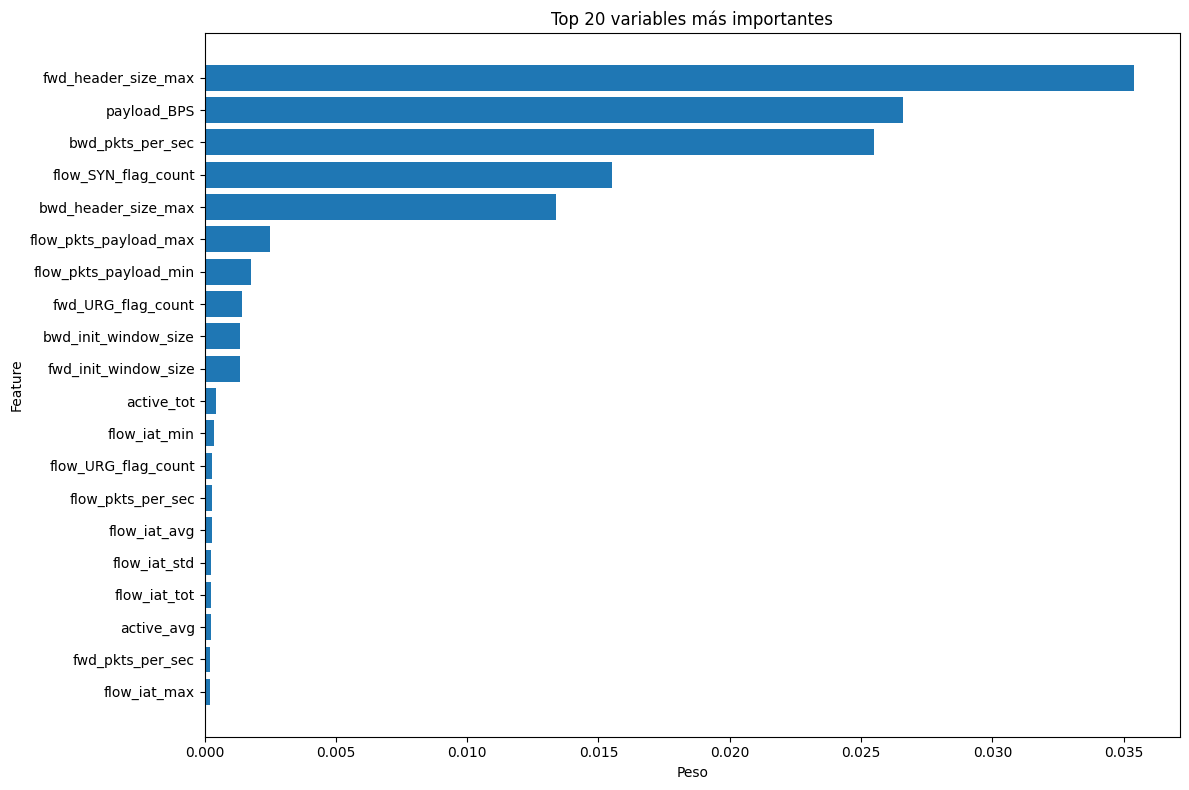

time: 613 ms (started: 2026-03-22 13:30:08 +00:00)


In [ ]:
if csv_eli5_weights:
    features_list = X_train.columns.tolist()
    feat_permut = PermutationImportance(xgb_et_opt, random_state=random_state).fit(X_train, y_train_enc)
    df_eli5 = eli5.explain_weights_df(feat_permut, feature_names=features_list)
    df_eli5.to_csv(path + "eli5_weights_xgb_et_opt.csv", index=False)
else:
    df_eli5 = pd.read_csv(path + "eli5_weights_xgb_et_opt.csv")

display(df_eli5)

n=20
df_eli5_top = df_eli5.head(n).iloc[::-1]

plt.figure(figsize=(12, 8))
plt.barh(df_eli5_top["feature"], df_eli5_top["weight"])
plt.xlabel("Peso")
plt.ylabel("Feature")
plt.title(f"Top {n} variables más importantes")
plt.tight_layout()
plt.show()

####**LIME (LOCAL VALUES ONLY)**

Clase predicha: NMAP_XMAS_TREE_SCAN
Probabilidades: [2.31140602e-03 2.25631769e-06 1.38246059e-02 1.55518955e-05
 3.94855596e-06 2.88893553e-04 1.39992905e-02 2.27055992e-07
 1.03847022e-03 9.66638139e-01 1.70318283e-03 1.74028569e-04]


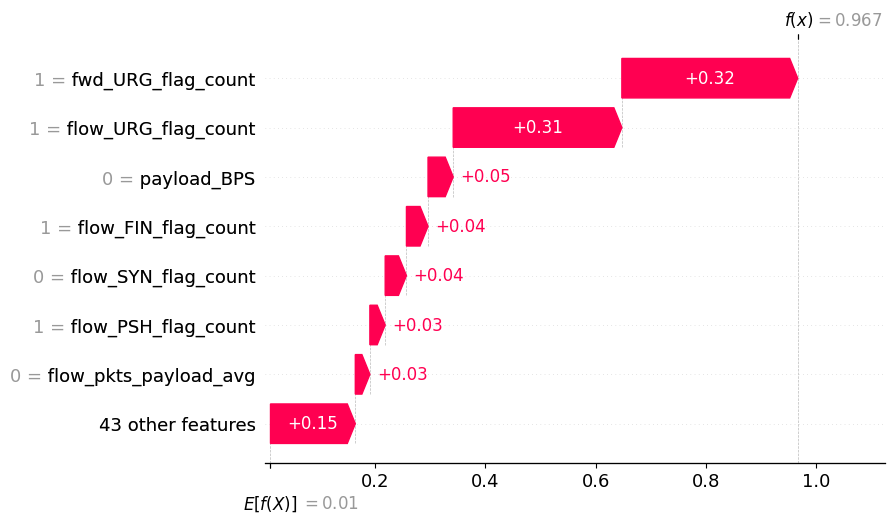

time: 2.4 s (started: 2026-03-22 13:30:08 +00:00)


In [ ]:
#exportar_html_lime_caso=True
i=2000
num_features=10

probs=model.predict_proba(X_test.iloc[[i]])[0]
pred=np.argmax(probs)

if es_multiclase:
    class_names=list(le.classes_) if "le" in globals() else [str(c) for c in range(len(probs))]
else:
    class_names=["No","Sí"] if len(probs)==2 else [str(c) for c in range(len(probs))]

print("Clase predicha:",class_names[pred])
print("Probabilidades:",probs)

#SHAP local
if "shap_values" not in globals():
    if alld2_et:
        explainer=shap.Explainer(model.predict_proba,X_train)
    else:
        explainer=shap.Explainer(model,X_train)
    shap_values=explainer(X_test)

if es_multiclase:
    if alld2_et:
        exp=shap.Explanation(
            values=shap_values[i,:,pred].values,
            base_values=shap_values[i,:,pred].base_values,
            data=X_test.iloc[i,:].values,
            feature_names=X_test.columns.tolist()
        )
    else:
        exp=shap.Explanation(
            values=shap_values.values[i,:,pred],
            base_values=shap_values.base_values[i,pred],
            data=X_test.iloc[i,:].values,
            feature_names=X_test.columns.tolist()
        )
else:
    if alld2_et:
        exp=shap.Explanation(
            values=shap_values[i,:,1].values if len(probs)==2 else shap_values[i,:,pred].values,
            base_values=shap_values[i,:,1].base_values if len(probs)==2 else shap_values[i,:,pred].base_values,
            data=X_test.iloc[i,:].values,
            feature_names=X_test.columns.tolist()
        )
    else:
        exp=shap.Explanation(
            values=shap_values.values[i,:],
            base_values=shap_values.base_values[i],
            data=X_test.iloc[i,:].values,
            feature_names=X_test.columns.tolist()
        )

shap.plots.waterfall(exp,max_display=8)
plt.show()

#LIME local
lime_explainer=lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=class_names,
    mode="classification"
)

lime_exp=lime_explainer.explain_instance(
    X_test.iloc[i].values,
    model.predict_proba,
    num_features=num_features
)

display(HTML(lime_exp.as_html()))

if exportar_html_lime_caso:
    target_name=target.columns[0] if hasattr(target,"columns") else (target.name if getattr(target,"name",None) is not None else "target")
    mode_name="multiclase" if es_multiclase else "bin"
    file_html=path+f"lime_{target_name}_{mode_name}_fila_{i}.html"
    with open(file_html,"w",encoding="utf-8") as f:
        f.write(lime_exp.as_html())
    print("HTML guardado en:",file_html)

In [ ]:
#exportar_html_lime_caso=True
#pongo con las medianas
nombre_html="lime_explicacion.html"
cols=X_train.columns.tolist()
defaults=X_train[cols].median().tolist()

def explain_instance_with_lime(*vals):
    x=pd.DataFrame([vals],columns=cols)
    probs=model.predict_proba(x)[0]
    pred=int(np.argmax(probs))

    if es_multiclase:
        class_names=list(le.classes_) if "le" in globals() else [str(i) for i in range(len(probs))]
    else:
        class_names=["No","Sí"] if len(probs)==2 else [str(i) for i in range(len(probs))]

    lime_exp=lime_explainer.explain_instance(x.iloc[0].values,model.predict_proba,num_features=10)
    try:
        pares=lime_exp.as_list(label=pred)
    except:
        pares=lime_exp.as_list()

    barras="".join([f"<tr><td>{html.escape(str(k))}</td><td>{v:.4f}</td></tr>" for k,v in pares])
    probs_html="".join([f"<tr><td>{html.escape(str(class_names[i]))}</td><td>{float(p):.4f}</td></tr>" for i,p in enumerate(probs)])

    preview_html=f"""
    <div style="font-family:Arial;padding:10px">
      <h3 style="margin:0 0 10px 0">Explicación LIME</h3>
      <p><b>Clase predicha:</b> {html.escape(str(class_names[pred]))}</p>
      <h4 style="margin:10px 0 6px 0">Probabilidades</h4>
      <table style="border-collapse:collapse;width:420px">
        <tr><th style="text-align:left;border-bottom:1px solid #ccc">Clase</th><th style="text-align:left;border-bottom:1px solid #ccc">Prob.</th></tr>
        {probs_html}
      </table>
      <h4 style="margin:14px 0 6px 0">Variables más influyentes</h4>
      <table style="border-collapse:collapse;width:700px">
        <tr><th style="text-align:left;border-bottom:1px solid #ccc">Feature</th><th style="text-align:left;border-bottom:1px solid #ccc">Peso LIME</th></tr>
        {barras}
      </table>
    </div>
    """

    file_html=None
    if exportar_html_lime_caso:
        file_html=os.path.join(path,nombre_html)
        with open(file_html,"w",encoding="utf-8") as f:
            f.write(lime_exp.as_html())

    return preview_html,file_html

interface=gr.Interface(
    fn=explain_instance_with_lime,
    inputs=[gr.Number(label=c,value=float(v)) for c,v in zip(cols,defaults)],
    outputs=[gr.HTML(label="Vista previa LIME"),gr.File(label="HTML")],
    title="Explicación LIME",
    flagging_mode="never",
    submit_btn="Explicar",
    clear_btn="Limpiar"
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fc331723630c52d926.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


time: 2.79 s (started: 2026-03-22 13:30:11 +00:00)


###**CONFUSION MATRIX XGBOOST/EXTRA TREES TEST**

---



ovr = one-vs-rest

ovo = one-vs-one

**TP FP**

**FN TN**

**fila fn y columna fp**

AUC score: 0.999


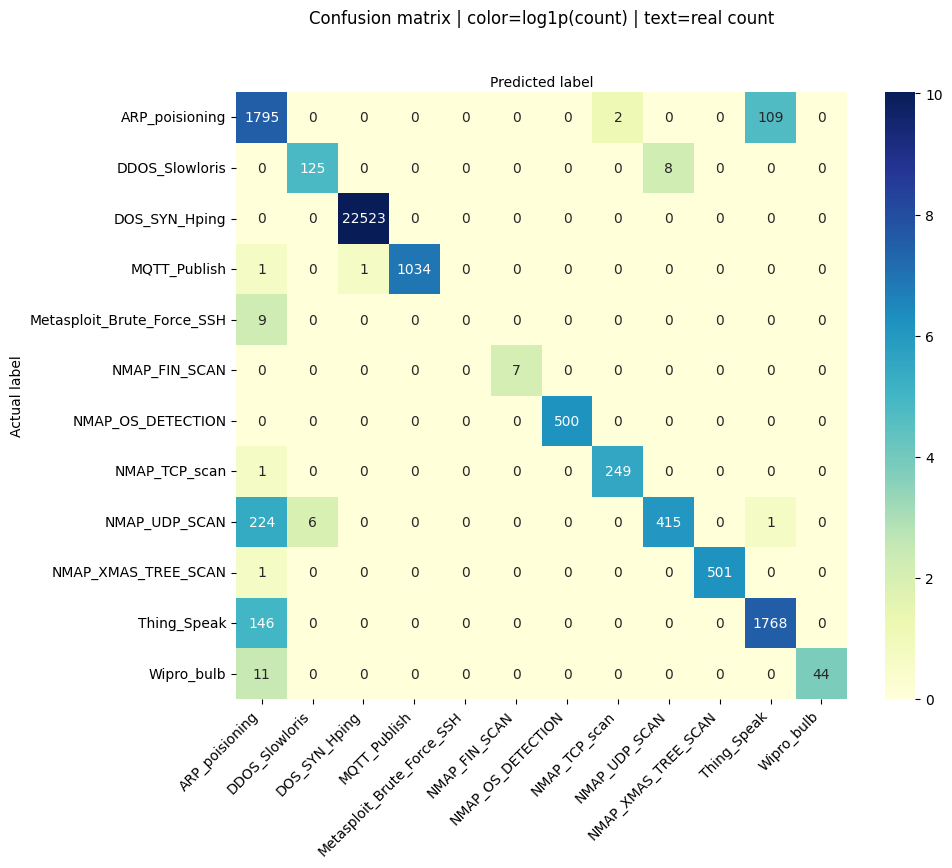

time: 3.59 s (started: 2026-03-22 13:30:13 +00:00)


In [ ]:
xgb_et_opt.fit(X_train, y_train_enc)

if es_multiclase:
    probs = xgb_et_opt.predict_proba(X_test)
    xgb_roc_auc = roc_auc_score(y_test_enc, probs, multi_class="ovr")
else:
    probs = xgb_et_opt.predict_proba(X_test)[:, 1]
    xgb_roc_auc = roc_auc_score(y_test_enc, probs)

print('AUC score: %.3f' % xgb_roc_auc)

cnf_matrix = sk_metrics.confusion_matrix(y_test_enc, xgb_et_opt.predict(X_test))
class_names = le.inverse_transform(np.arange(len(le.classes_)))
cnf_matrix_log = np.log1p(cnf_matrix)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cnf_matrix_log, annot=cnf_matrix, cmap="YlGnBu", fmt='g',
    xticklabels=class_names, yticklabels=class_names
)

ax.xaxis.set_label_position("top")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.title('Confusion matrix logs', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

###**REPORTE XGBOOST/EXTRA TREES TEST**

---



In [ ]:
y_pred = xgb_et_opt.predict(X_test)

if es_multiclase:
    print("Classification report - multiclase")
    print(classification_report(y_test_enc, y_pred, target_names=le.classes_))
else:
    print("Classification report - binaria")
    print(classification_report(y_test_enc, y_pred))

Classification report - multiclase
                            precision    recall  f1-score   support

            ARP_poisioning       0.82      0.94      0.88      1906
            DDOS_Slowloris       0.95      0.94      0.95       133
             DOS_SYN_Hping       1.00      1.00      1.00     22523
              MQTT_Publish       1.00      1.00      1.00      1036
Metasploit_Brute_Force_SSH       0.00      0.00      0.00         9
             NMAP_FIN_SCAN       1.00      1.00      1.00         7
         NMAP_OS_DETECTION       1.00      1.00      1.00       500
             NMAP_TCP_scan       0.99      1.00      0.99       250
             NMAP_UDP_SCAN       0.98      0.64      0.78       646
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       502
               Thing_Speak       0.94      0.92      0.93      1914
                Wipro_bulb       1.00      0.80      0.89        55

                  accuracy                           0.98     29481
           

###**IMPORTANCIA DIMENSIONES XGBOOST/EXTRA TREES Y CURVA ROC AUC**

---



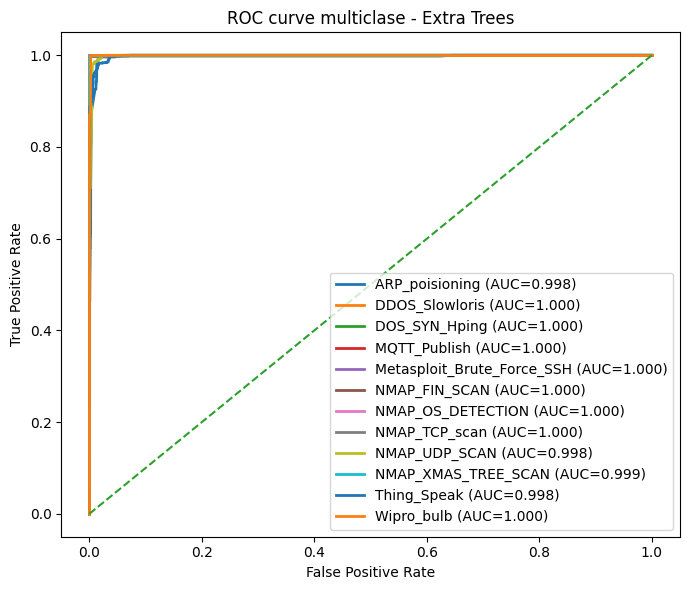

AUC score: 0.999


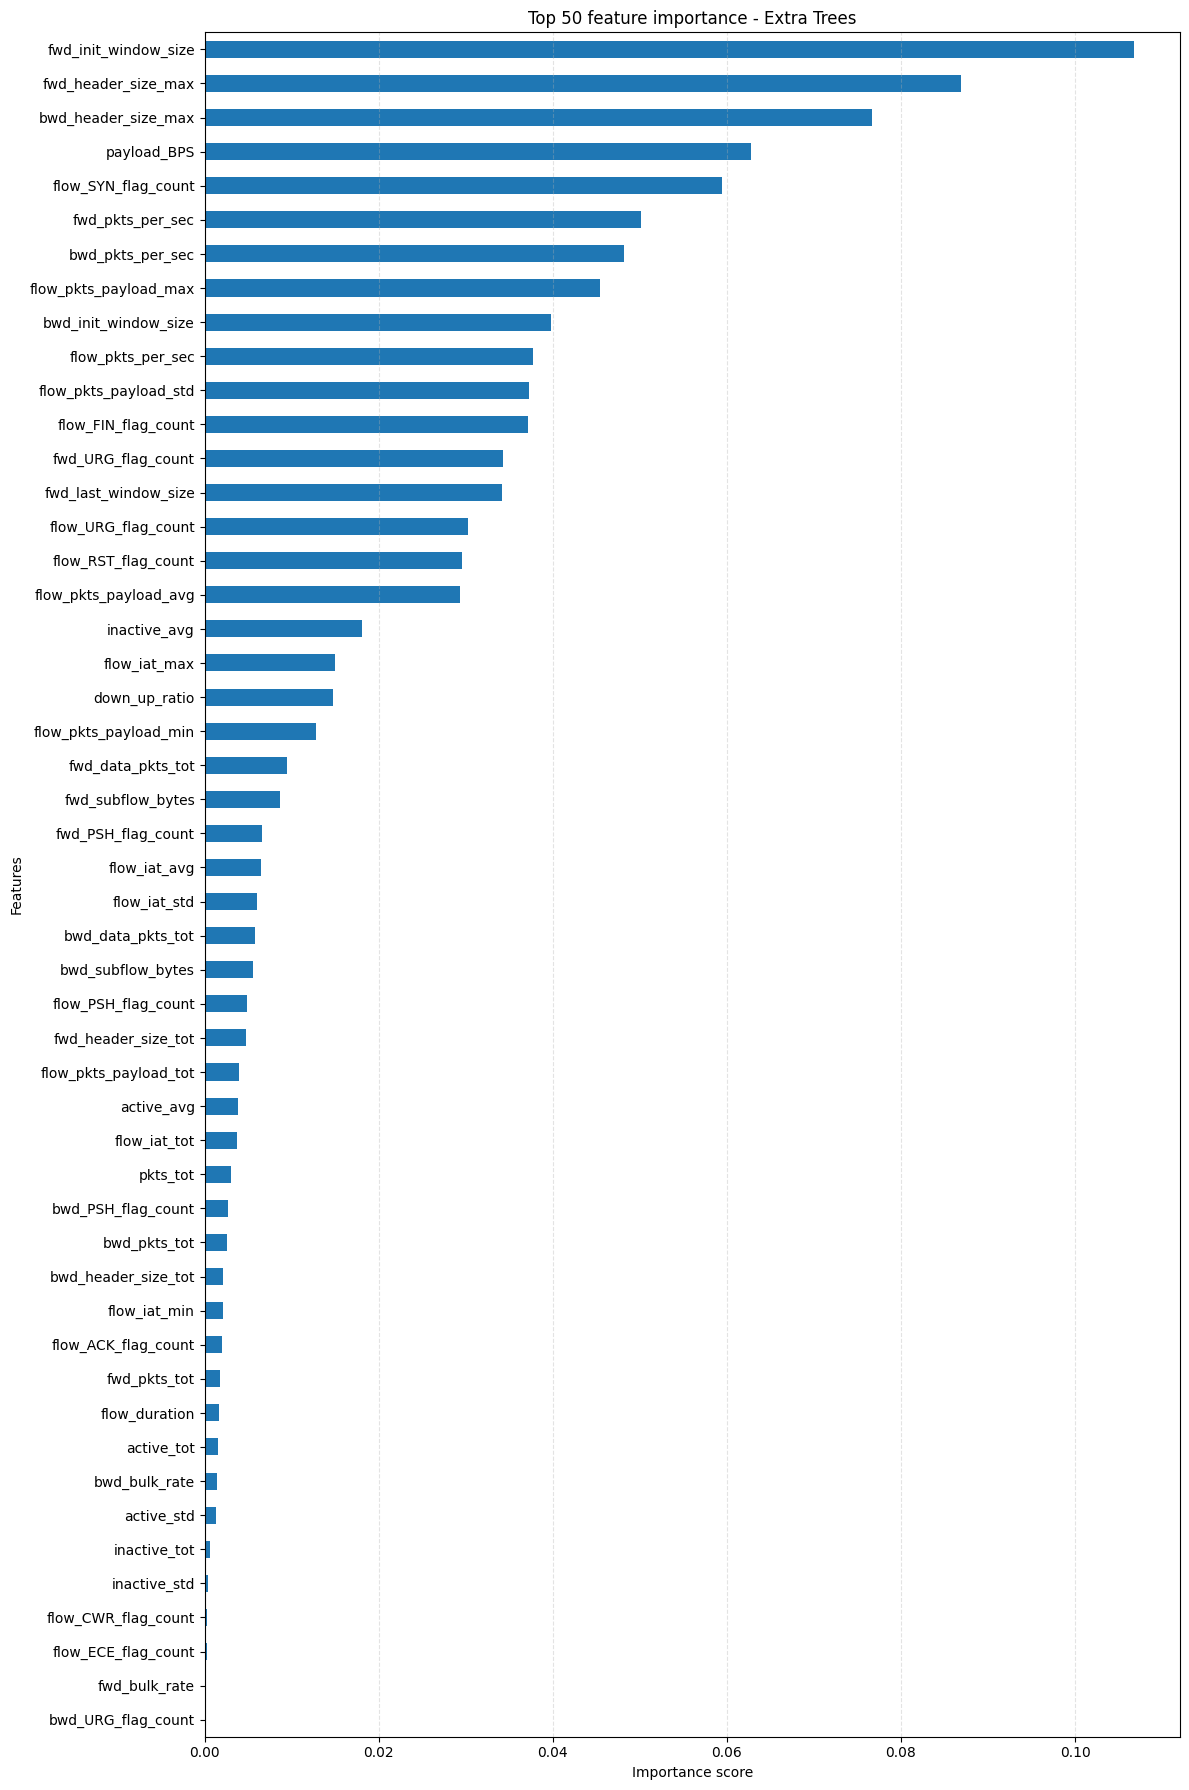

time: 1.36 s (started: 2026-03-22 13:30:17 +00:00)


In [ ]:
if es_multiclase:
    probs = xgb_et_opt.predict_proba(X_test)
    xgb_auc = roc_auc_score(y_test_enc, probs, multi_class="ovr")
    n_classes = probs.shape[1]

    #binarizar y real
    y_test_bin = label_binarize(y_test_enc, classes=np.arange(len(le.classes_)))

    plt.figure(figsize=(7, 6))

    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, linewidth=2, label=f"{le.classes_[i]} (AUC={roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], '--')
    plt.title("ROC curve multiclase - Extra Trees" if alld2_et else "ROC curve multiclase - XGBoost")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    probs = xgb_et_opt.predict_proba(X_test)[:, 1]
    xgb_auc = roc_auc_score(y_test_enc, probs)
    plt.figure(figsize=(6, 5)); plt.plot(*roc_curve(y_test_enc, probs)[:2], linewidth=2); plt.plot([0, 1], [0, 1], '--')
    plt.title("ROC curve - Extra Trees" if alld2_et else "ROC curve - XGBoost"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.tight_layout(); plt.show()

print('AUC score: %.3f' % xgb_auc)

imp = pd.Series(xgb_et_opt.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(50)
fig, ax = plt.subplots(figsize=(12, 18))
imp.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 50 feature importance - Extra Trees" if alld2_et else "Top 50 feature importance - XGBoost")
ax.set_xlabel("Importance score"); ax.set_ylabel("Features")
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout(); plt.show()

###**CONCLUSIONES CLASIFICACIÓN**

---




Se evaluaron tres targets con distinto nivel de agregación: uno binario, uno de cinco clases y el target original de 12 tipos de tráfico, pero anteriormente se redújo la cantidad de uno de los grupos en proporción a los demás, con el fin de realizar una exploración con mejores resultados (d2).

Se han detectado problemas con bruteforce y algunos escaneos nmap, pero las métricas nos indican que nustros resultados aciertan de manera sobresaliente el tráfico solo con patrones temporales y de carga, indicando que con ayuda de protocolo y tipo de tráfico aumentaría casi al 100%, pero hayq ue tener en cuenta que esto es un entorno simulado y no contituye el tráfico real de una institución, pero se puede usar igual para la mayoría de casos de esta y siguiendo el mismo proceso podemos con su propio historial acotar y sumar la búsqueda de tráfico malicioso en esta misma.

**TARGET BINARIO**

En el target binario, el modelo mostró un comportamiento prácticamente perfecto. Se obtuvo un recall del 99%, un F1-score del 99%, una precisión del 100% y un área bajo la curva ROC igual a 1, indicando una separación casi total de ambas clases. La matriz de confusión lo confirmó con solo 24 falsos positivos y 9 falsos negativos.

Con el 50% del peso e importancia, la dimension más importante fue el tiempo total de flujo entre paquetes (iat), seguido del flujo de paquetes RST y señales de congestión CWR. Esto sugiere que existe un gran patrón temporal, y cierre de comunicación abrupto junto a la posibilidad de congestión de tráfico por la gran cantidad de paquetes.

**TARGET MULTICLASE (5 GRUPOS)**

Con un target multiclase general por grupo de ataque, la precisión se mantuvo al 97% en casi todas las clases, excepto en BruteForce, donde descendió debido a su escaso número de casos (1/1000). El recall fue de 96% o superior en casi todas las clases, excepto bruteforce con 90%, y F1-score fue de 97% o más para la mayoría, mientras que BruteForce se quedó con 84%.

Con la matriz de confusión, se detectaton varios problemas sobre todo con ARP poisoning, con 58 casos confundidos con escaneos y 21 casos clasificados como tráfico normal, esto sugiere la similitud de ciertos rasgos entre ambos, como un gran número de paquetes cortos.

En cuanto a importancia de dimensiones, cambiaron respecto a las del target binario, se ha sustituido la importancia temporal con el ratio con peso en el flujo: total de paquetes de datos del flujo, kBs de payload y total de paquetes con payload del flujo, aunque otros comportamientos siguen presentes como RST y aparecen otras coo ACK. Se ha pasado ahora a un patrón de intensidad, ratio, y carga mientras que la variable temporal, aunque aún presente, no conserva tal importancia.

**TARGET MULTICLASE ORIGINAL, (12 TIPOS)**

Con el target que tiene todos los tipos de tráfico, se mantuvo estable para casi todas las clases pero confunde algunas otras.

La matriz de confusión profundiza más en el problema de Arp poissoning, con 60 casos de ARP falsos negativos hacia escaneo UDP, y falsos en ambos sentidos entre el altavoz (normal) y este, reforzando la idea de parecido en etstructuras y patrones de tráfico posible no benigno.

La variable con mayor peso, al cambiar el target a uno más específico, fue el número de paquetes urgentes con 30%, luego el total de paquetes recibidos con un 15% y en tercera y cuarta posición el ancho de ventana. Ahora dimensiones que antes condicionaban por completo la clase.

En las métricas como recall ó F1-score se observarón  que para la mayoría de claseesó una pauta similar, incorporándose además clases como Nmap OS y WebUI/Bulb y nmap ping entre las más delicadas o informativas según el contexto.

###**INTERPRETABILIDAD XAI CONCLUSIONES**

---



El modelo distinguió bien los grupos por patrones de tiempo, ritmo, ventanas y respuesta y no por una sola variable aislada

En el **tráfico normal** es estable, regular y poco agresivo, por payload normalmente bajo o moderado, tiempos entre paquetes más altos y un ritmo más regular, **en los escaneos** hubo mucho tráfico ligero, poco intercambio real de datos y búsqueda de respuesta del host, pero cada uno con siferencia propia, ya que **NMAP_UDP_SCAN** destacó por poca o nula respuesta backward, **NMAP_FIN_SCAN** por la presencia de pakts FIN, **NMAP_OS_DETECTION** por variables de ventana y ritmo de respuesta al intentar revelar rasgos de la pila TCP/IP y **NMAP_TCP_SCAN** por cabeceras y estructura de sesión más que por volumen, en **D2** ambos compartieron rasgos temporales y de presión sobre el flujo, **DDOS_Slowloris** es más de conexiones abiertas, ritmos irregulares y menos inundación directa, mientras **DOS_SYN_Hping** se asoció más a envíos rápidos, volumétricos y al uso claro de paquetes SYN, por lo que su comportamiento fue más brusco y concentrado. En **ARP_poisioning**, tiene un patrón de tramas pequeñas, repetitivas y muy frecuentes, favorecido por valores altos del payload mínimo de los paquetes del flujo (flow pkts payload min) y bajos del tiempo mínimo entre paquetes del flujo (flow iat min) y de la actividad media (active avg). **Brute_Force_SSH**, tiene un patrón de muchos intentos consecutivos, pausas variables, repeticiones y no demasiado volumen, por ende, más en actividad media (active avg), payload mínimo y total de los paquetes del flujo (flow pkts payload min/tot) y en el tiempo máximo entre paquetes del flujo (flow iat max).

## **TIEMPO TOTAL EJECUCIÓN IPYNB**

---

In [ ]:
transcurrido = time.time() - inicio_ipynb
print(f"Tiempo total del notebook: {transcurrido:.2f} s")

Tiempo total del notebook: 1637.09 s
time: 3.43 ms (started: 2026-03-22 13:30:19 +00:00)
